In [1]:
import os
import sys
import pickle
import random
import numpy as np
import torch
from torch_geometric.loader import DataLoader

In [2]:
BASE_DIR = r"d:\git_repos\capstone\explainability"
PARENT_DIR = os.path.dirname(BASE_DIR)
GT_DIR = os.path.join(PARENT_DIR, "graph-transformer")
AD_DIR = os.path.join(PARENT_DIR, "attack-detection")

for p in (GT_DIR, AD_DIR, BASE_DIR, PARENT_DIR):
    if p not in sys.path:
        sys.path.insert(0, p)

def load_project_modules():
    from model import GraphTransformerAutoencoder, ModelConfig
    from train import align_graph_feature_dim
    from evaluate import restore_or_split_graphs
    from detector import ZeroDayDetector, RiskState
    from scorer import AnomalyScorerConfig
    from report_generator import ReportGenerator, SecurityIncidentReport
    return {
        "GraphTransformerAutoencoder": GraphTransformerAutoencoder,
        "ModelConfig": ModelConfig,
        "align_graph_feature_dim": align_graph_feature_dim,
        "restore_or_split_graphs": restore_or_split_graphs,
        "ZeroDayDetector": ZeroDayDetector,
        "RiskState": RiskState,
        "AnomalyScorerConfig": AnomalyScorerConfig,
        "ReportGenerator": ReportGenerator,
        "SecurityIncidentReport": SecurityIncidentReport,
    }

In [3]:
modules = load_project_modules()
GraphTransformerAutoencoder = modules["GraphTransformerAutoencoder"]
ModelConfig = modules["ModelConfig"]
align_graph_feature_dim = modules["align_graph_feature_dim"]
restore_or_split_graphs = modules["restore_or_split_graphs"]
ZeroDayDetector = modules["ZeroDayDetector"]
RiskState = modules["RiskState"]
AnomalyScorerConfig = modules["AnomalyScorerConfig"]
ReportGenerator = modules["ReportGenerator"]
SecurityIncidentReport = modules["SecurityIncidentReport"]

In [4]:
OUTPUTS_DIR = os.path.join(GT_DIR, "outputs")
GRAPH_DATA_PATH = os.path.join(OUTPUTS_DIR, "graphs.pt")
VOCAB_PATH = os.path.join(OUTPUTS_DIR, "vocab.pkl")
CHECKPOINT_PATH = os.path.join(OUTPUTS_DIR, "best_model.pt")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42

In [5]:
import json

ATTACK_METADATA_PATH = os.path.join(GT_DIR, "road", "road", "signal_extractions", "attacks", "metadata.json")

# Expected physical tell per attack family; the attacked ID itself comes from ROAD metadata.
EXPECTED_FEATURES = {
    "speedometer": ["signal_max", "signal_range", "signal_mean"],
    "reverse_light": ["signal_mean", "signal_max", "signal_min", "signal_range"],
    "correlated": ["signal_mean", "signal_range", "signal_std"],
    "coolant": ["signal_max", "signal_mean", "signal_range"],
}


def load_injection_ids(path: str = ATTACK_METADATA_PATH) -> dict:
    """Map capture name -> injected arbitration ID, verified against per-message Label==1 rows."""
    if not os.path.exists(path):
        return {}
    with open(path, "r", encoding="utf-8") as f:
        meta = json.load(f)
    return {name: m["injection_id"] for name, m in meta.items() if m.get("injection_id")}


INJECTION_IDS = load_injection_ids()


In [6]:
def normalize_can_id(id_val) -> set:
    id_str = str(id_val).strip()
    res = {id_str.lower(), id_str.upper()}
    try:
        if id_str.startswith(("0x", "0X")):
            dec = int(id_str, 16)
        else:
            dec = int(id_str)
        res.add(str(dec))
        res.add(f"0x{dec:03X}")
        res.add(f"0x{dec:X}")
        res.add(f"0x{dec:03x}")
        res.add(f"0x{dec:x}")
    except ValueError:
        pass
    return res

In [7]:
def ids_match(id_a: str, id_b: str) -> bool:
    return len(normalize_can_id(id_a).intersection(normalize_can_id(id_b))) > 0

In [8]:
def is_target_hit(predicted_id: str, target_id_list: list) -> bool:
    return any(ids_match(predicted_id, tid) for tid in target_id_list)

In [9]:
def get_ground_truth_for_capture(capture_name: str) -> dict:
    name = capture_name.removesuffix("_masquerade")
    target = INJECTION_IDS.get(capture_name) or INJECTION_IDS.get(name)
    feats = next((v for k, v in EXPECTED_FEATURES.items() if k in name.lower()), [])
    return {"target_ids": [target] if target else [], "expected_features": feats}


In [10]:
def get_attack_family(capture_name: str) -> str:
    c = str(capture_name).lower()
    if "speedometer" in c:
        return "speedometer"
    if "reverse_light_off" in c:
        return "reverse_light_off"
    if "reverse_light_on" in c:
        return "reverse_light_on"
    if "correlated" in c:
        return "correlated_signal"
    if "coolant" in c:
        return "coolant"
    if "accelerator" in c:
        return "accelerator"
    return c

In [11]:
def load_plot_modules():
    from plot_component_radar import plot_component_radar
    from plot_id_attribution import plot_id_attribution
    from plot_interactive_subgraph import plot_interactive_subgraph
    from plot_xai_dashboard import render_unified_dashboard
    return {
        "plot_component_radar": plot_component_radar,
        "plot_id_attribution": plot_id_attribution,
        "plot_interactive_subgraph": plot_interactive_subgraph,
        "render_unified_dashboard": render_unified_dashboard,
    }

plot_modules = load_plot_modules() 
plot_component_radar = plot_modules["plot_component_radar"]
plot_id_attribution = plot_modules["plot_id_attribution"]
plot_interactive_subgraph = plot_modules["plot_interactive_subgraph"]
render_unified_dashboard = plot_modules["render_unified_dashboard"]

In [12]:
from evalxai import run_xai_evaluation

evaluation_results = run_xai_evaluation(show_plots=False)


EXPLAINABLE AI (XAI) GROUND-TRUTH FIDELITY BENCHMARK

[1/3] Loading model, vocabulary, and test graphs...
Restoring exact capture splits and feature normalizer from checkpoint metadata...
Loaded 10996 total graphs. Vocab size: 106.
Split: 7990 train, 2101 val, 905 test.
Detector Calibrated on 2101 validation windows:
  tau_suspicious (95.0th percentile) : 0.7085
  tau_alert      (99.0th percentile) : 1.1295

[2/3] Evaluating Explanation Fidelity on True Attack Windows...

EXPLAINABILITY FIDELITY BENCHMARK RESULTS
  Evaluated Attack Alert Windows    : 121
  Hit Rate @ Top-1 (HR@1)           : 4.00%  (Top-1 CAN ID matches ground-truth)
  Hit Rate @ Top-3 (HR@3)           : 11.20%  (Target in Top-3 CAN IDs)
  Feature Grounding Fidelity Rate   : 69.60%  (Physical signal matches attack mode)

[3/3] Generating Visual Explanations & Security Incident Reports...
Saved structured JSON report to: d:\git_repos\capstone\graph-transformer\outputs\sample_security_report.json
Saved visual XAI dashboa

### Incident 01: Max Speedometer Attack [HIGH_RISK]
Forensic explanation visual artifacts for `max_speedometer_attack_1_masquerade`.

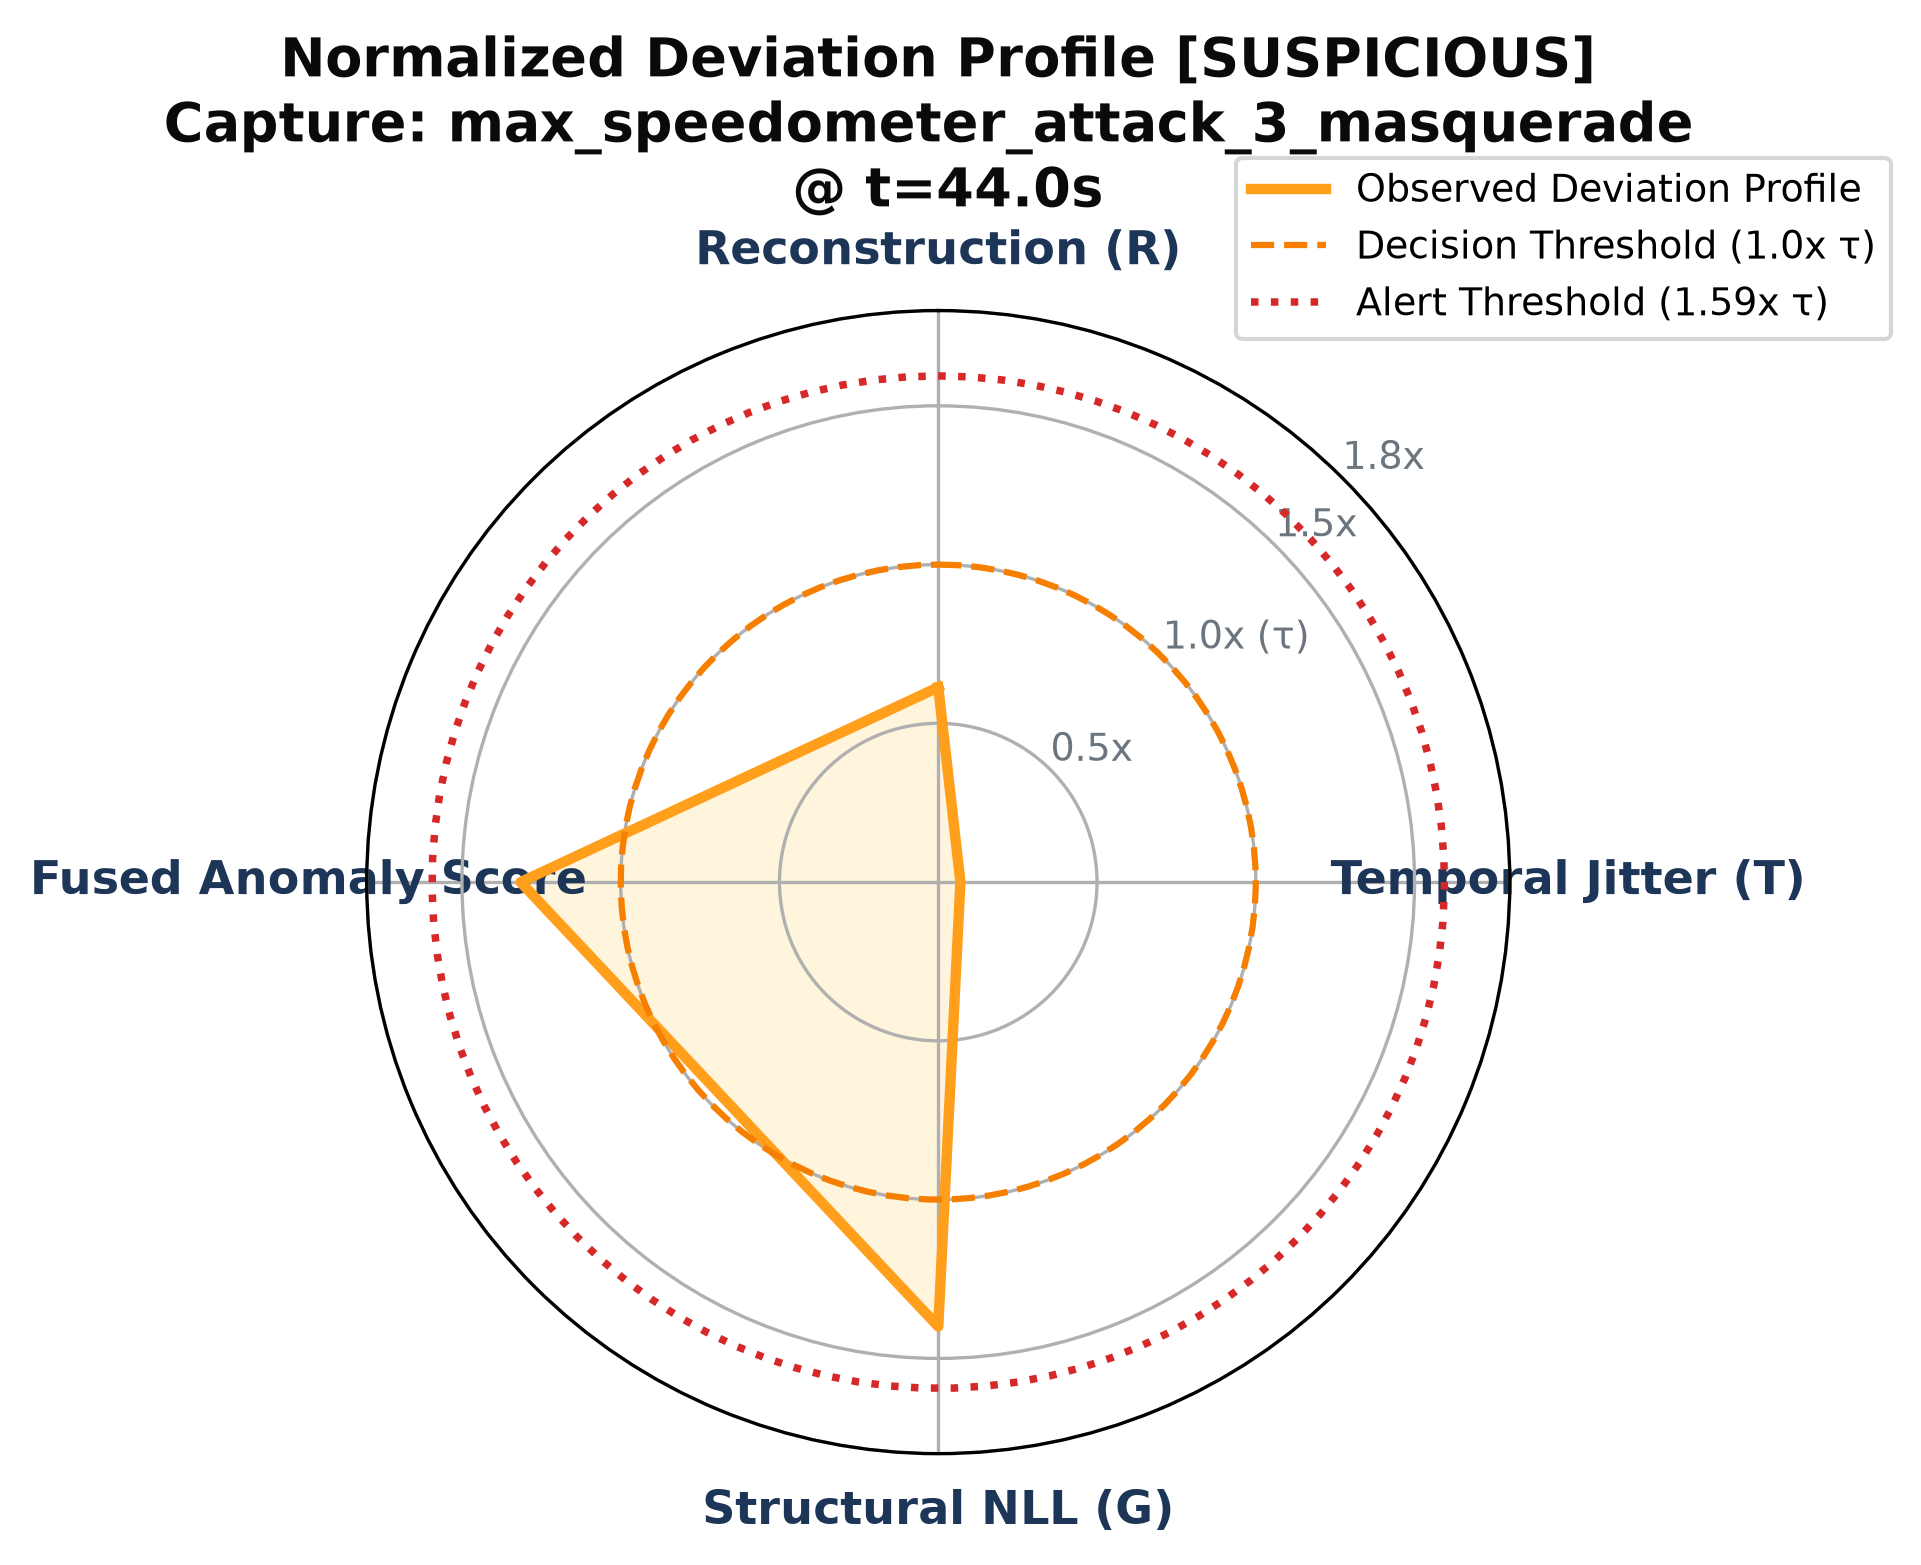

In [13]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_01_max_speedometer_attack_1_masquerade_radar_chart.png"))


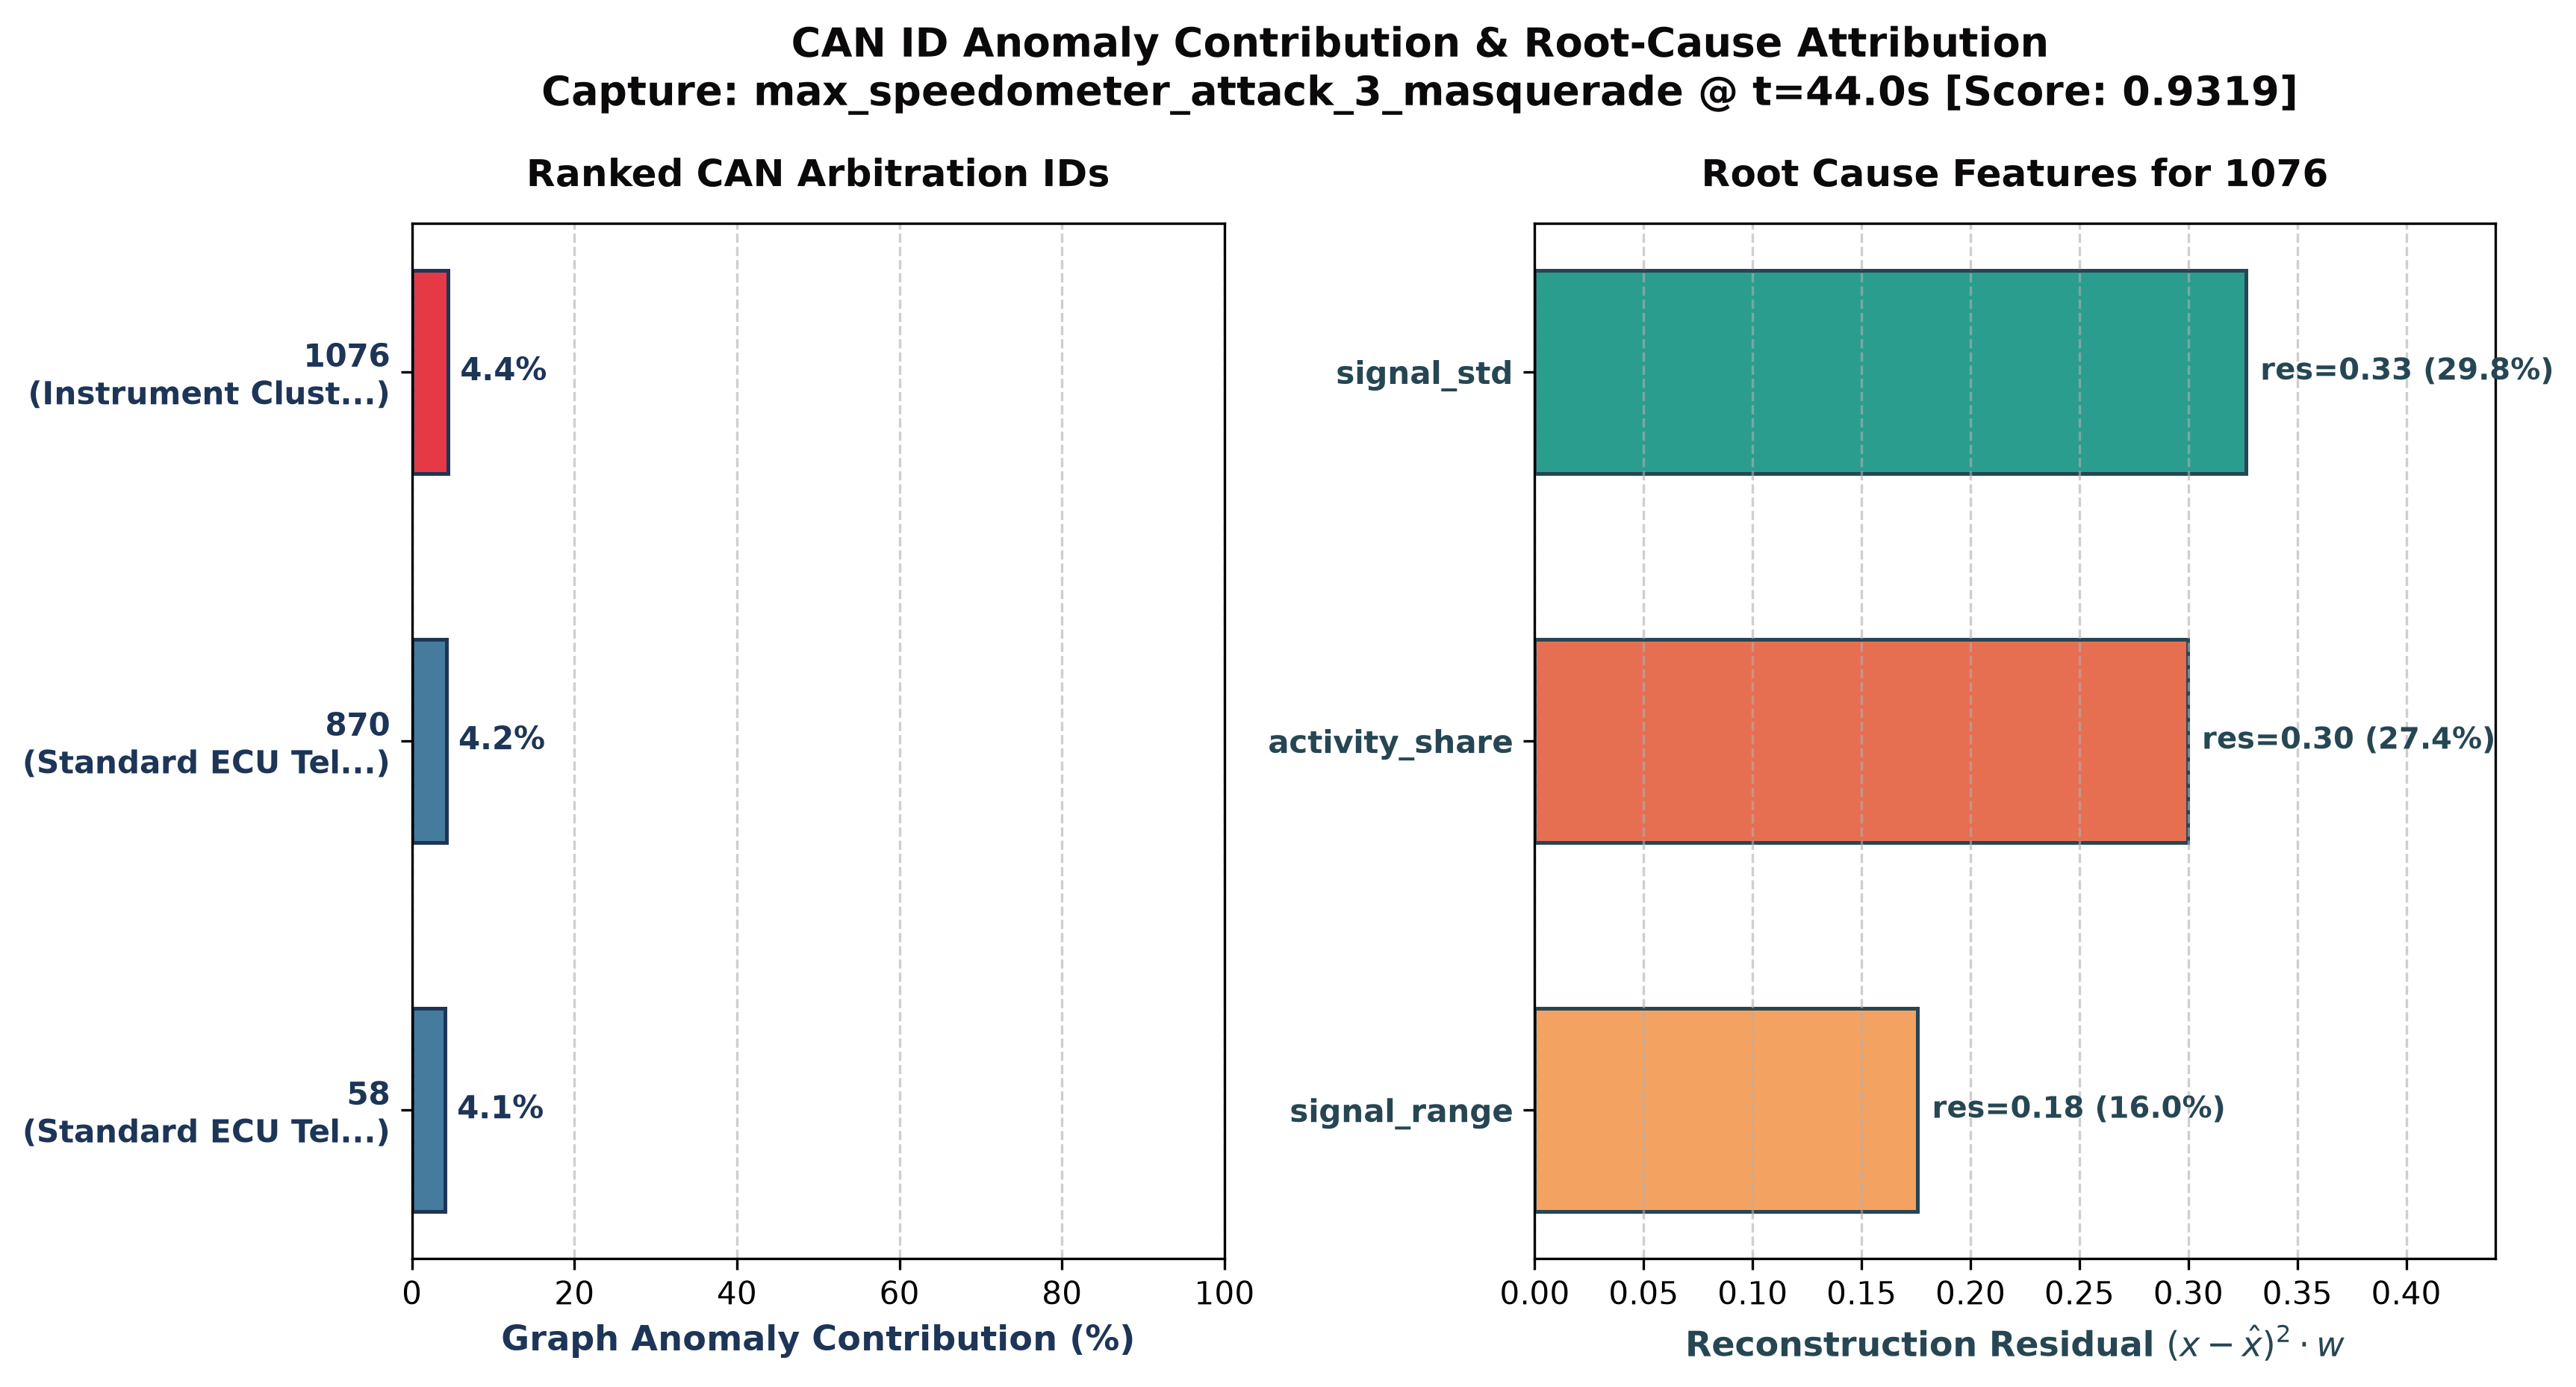

In [14]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_01_max_speedometer_attack_1_masquerade_id_attribution.png"))


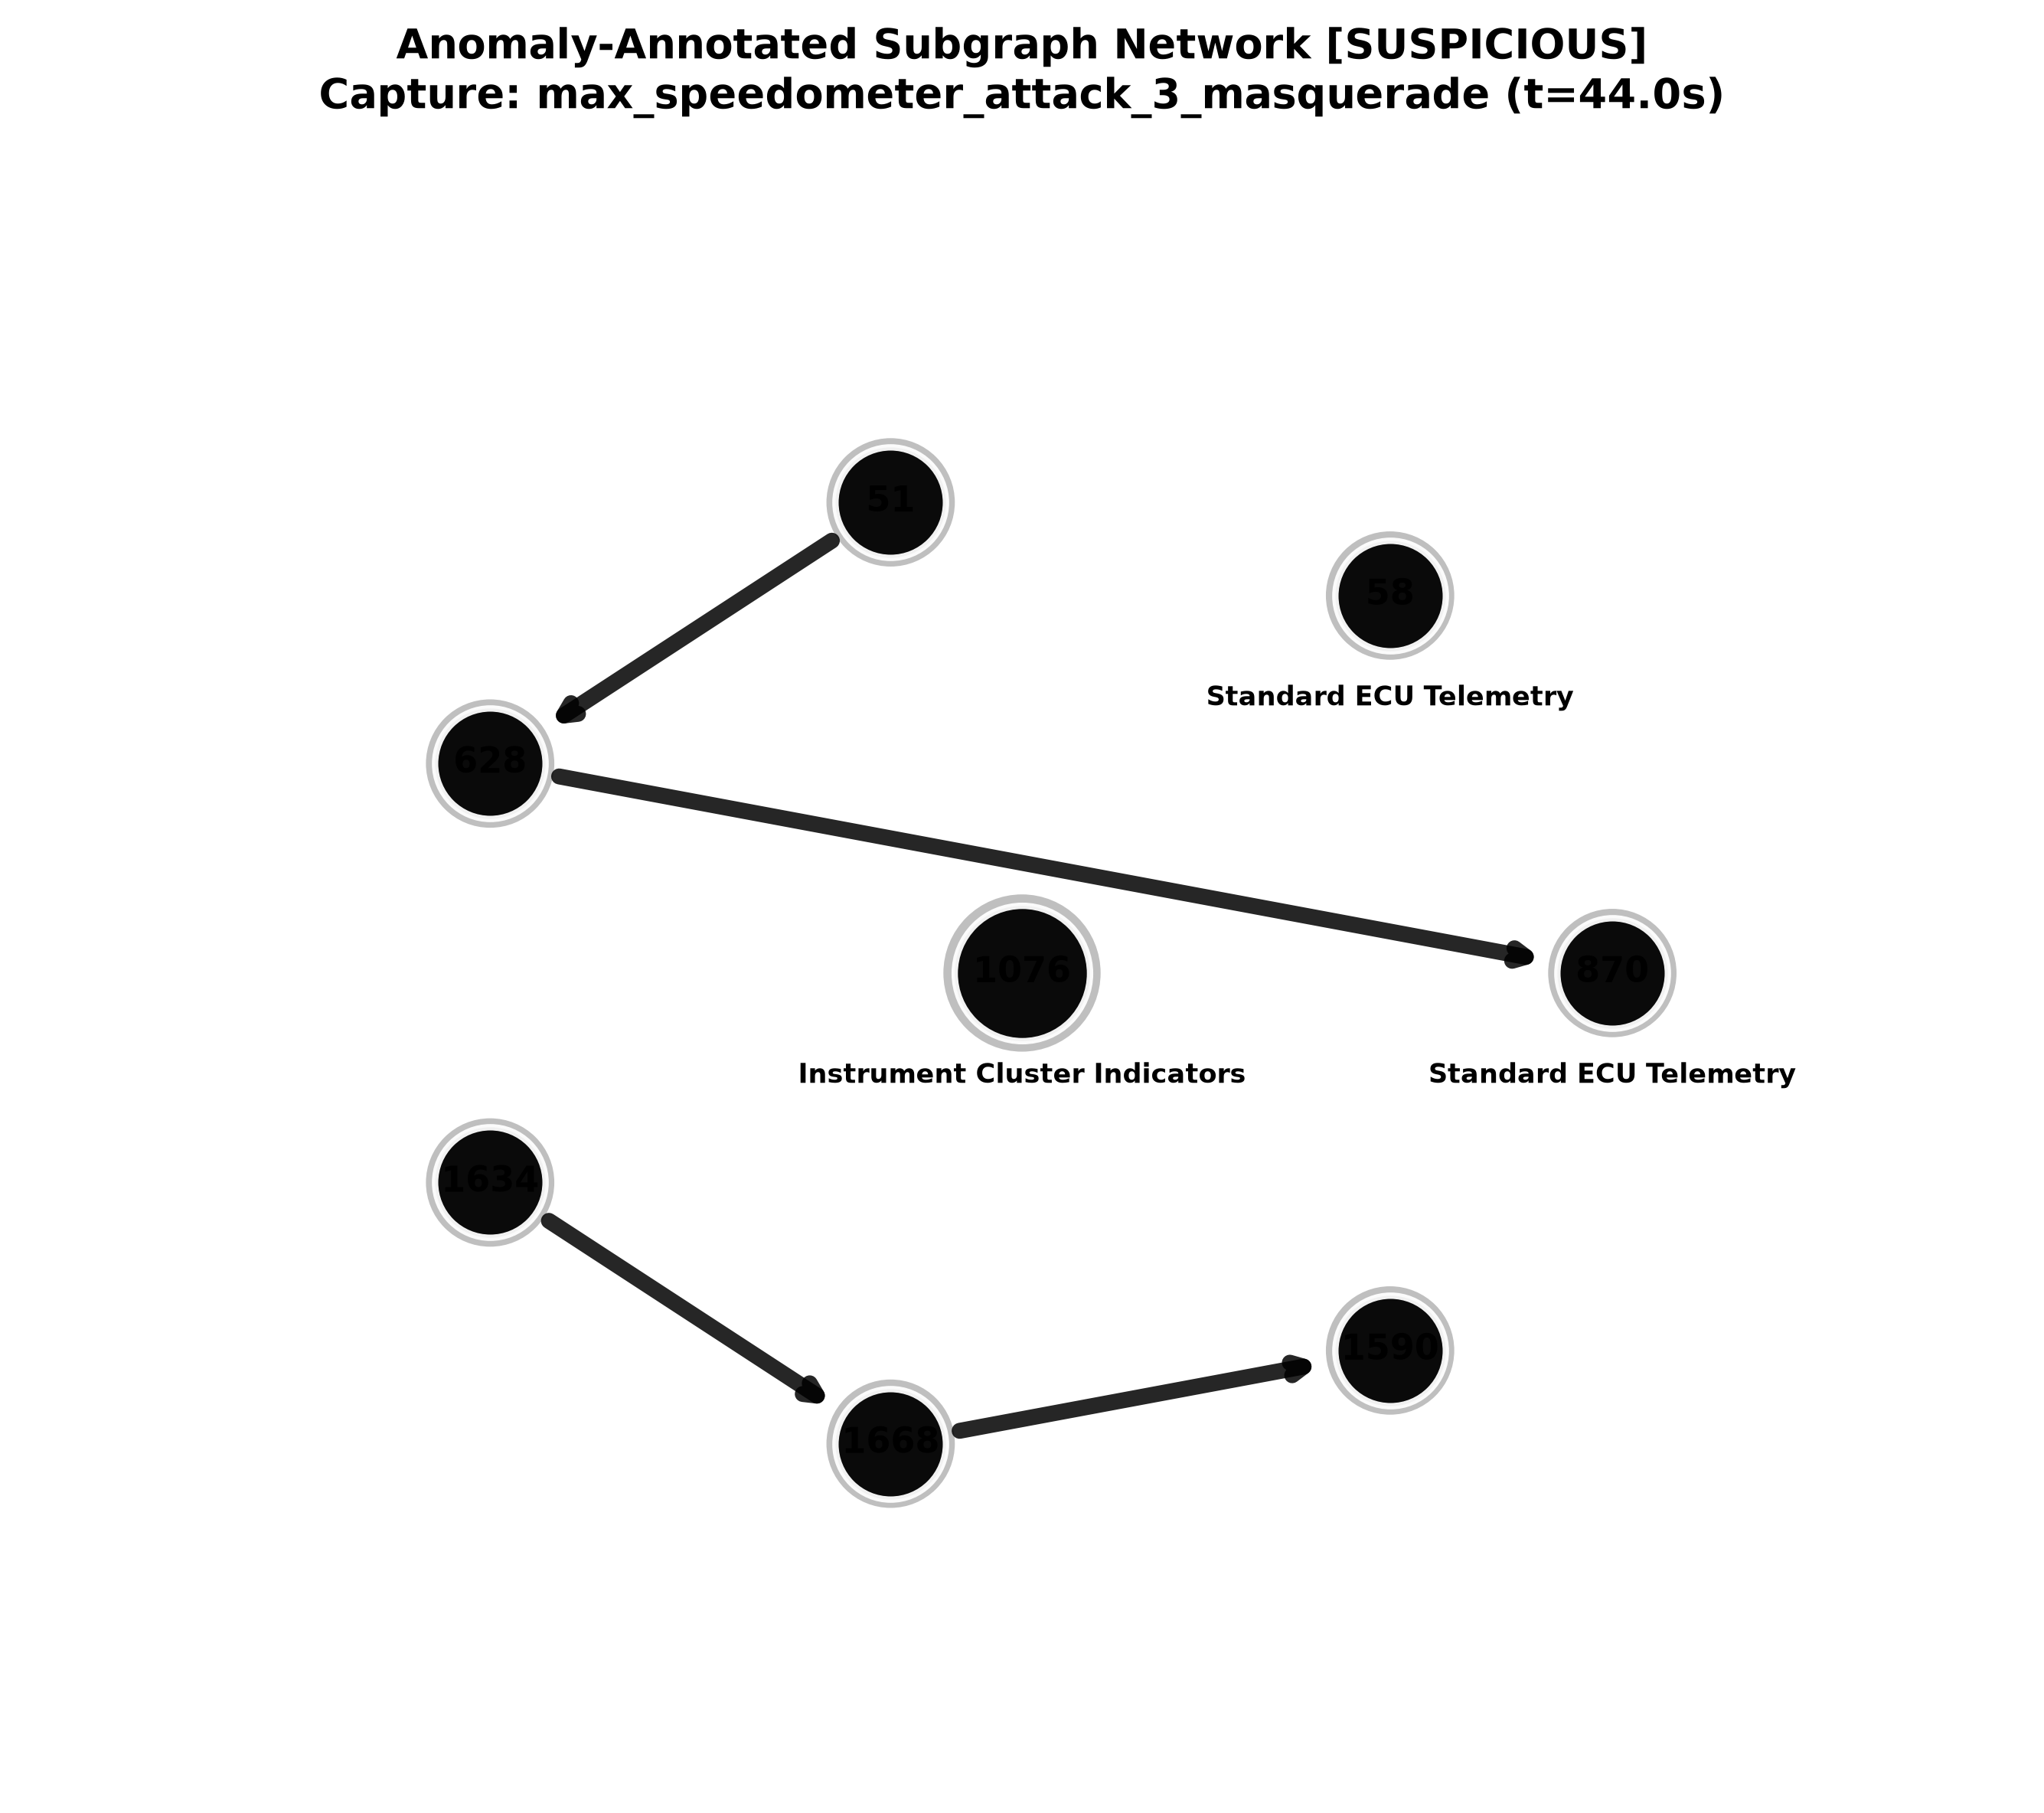

In [15]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_01_max_speedometer_attack_1_masquerade_subgraph.png"))


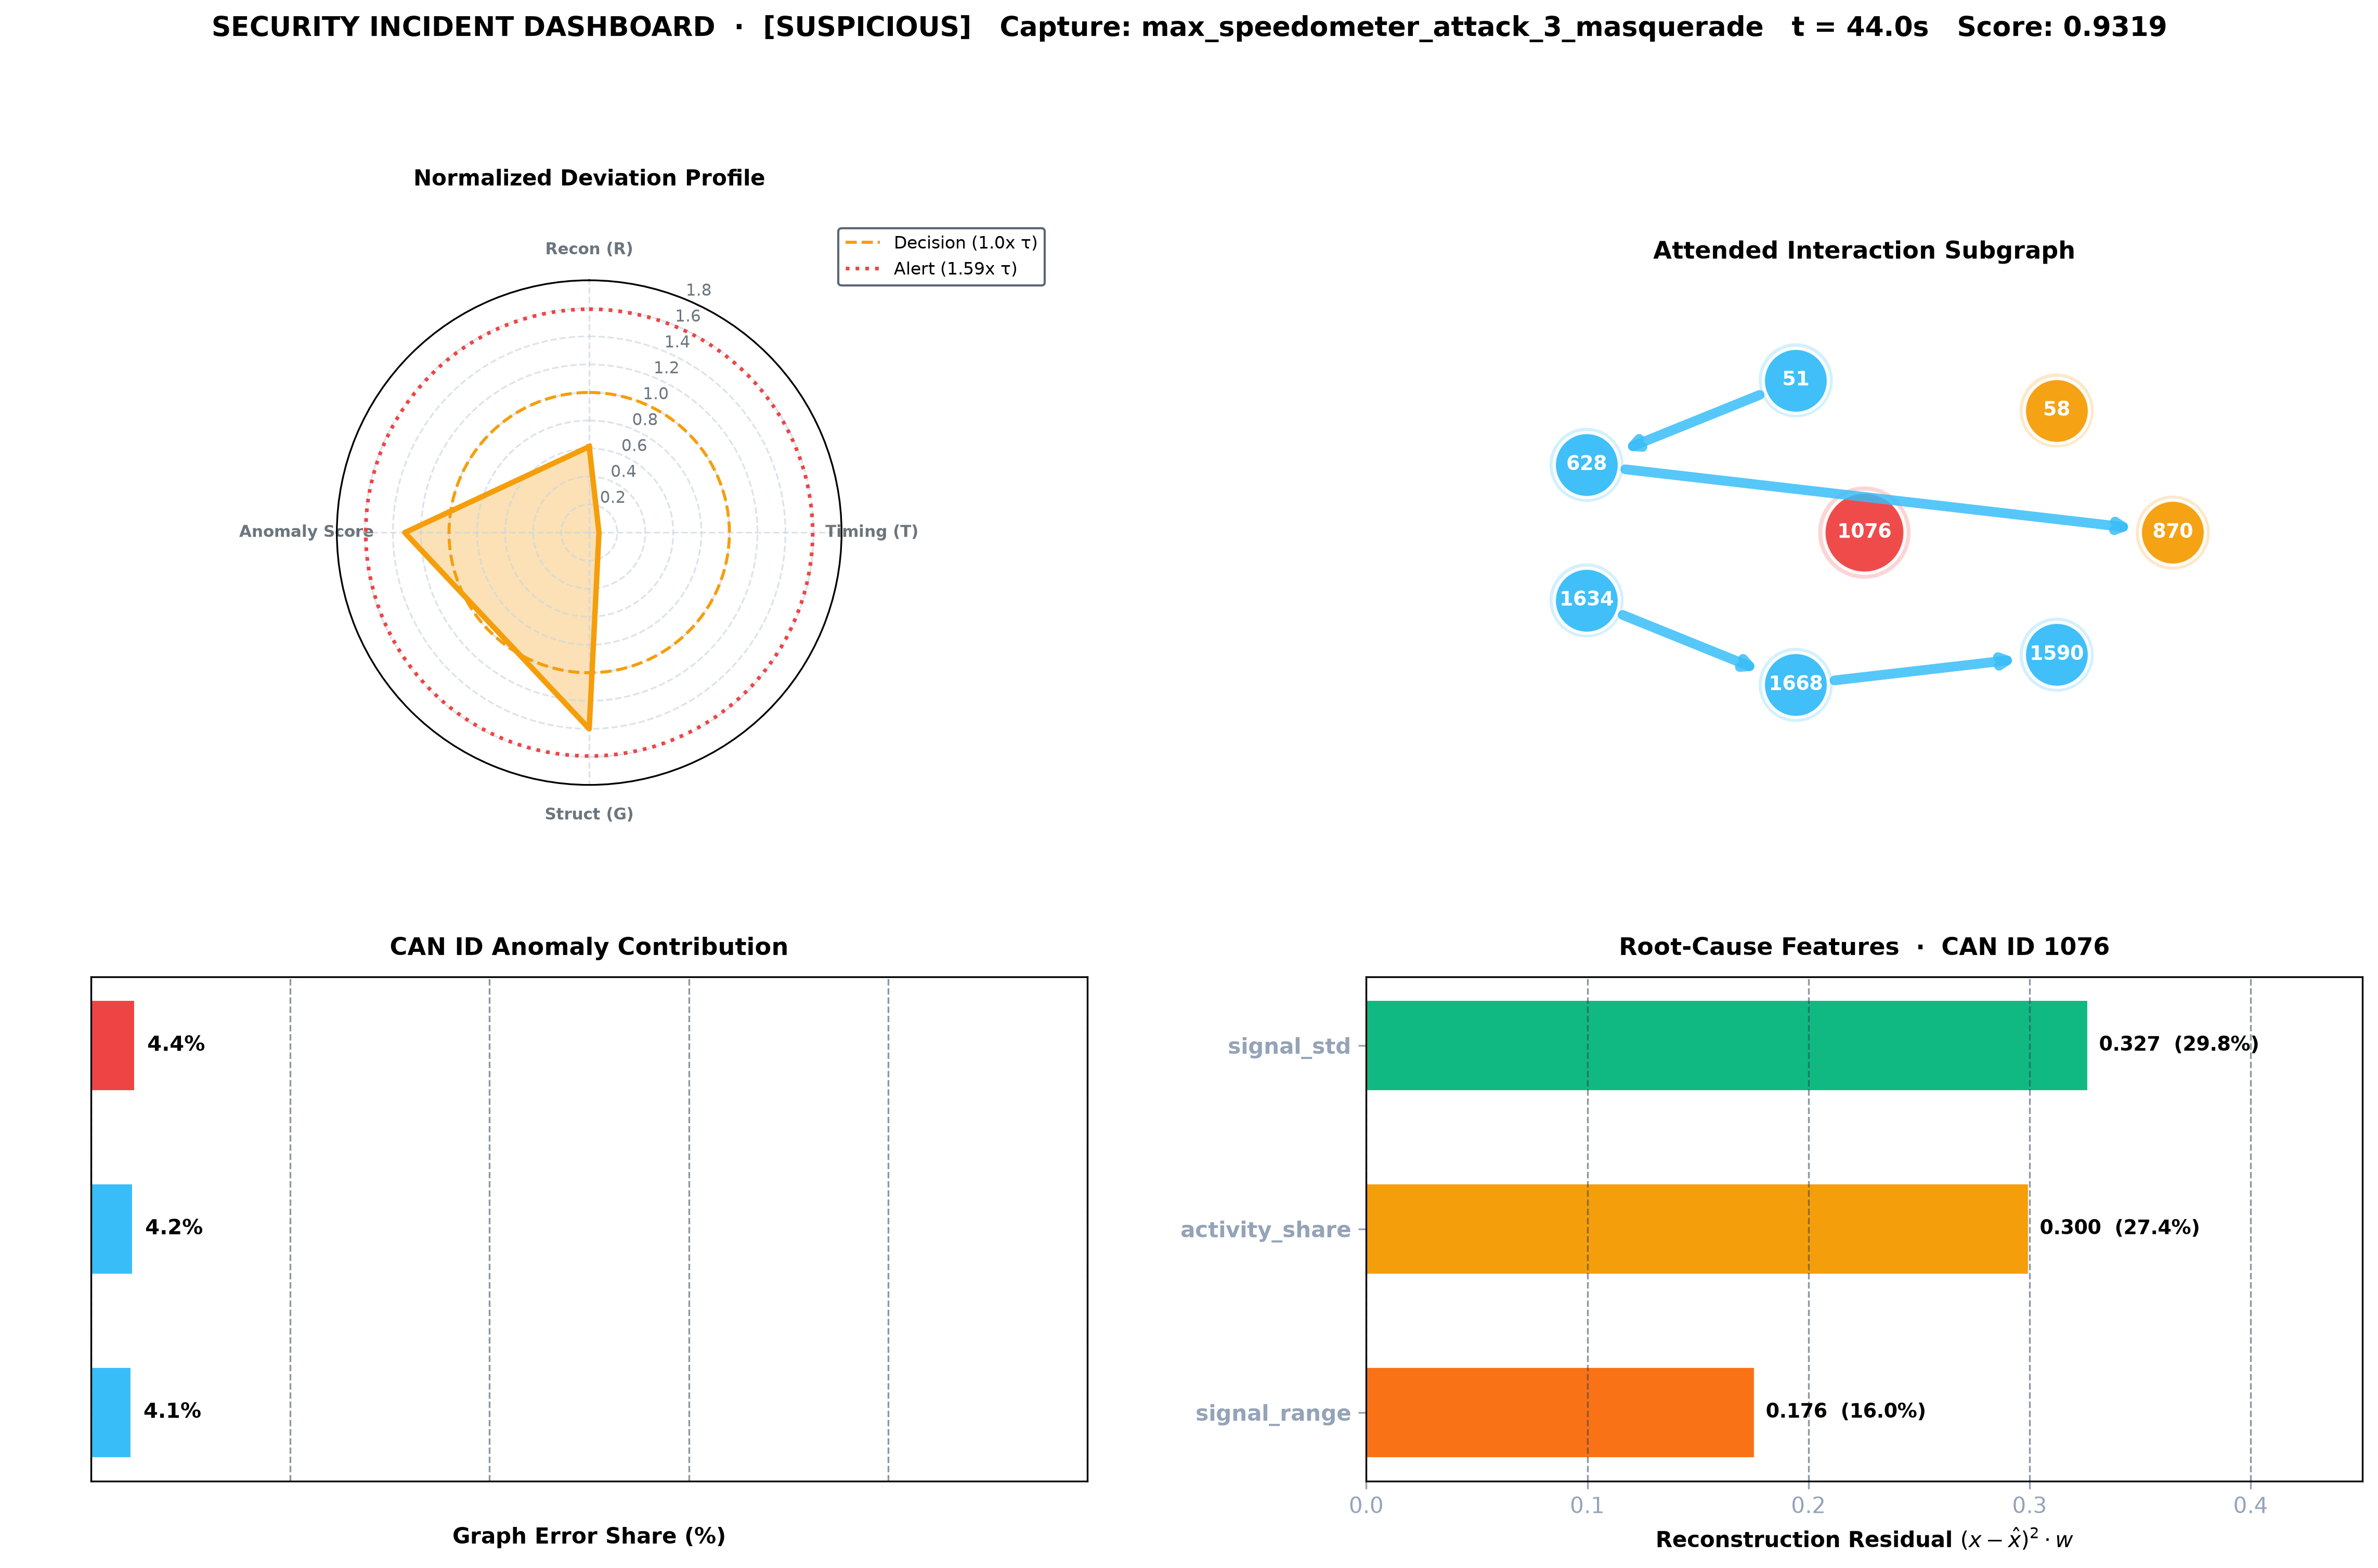

In [16]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_01_max_speedometer_attack_1_masquerade_dashboard.png"))


### Incident 02: Reverse Light Off Attack [HIGH_RISK]
Forensic explanation visual artifacts for `reverse_light_off_attack_1_masquerade`.

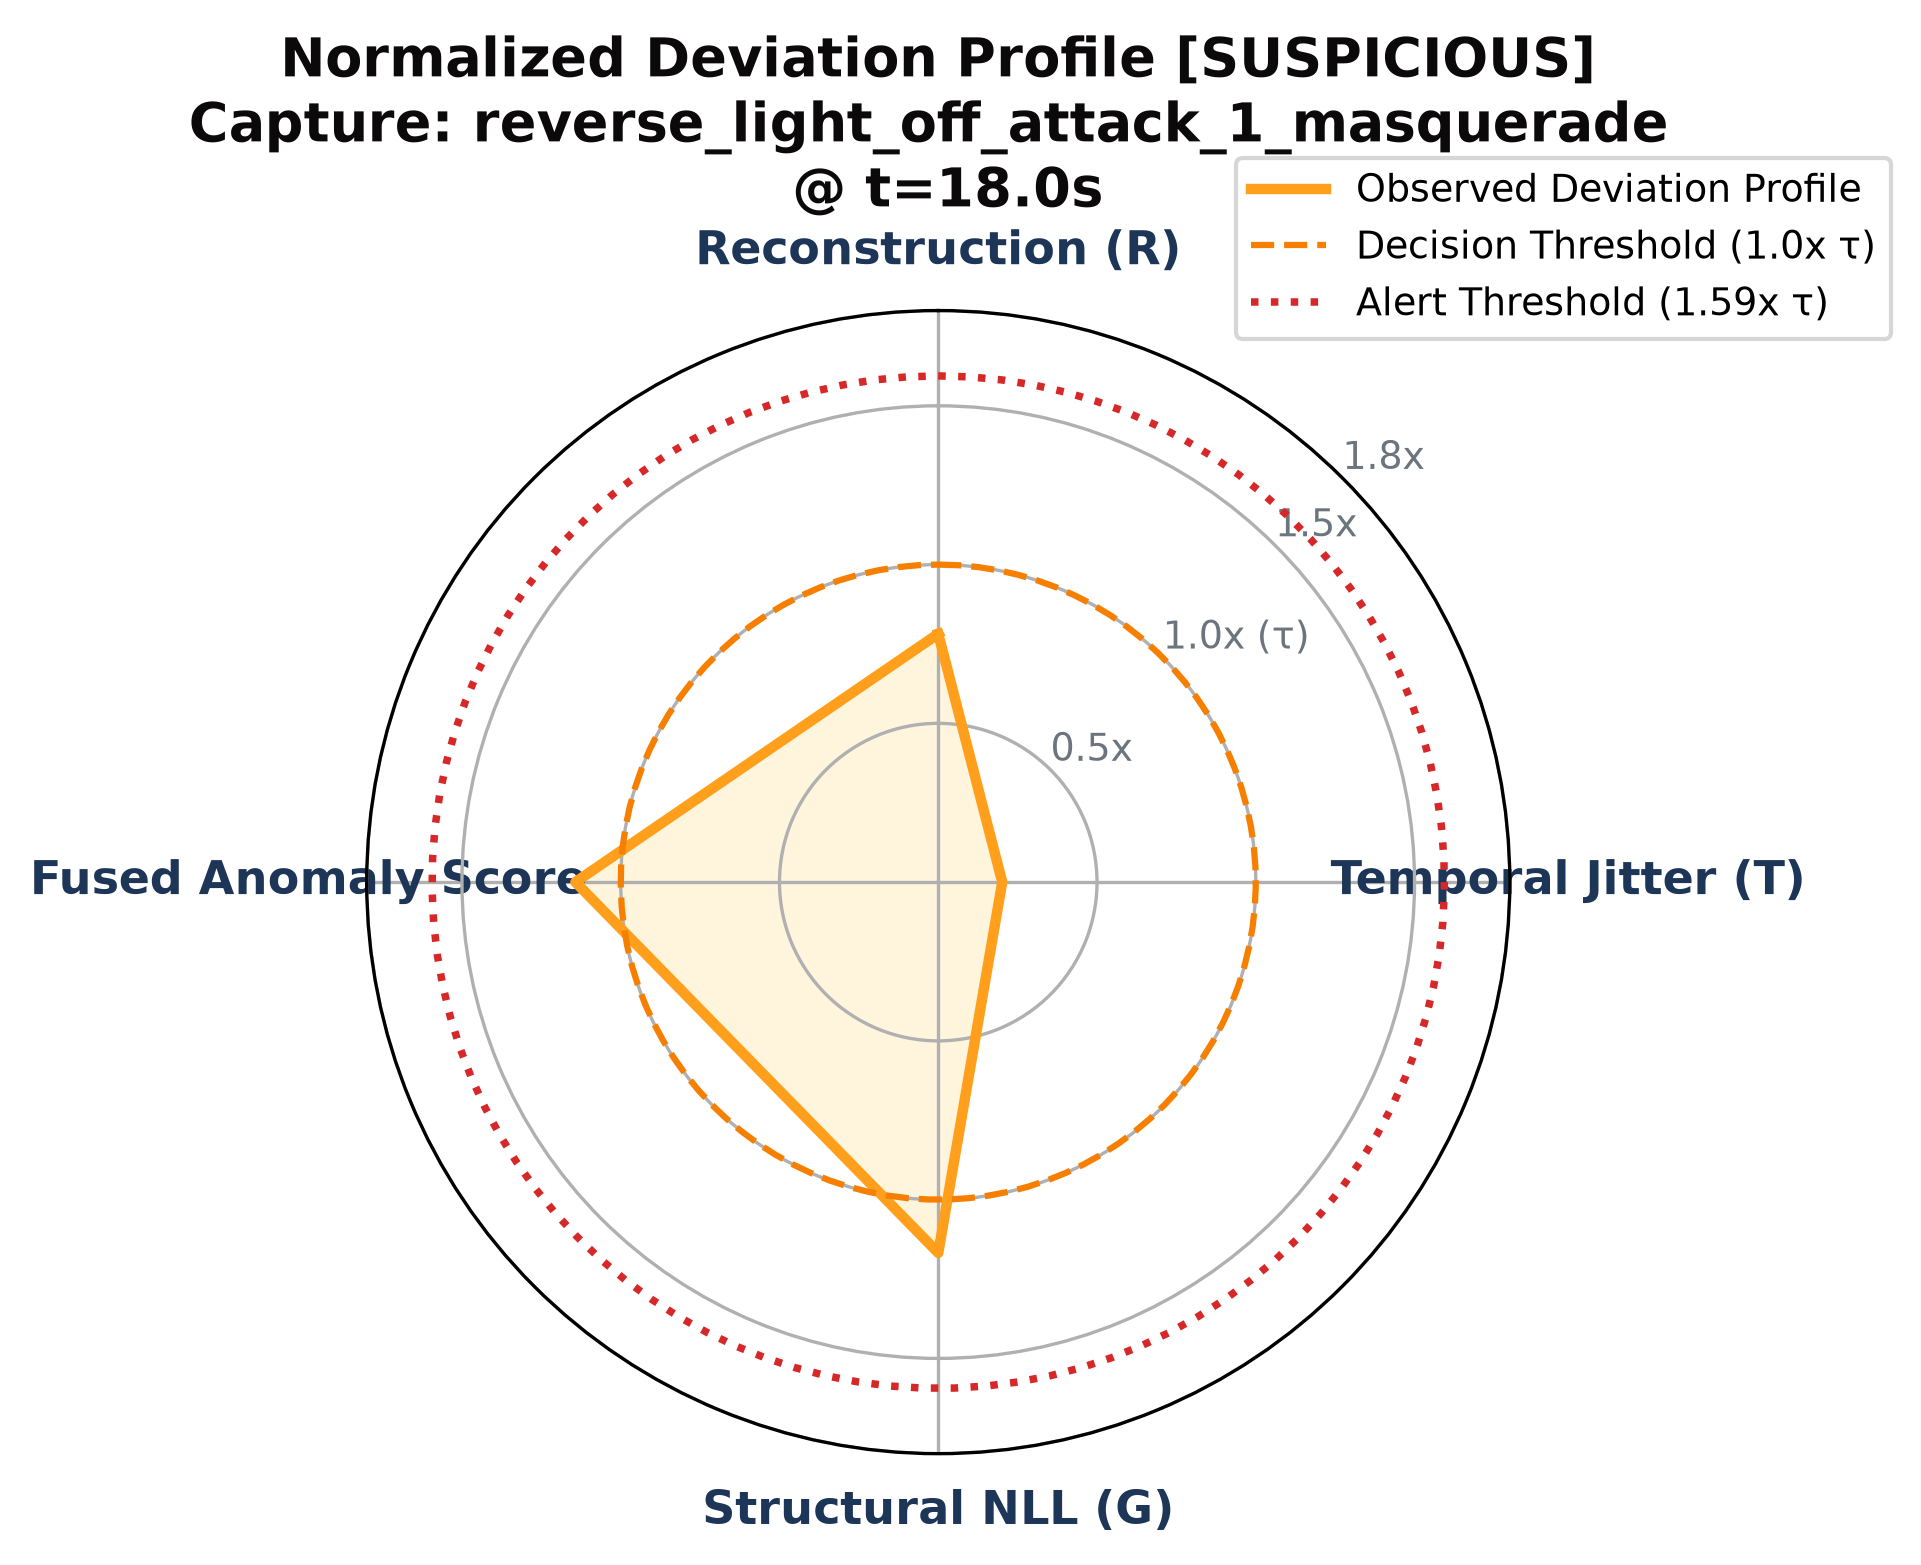

In [17]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_02_reverse_light_off_attack_1_masquerade_radar_chart.png"))


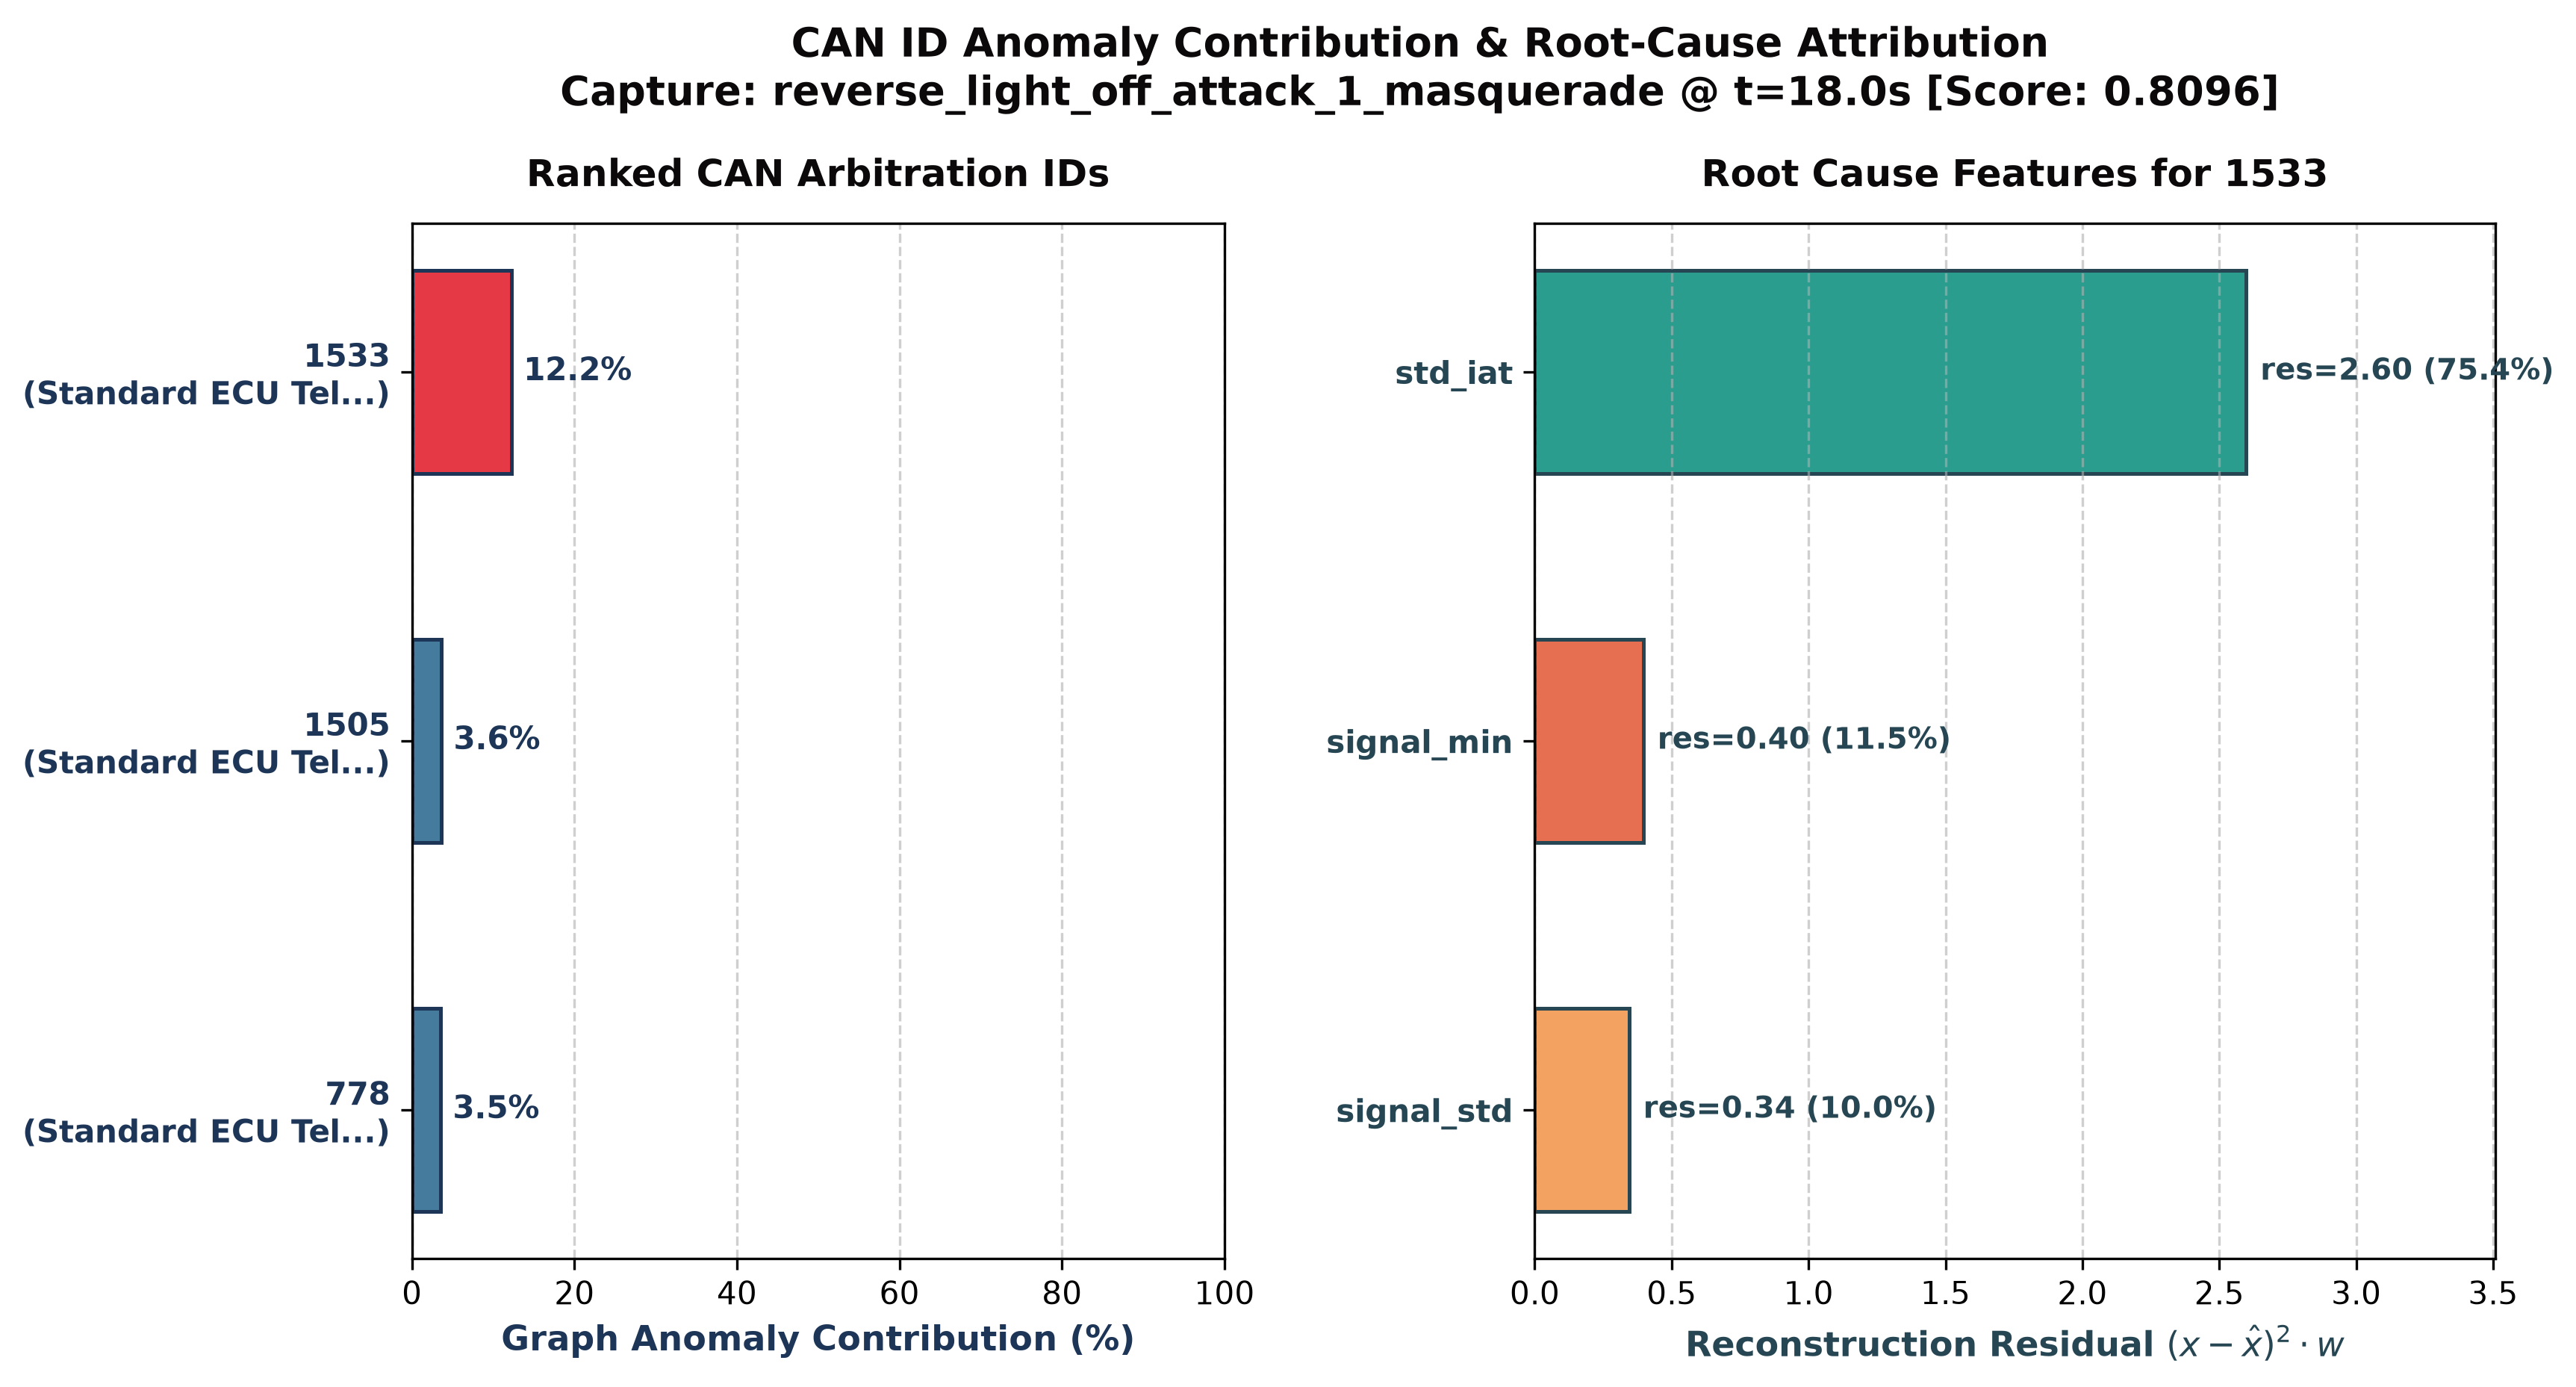

In [18]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_02_reverse_light_off_attack_1_masquerade_id_attribution.png"))


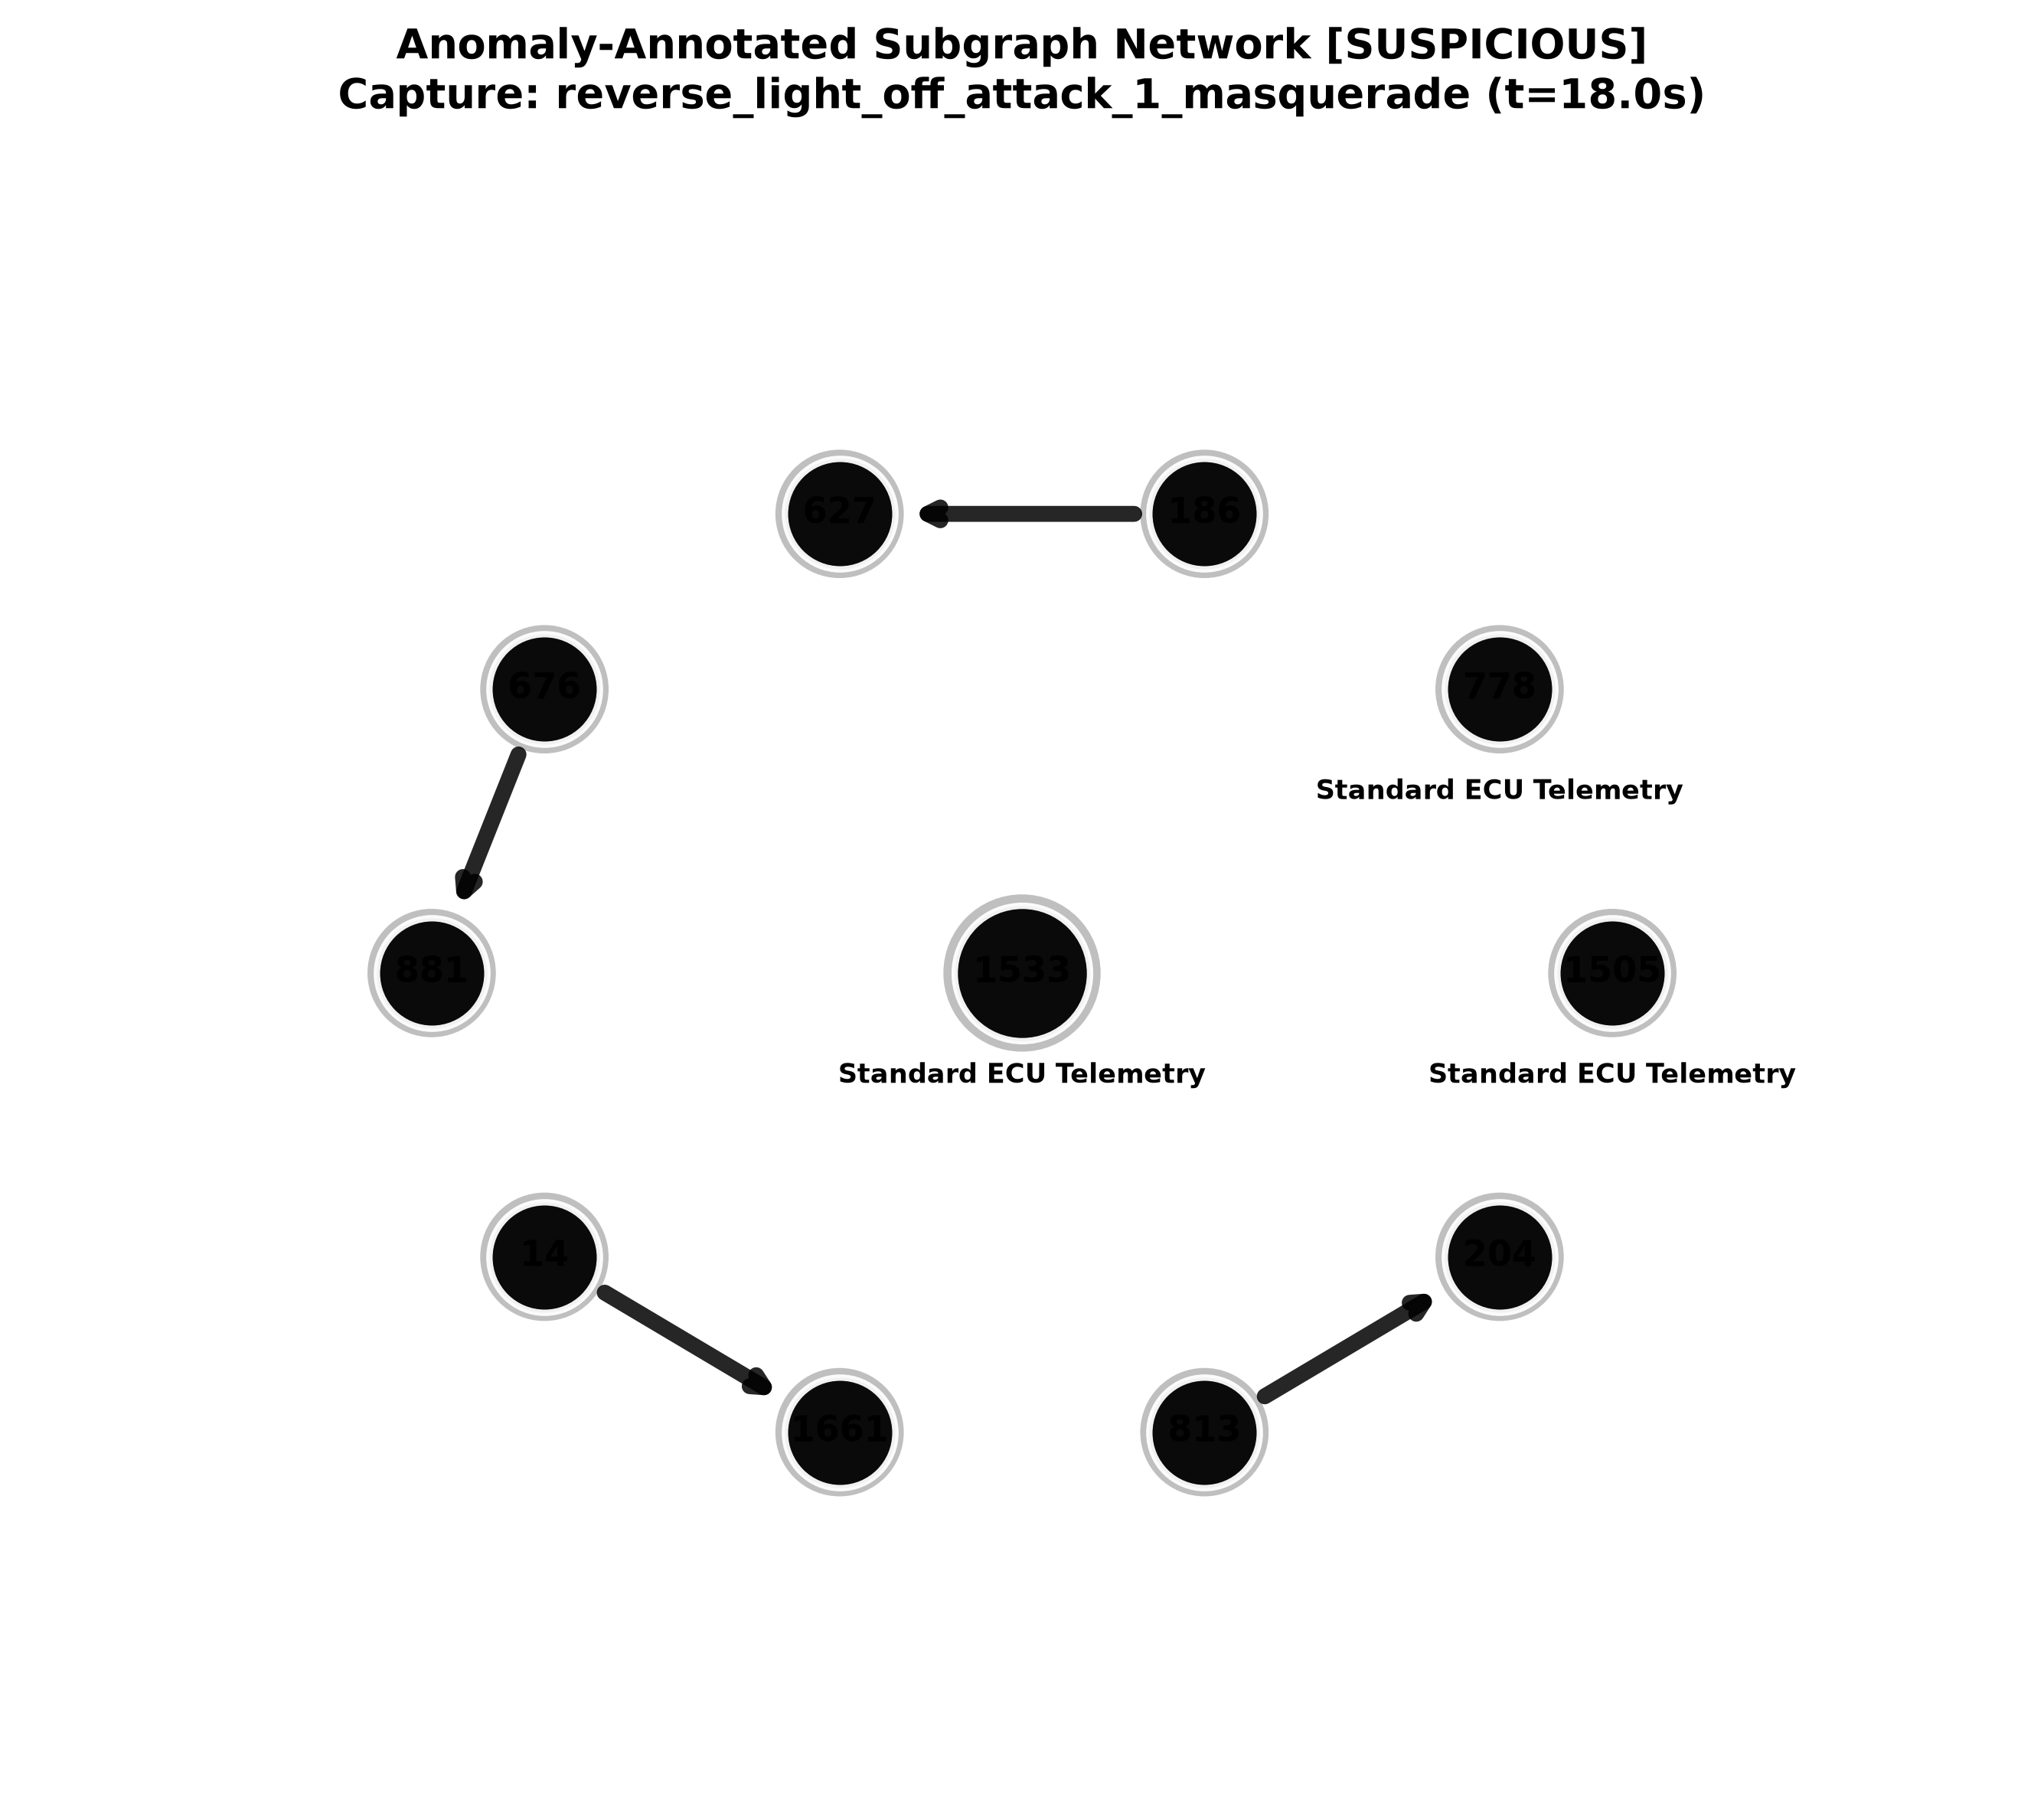

In [19]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_02_reverse_light_off_attack_1_masquerade_subgraph.png"))


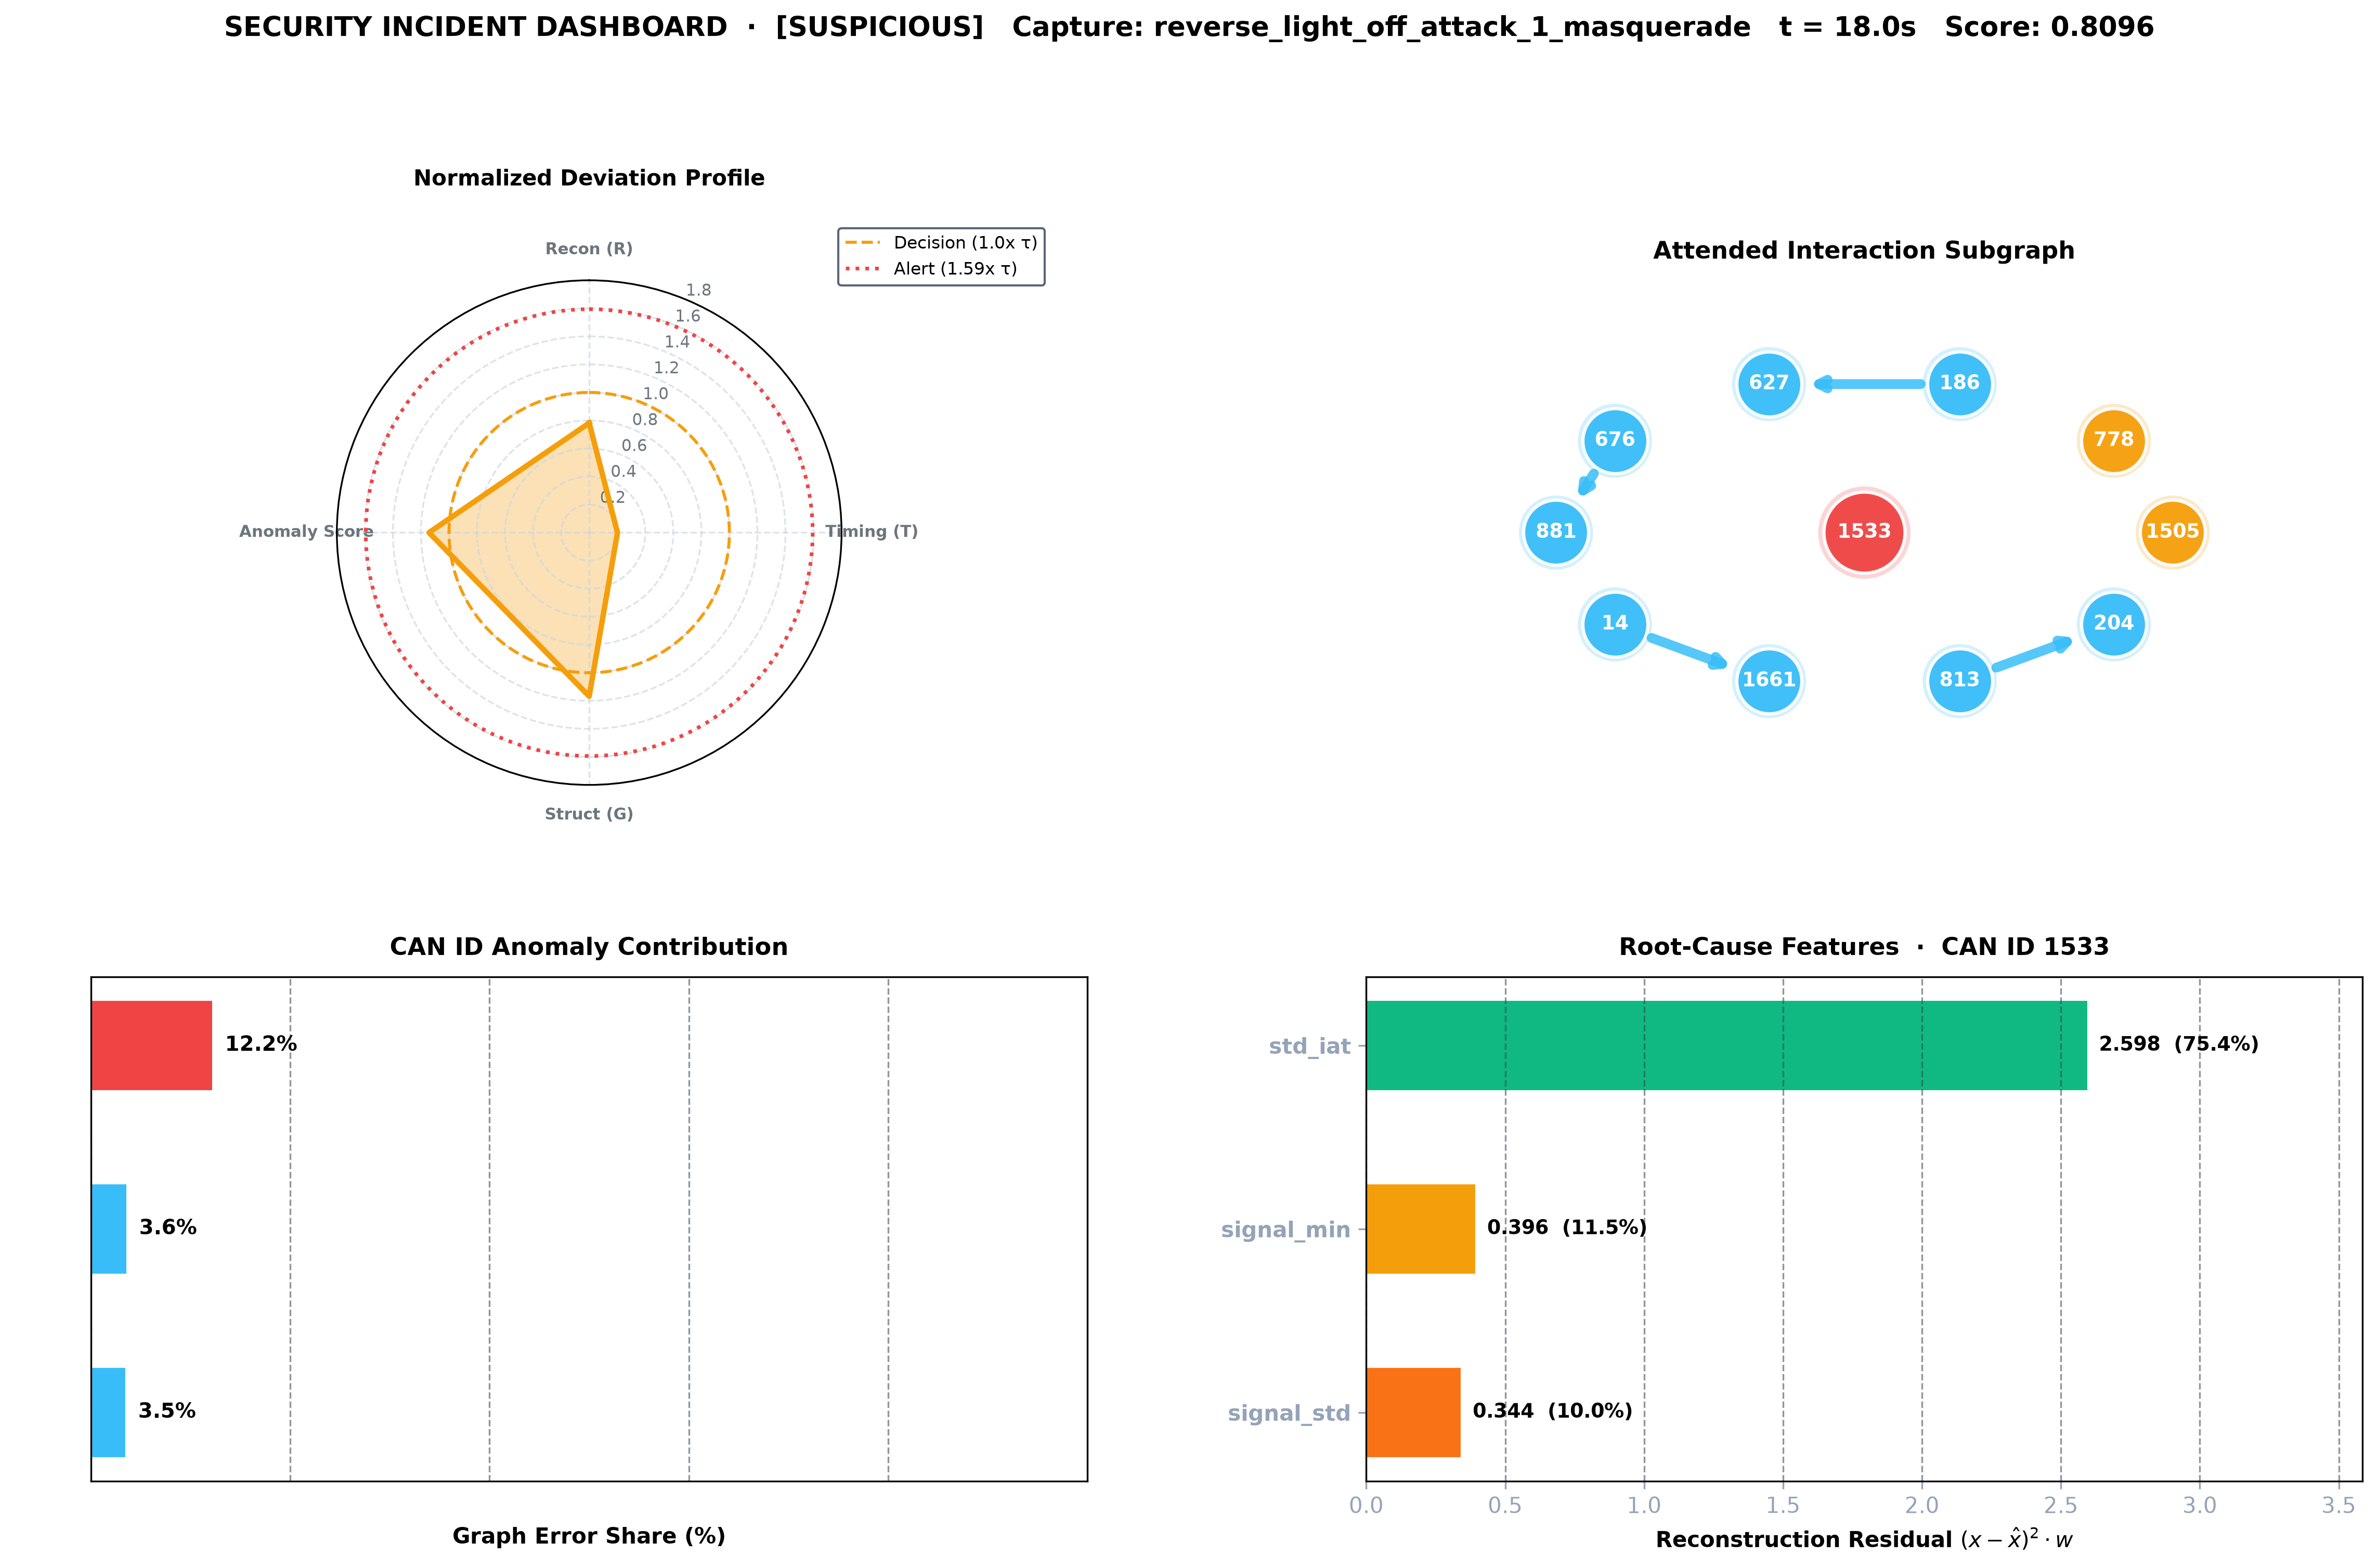

In [20]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_02_reverse_light_off_attack_1_masquerade_dashboard.png"))


### Incident 03: Reverse Light On Attack [HIGH_RISK]
Forensic explanation visual artifacts for `reverse_light_on_attack_2_masquerade`.

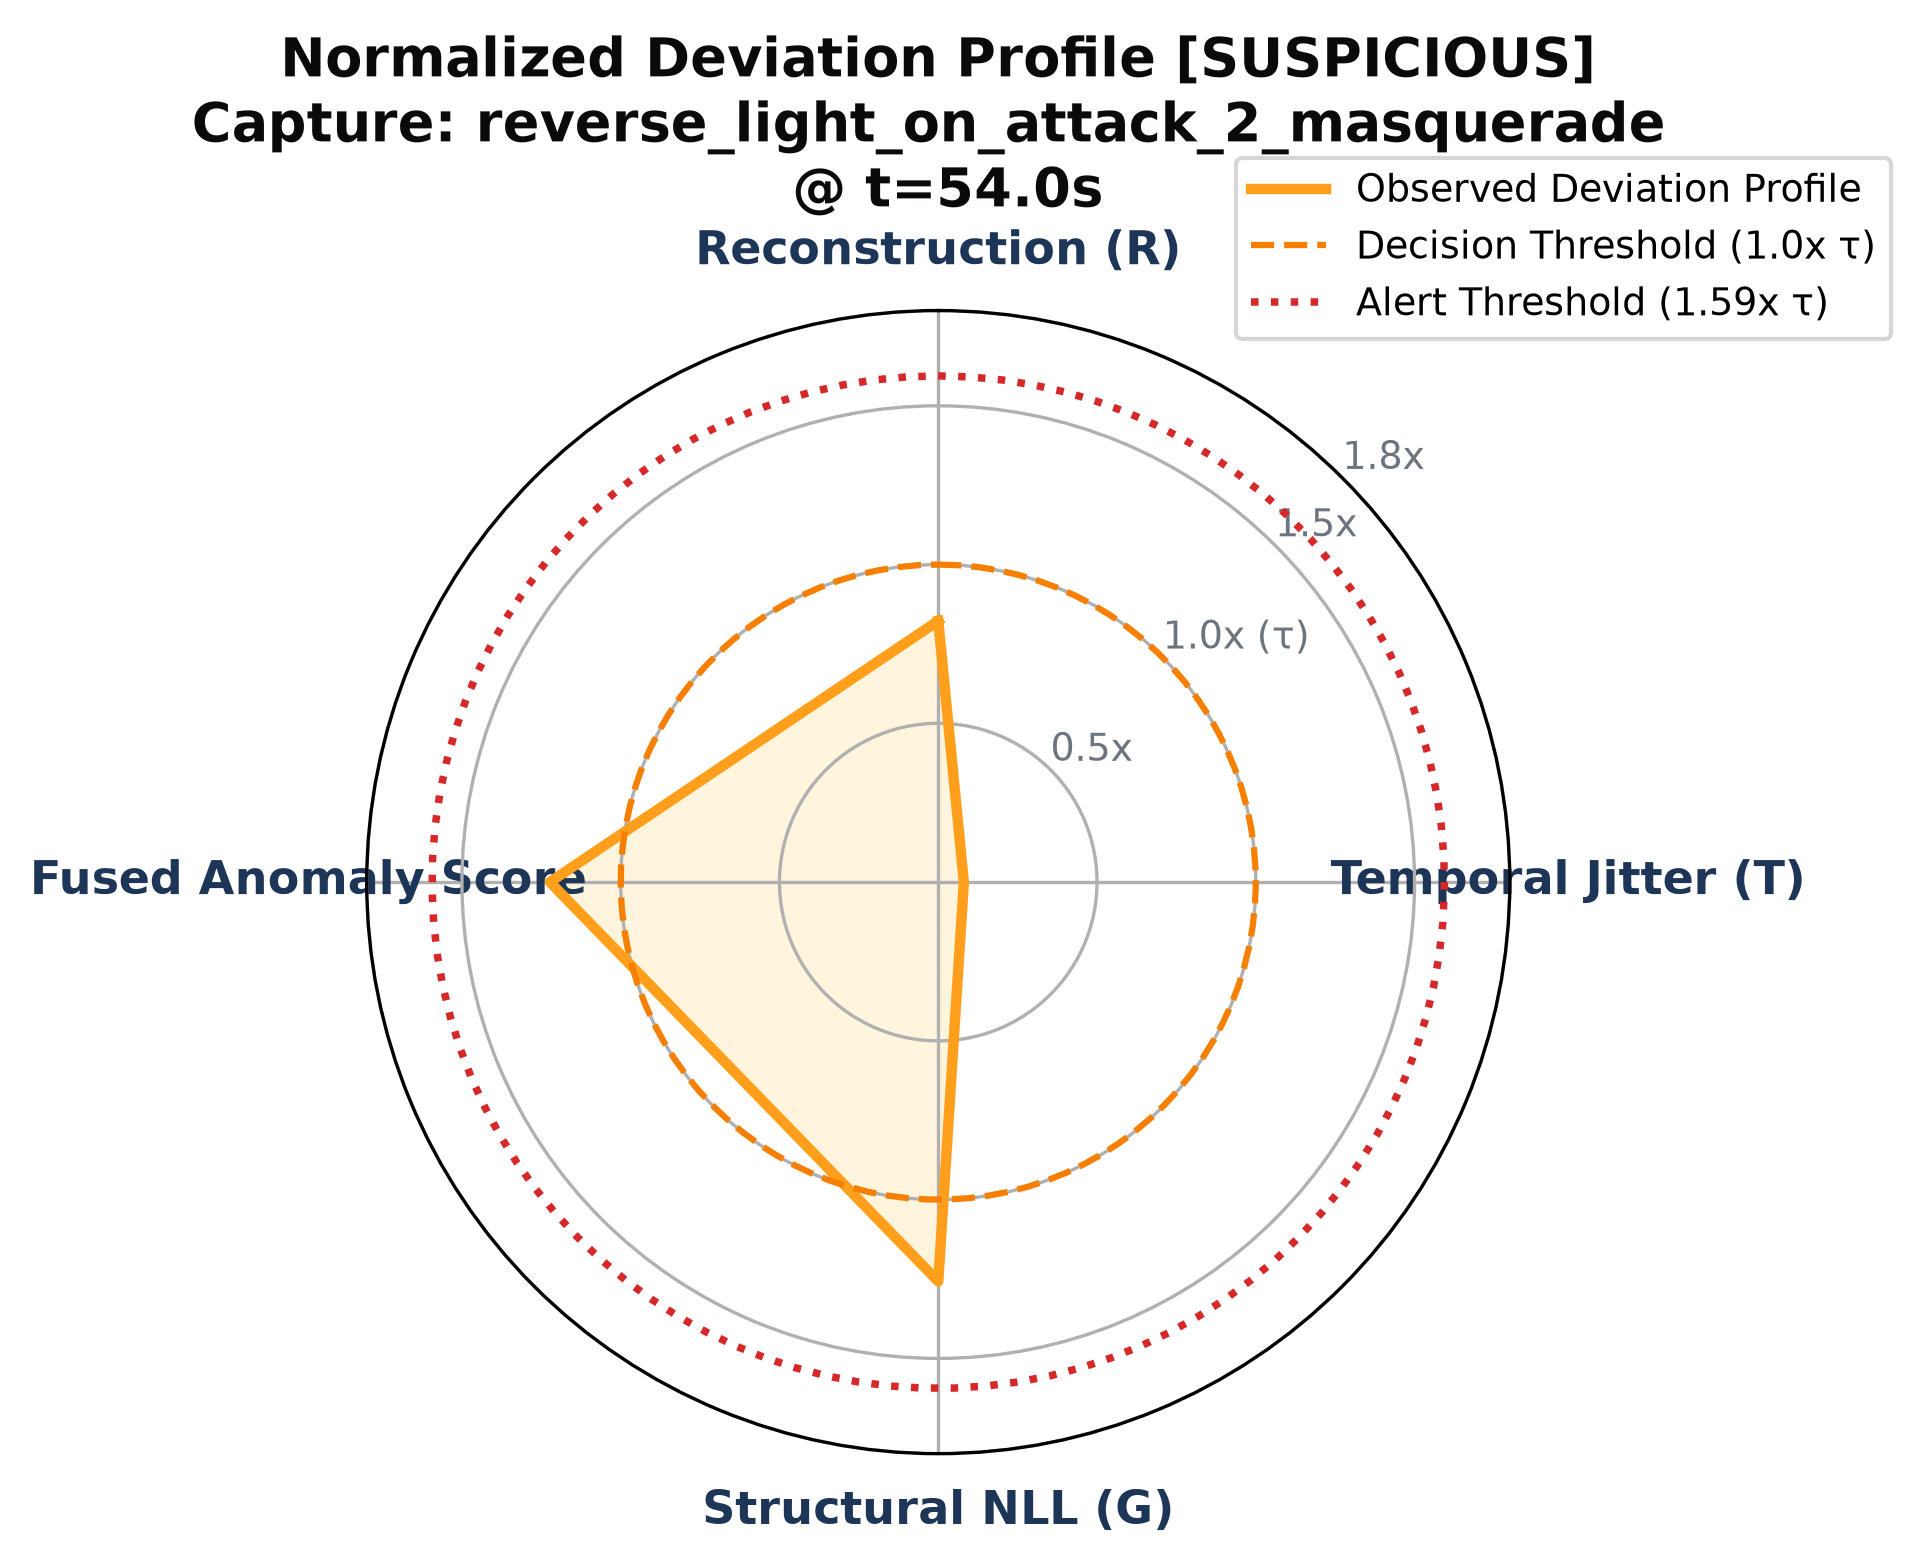

In [21]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_03_reverse_light_on_attack_2_masquerade_radar_chart.png"))


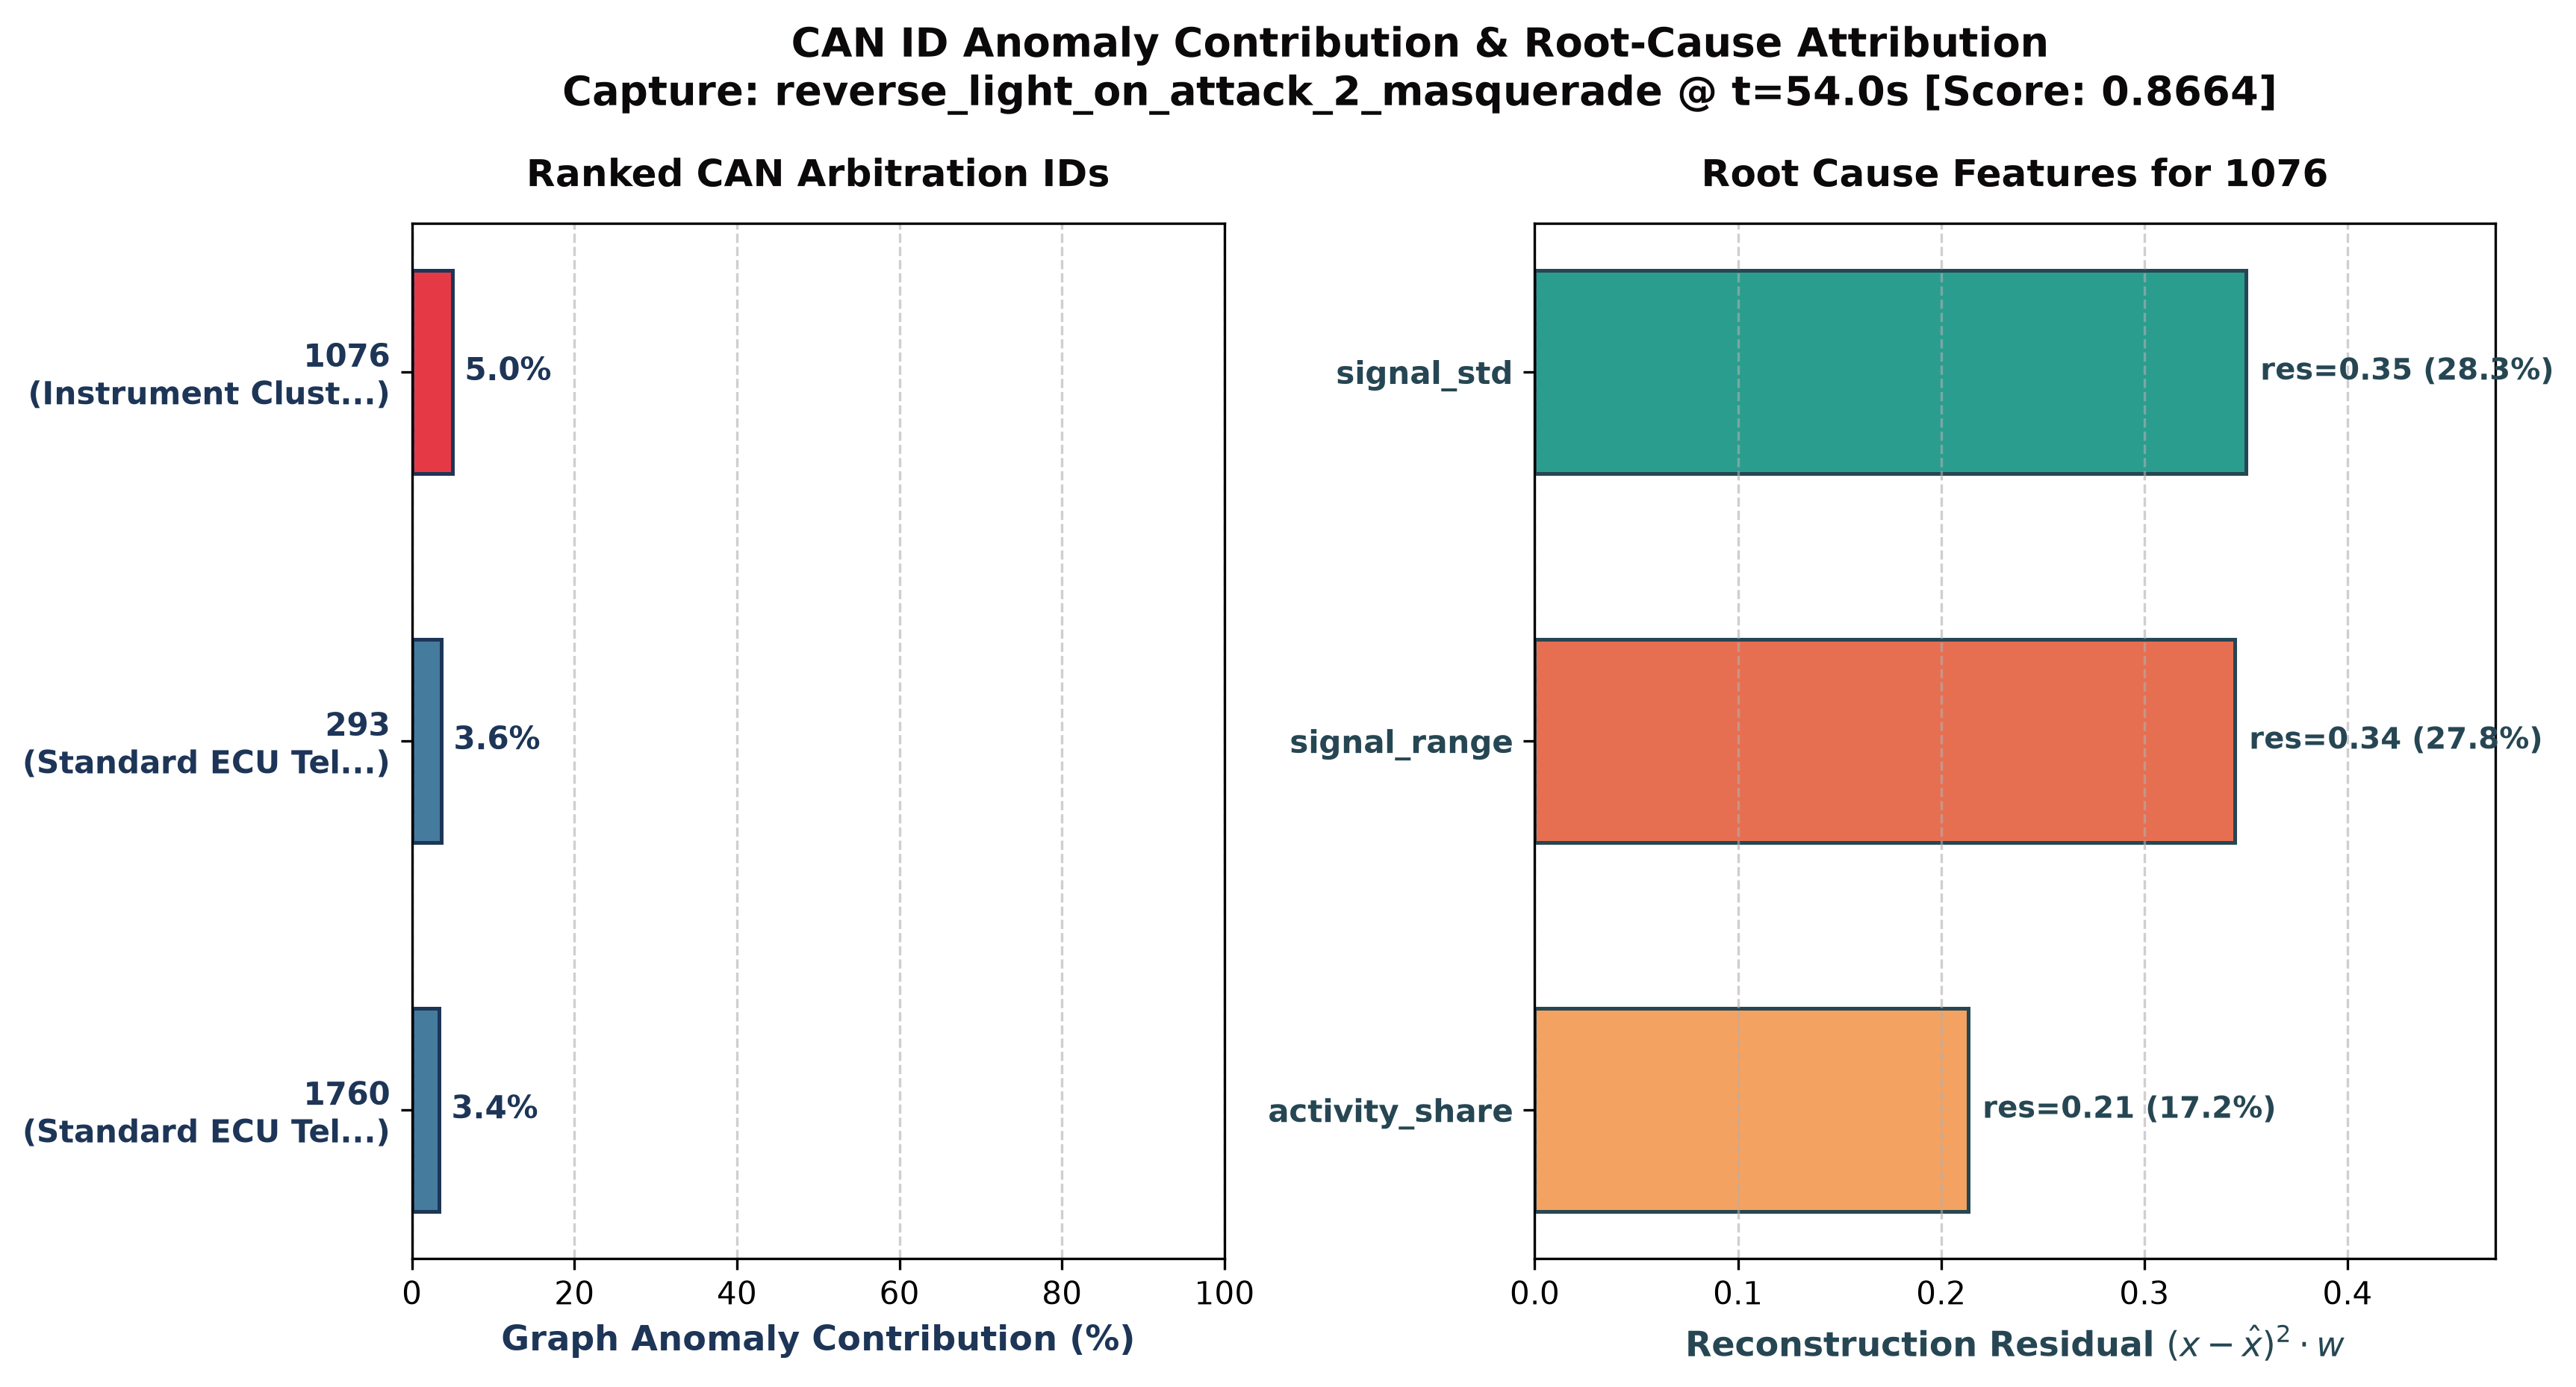

In [22]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_03_reverse_light_on_attack_2_masquerade_id_attribution.png"))


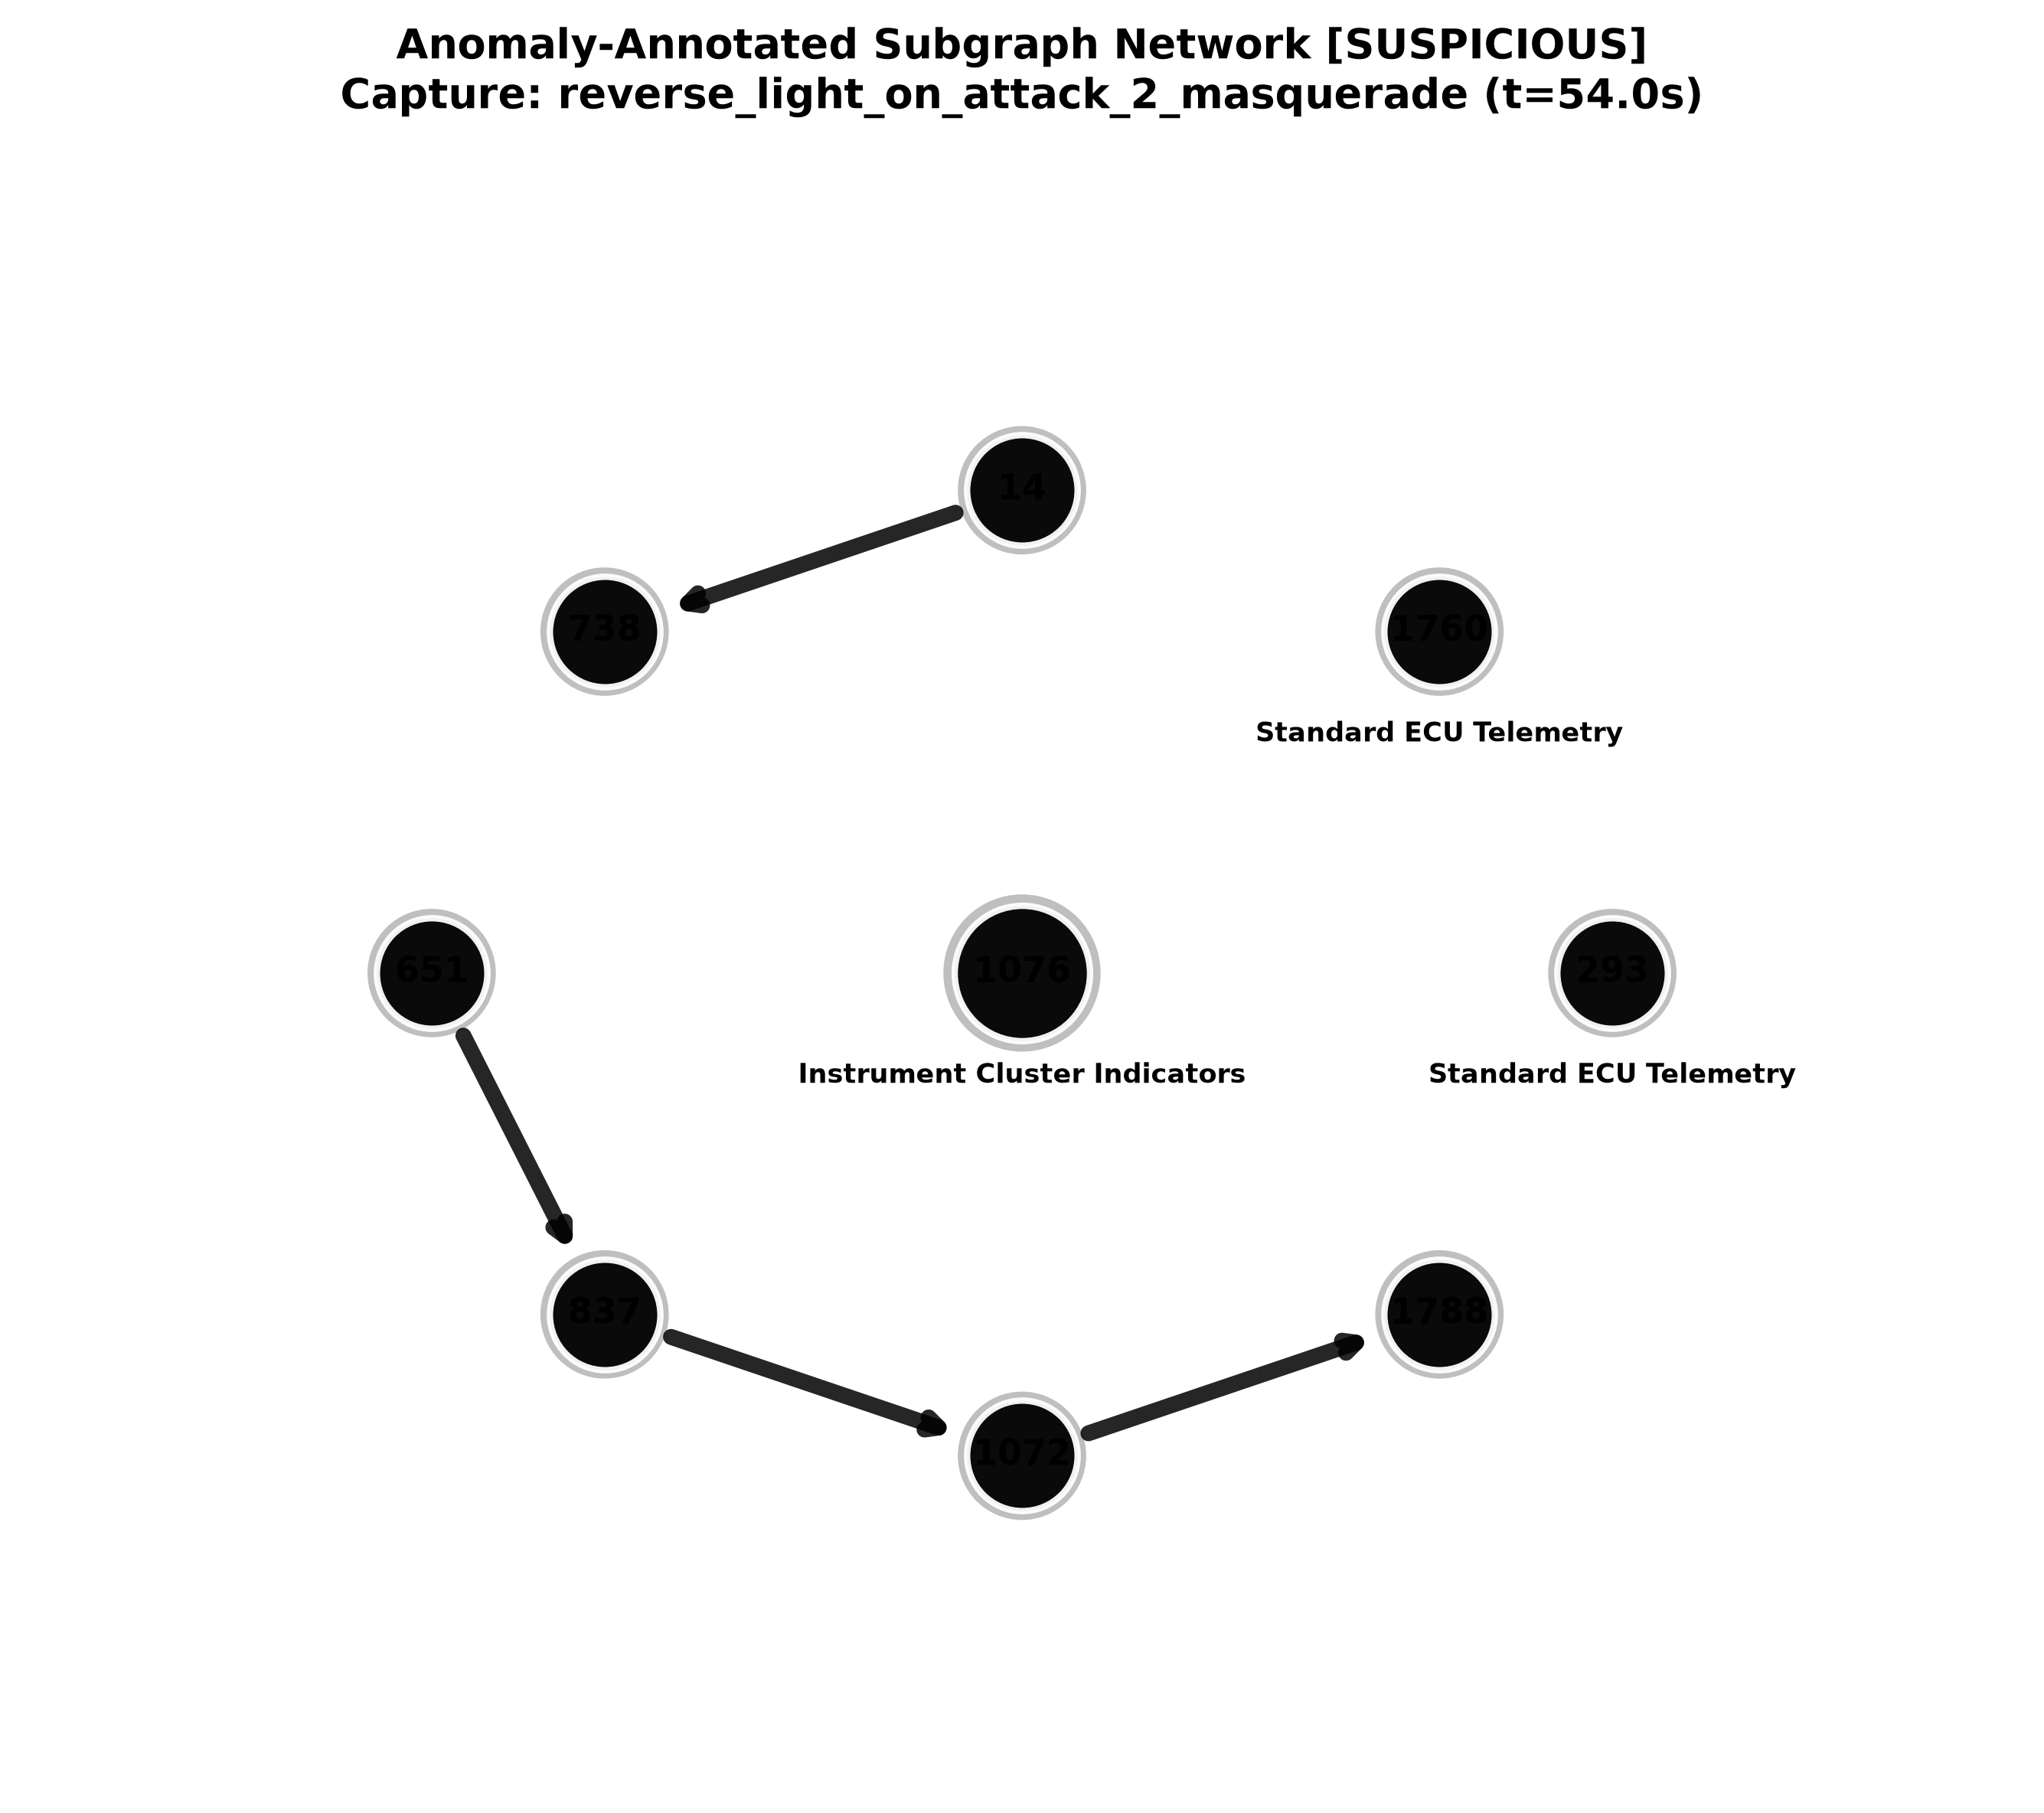

In [23]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_03_reverse_light_on_attack_2_masquerade_subgraph.png"))


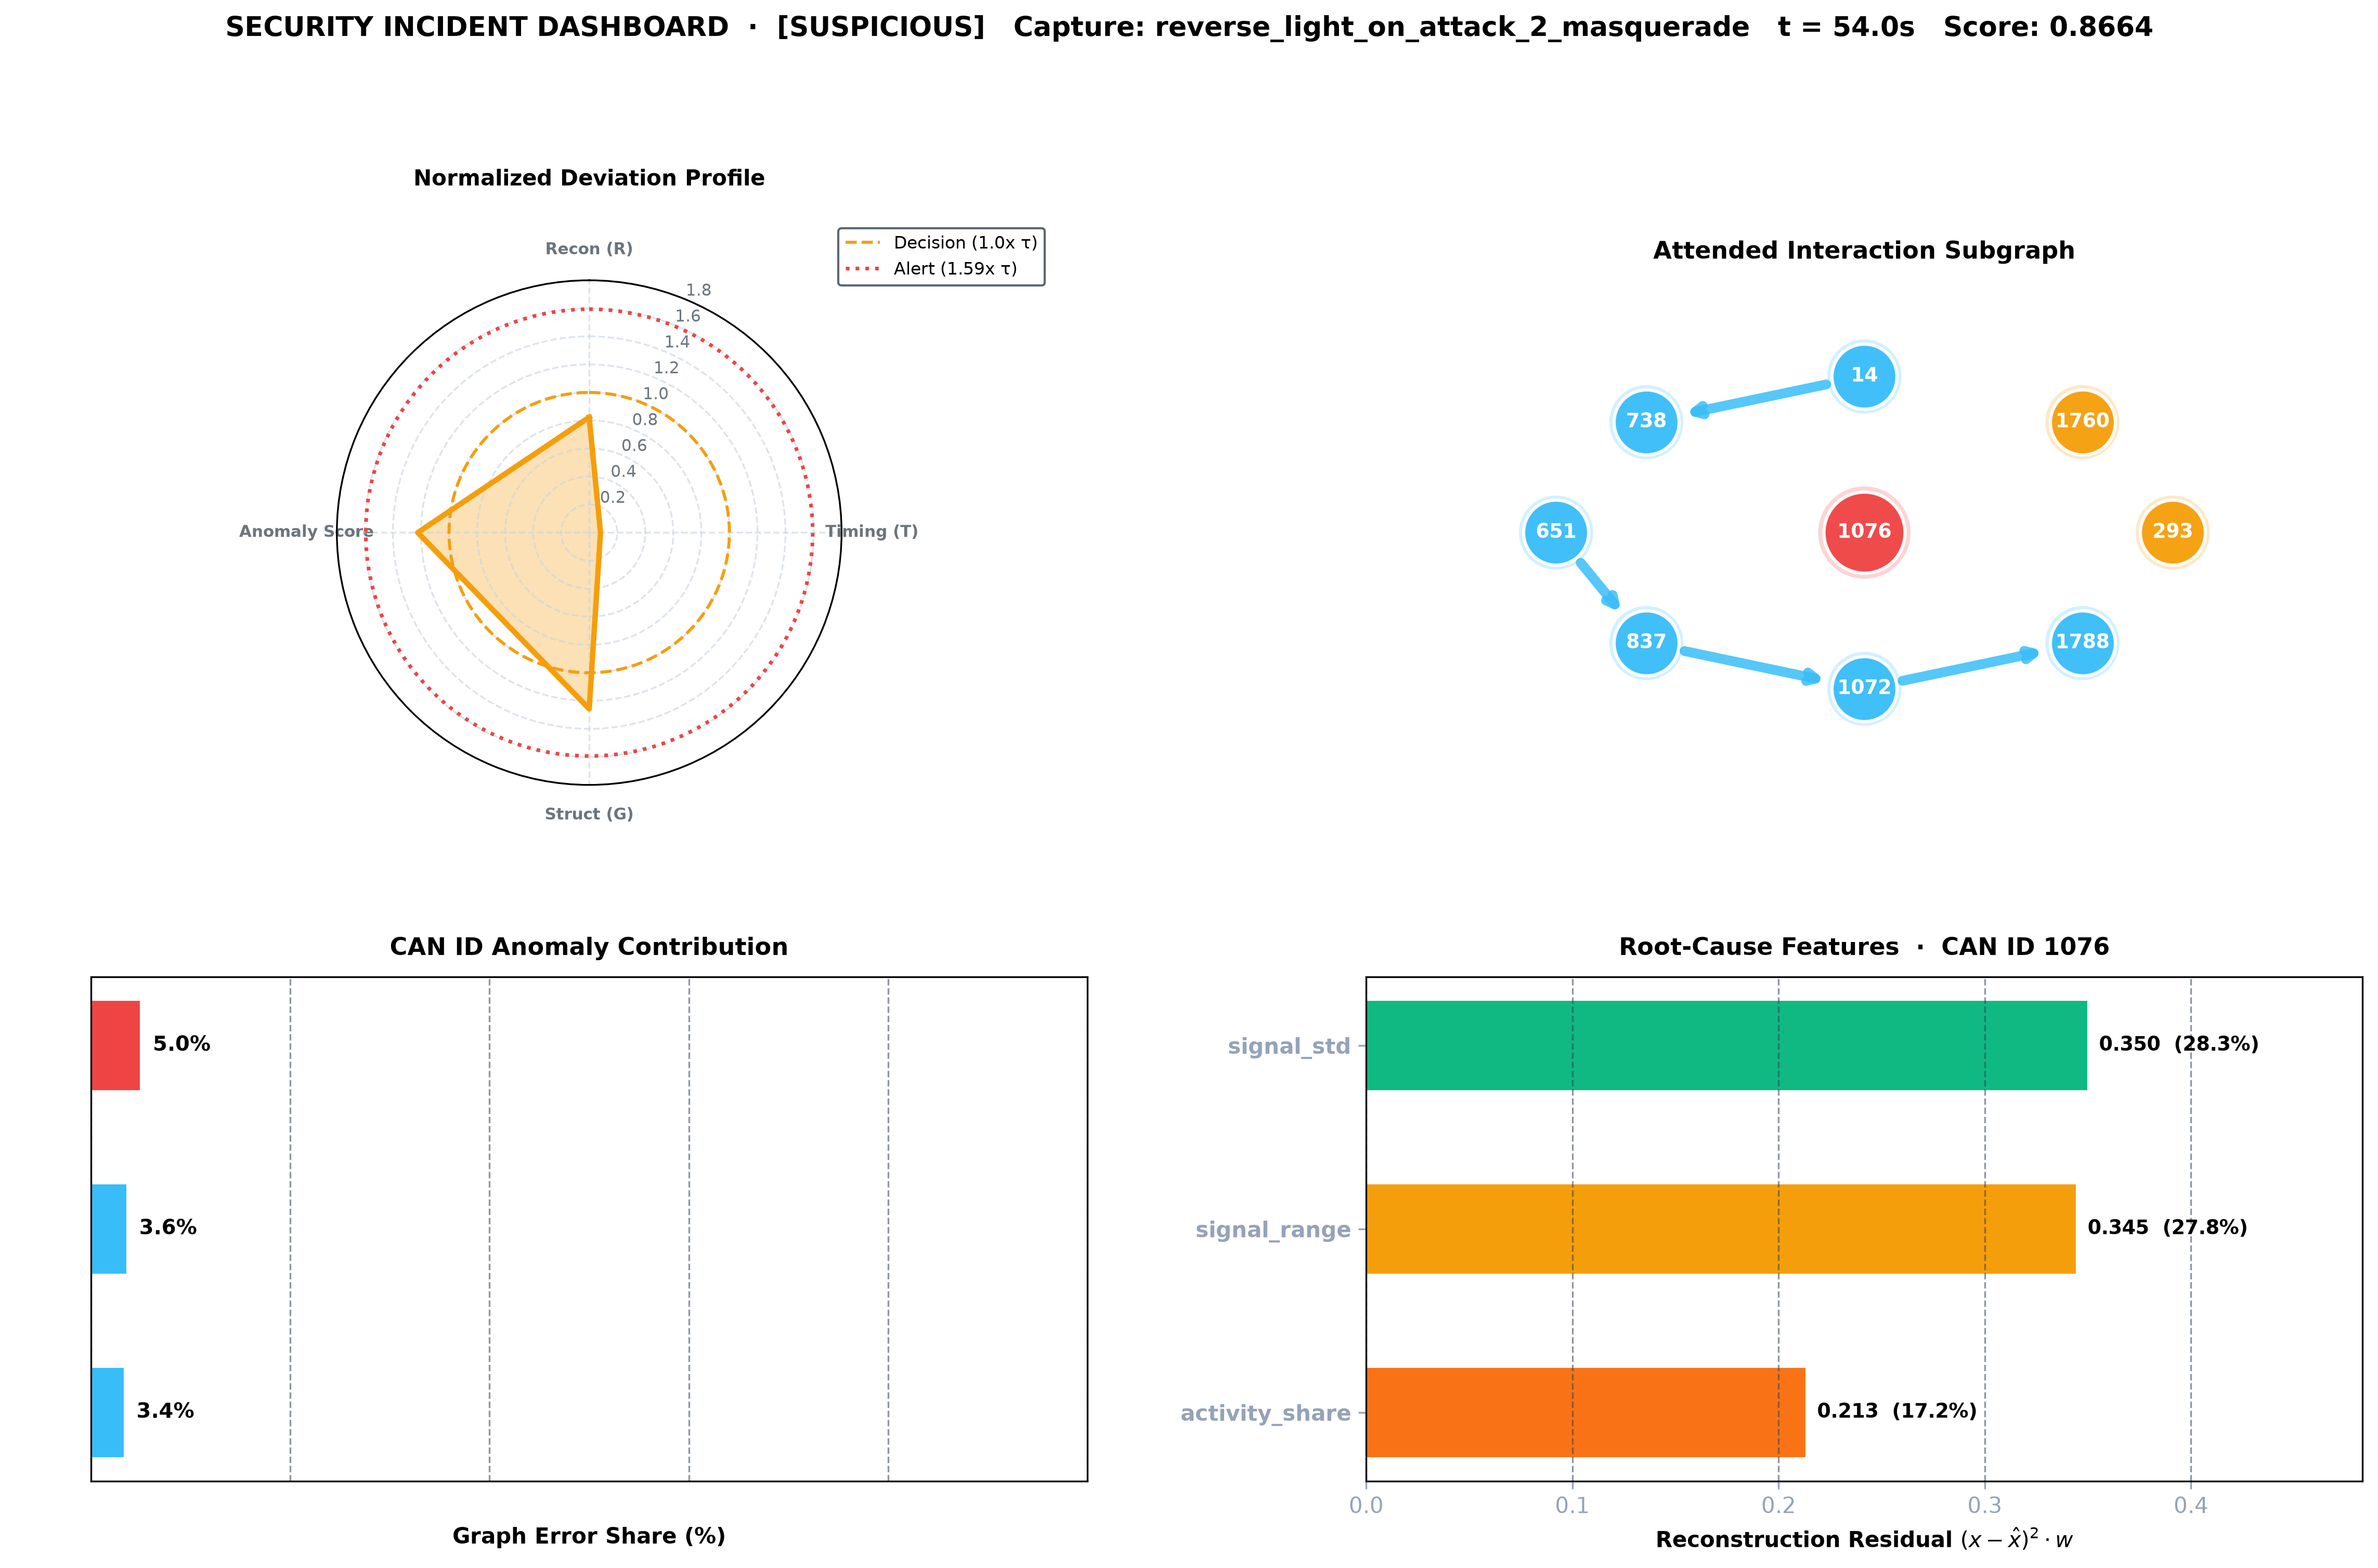

In [24]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_03_reverse_light_on_attack_2_masquerade_dashboard.png"))


### Incident 04: Correlated Signal Attack [SUSPICIOUS]
Forensic explanation visual artifacts for `correlated_signal_attack_2_masquerade`.

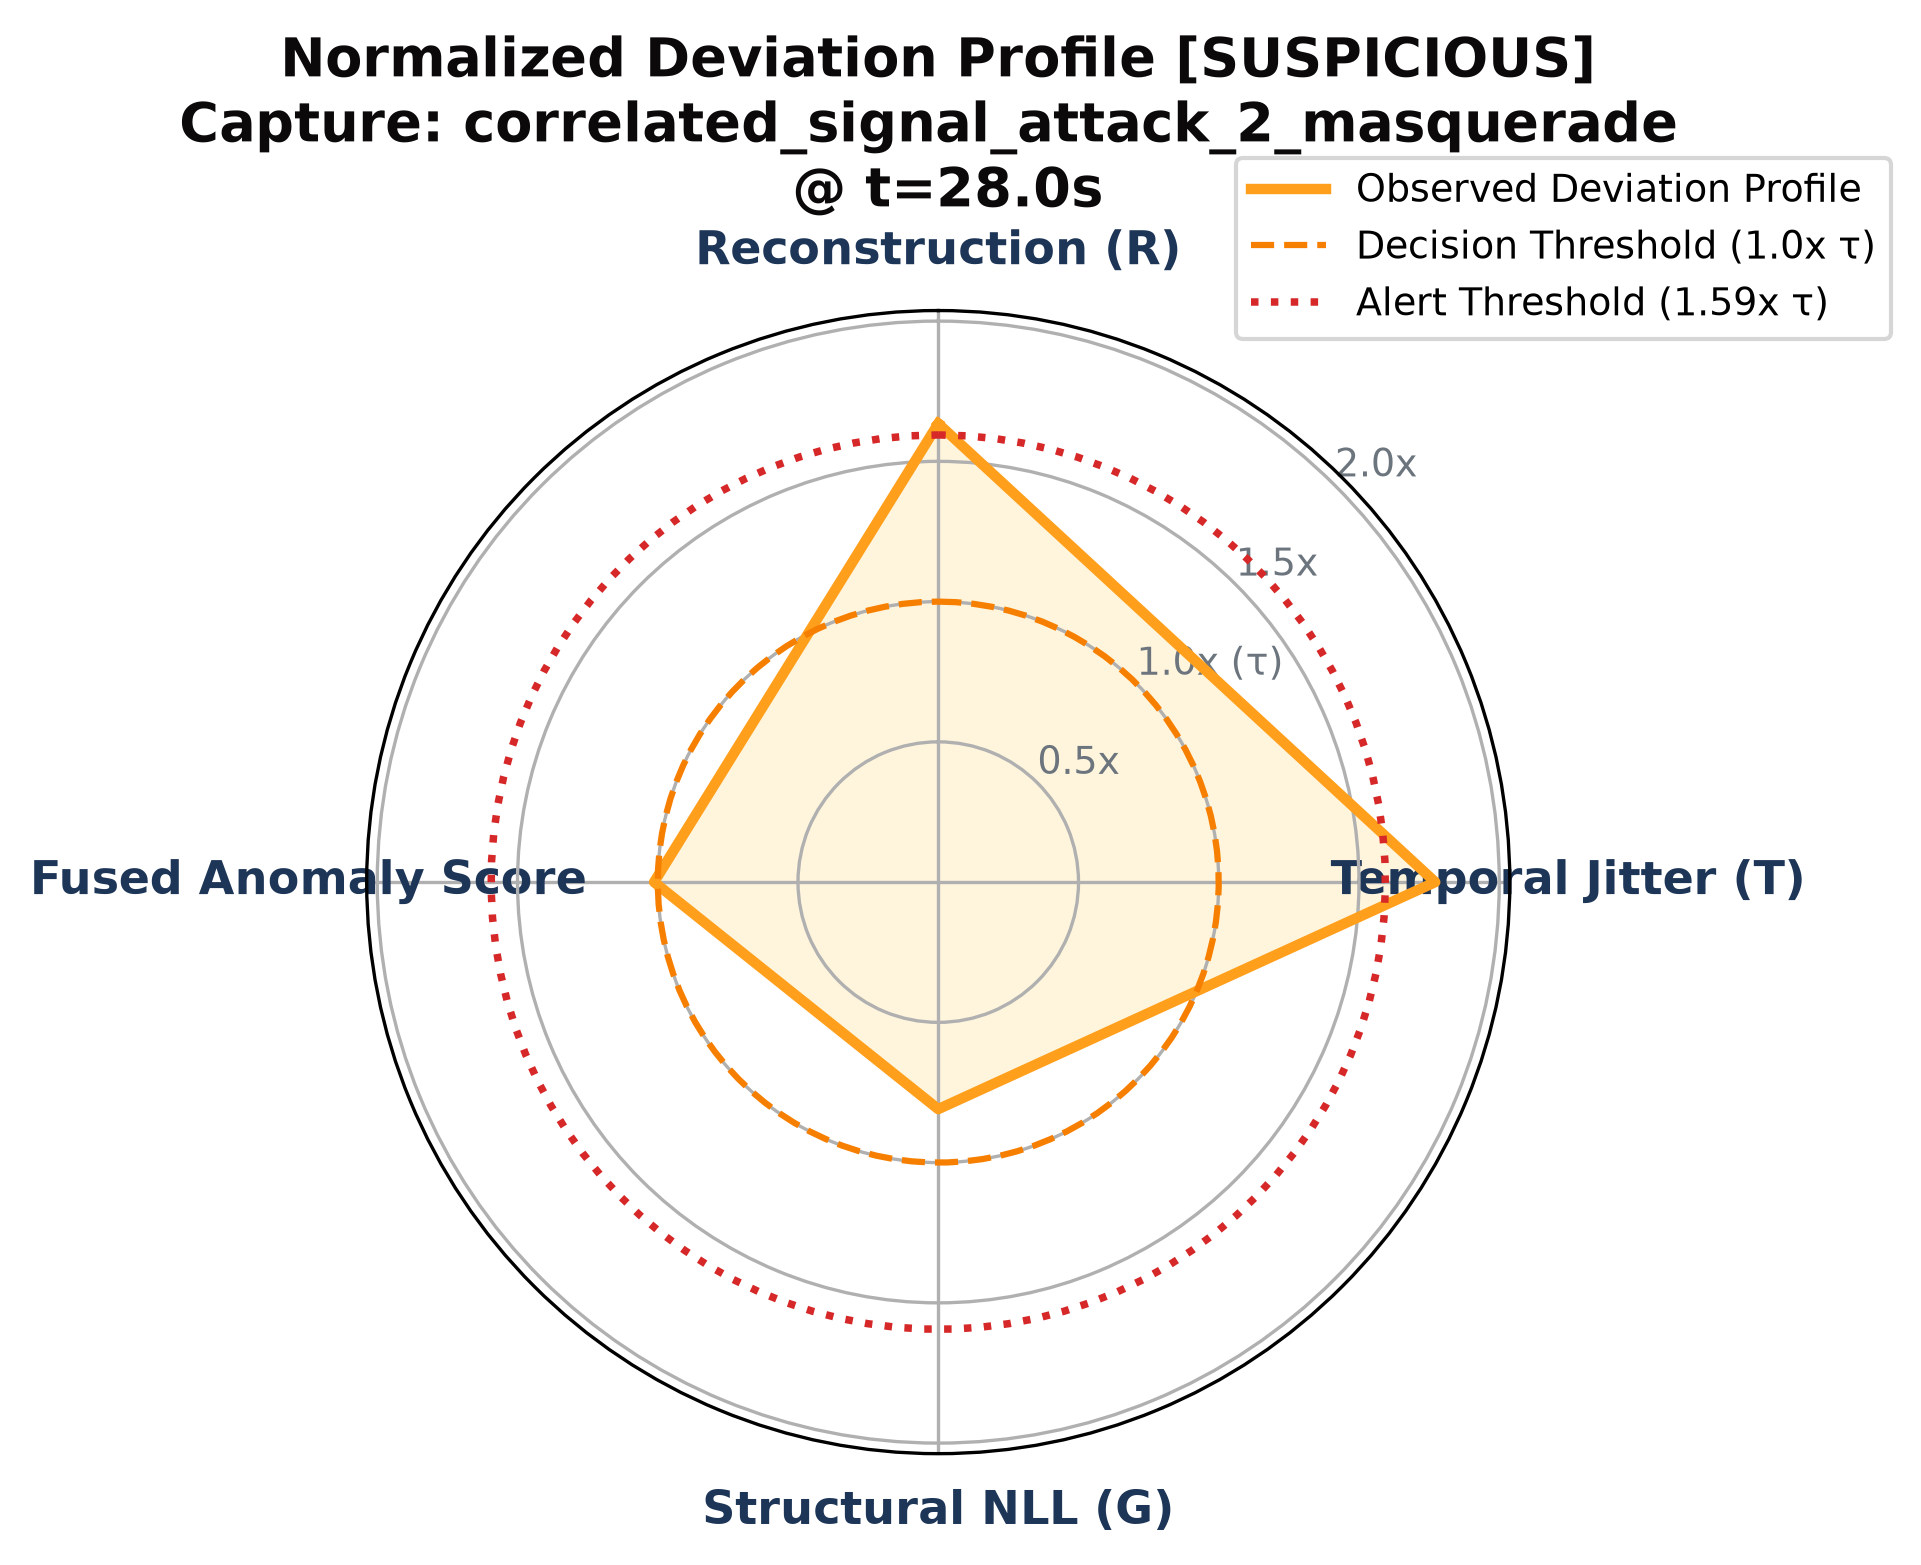

In [25]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_04_correlated_signal_attack_2_masquerade_radar_chart.png"))


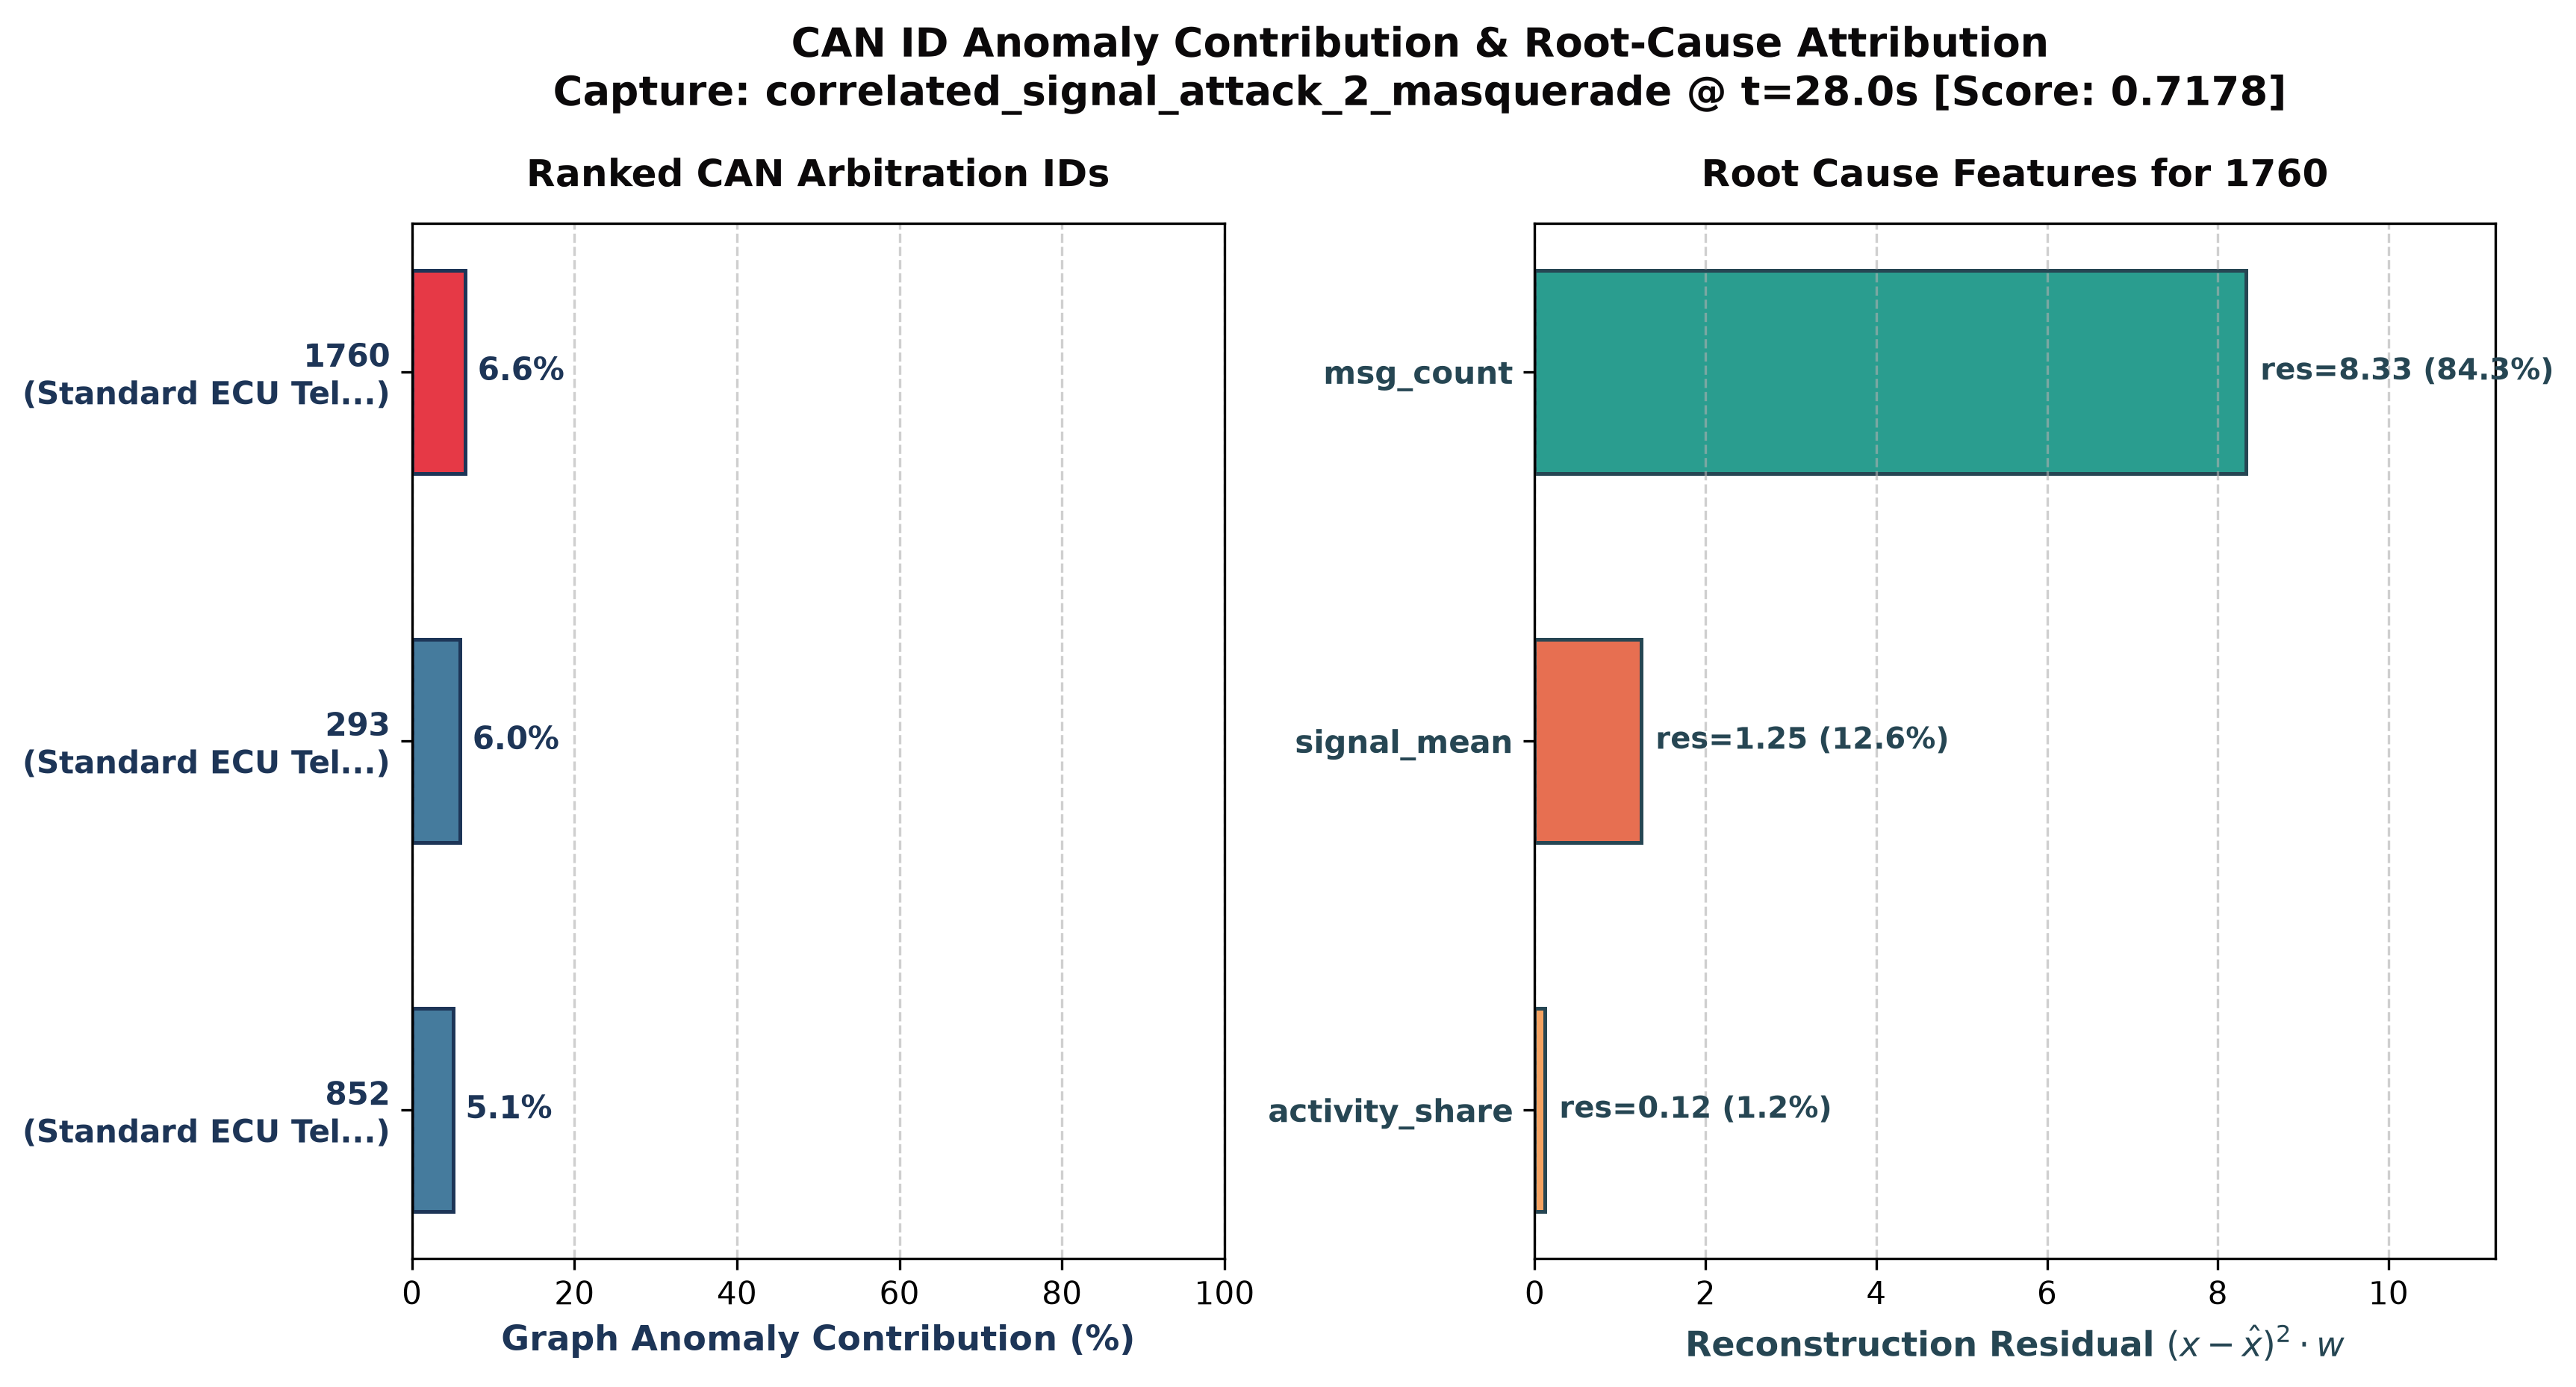

In [26]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_04_correlated_signal_attack_2_masquerade_id_attribution.png"))


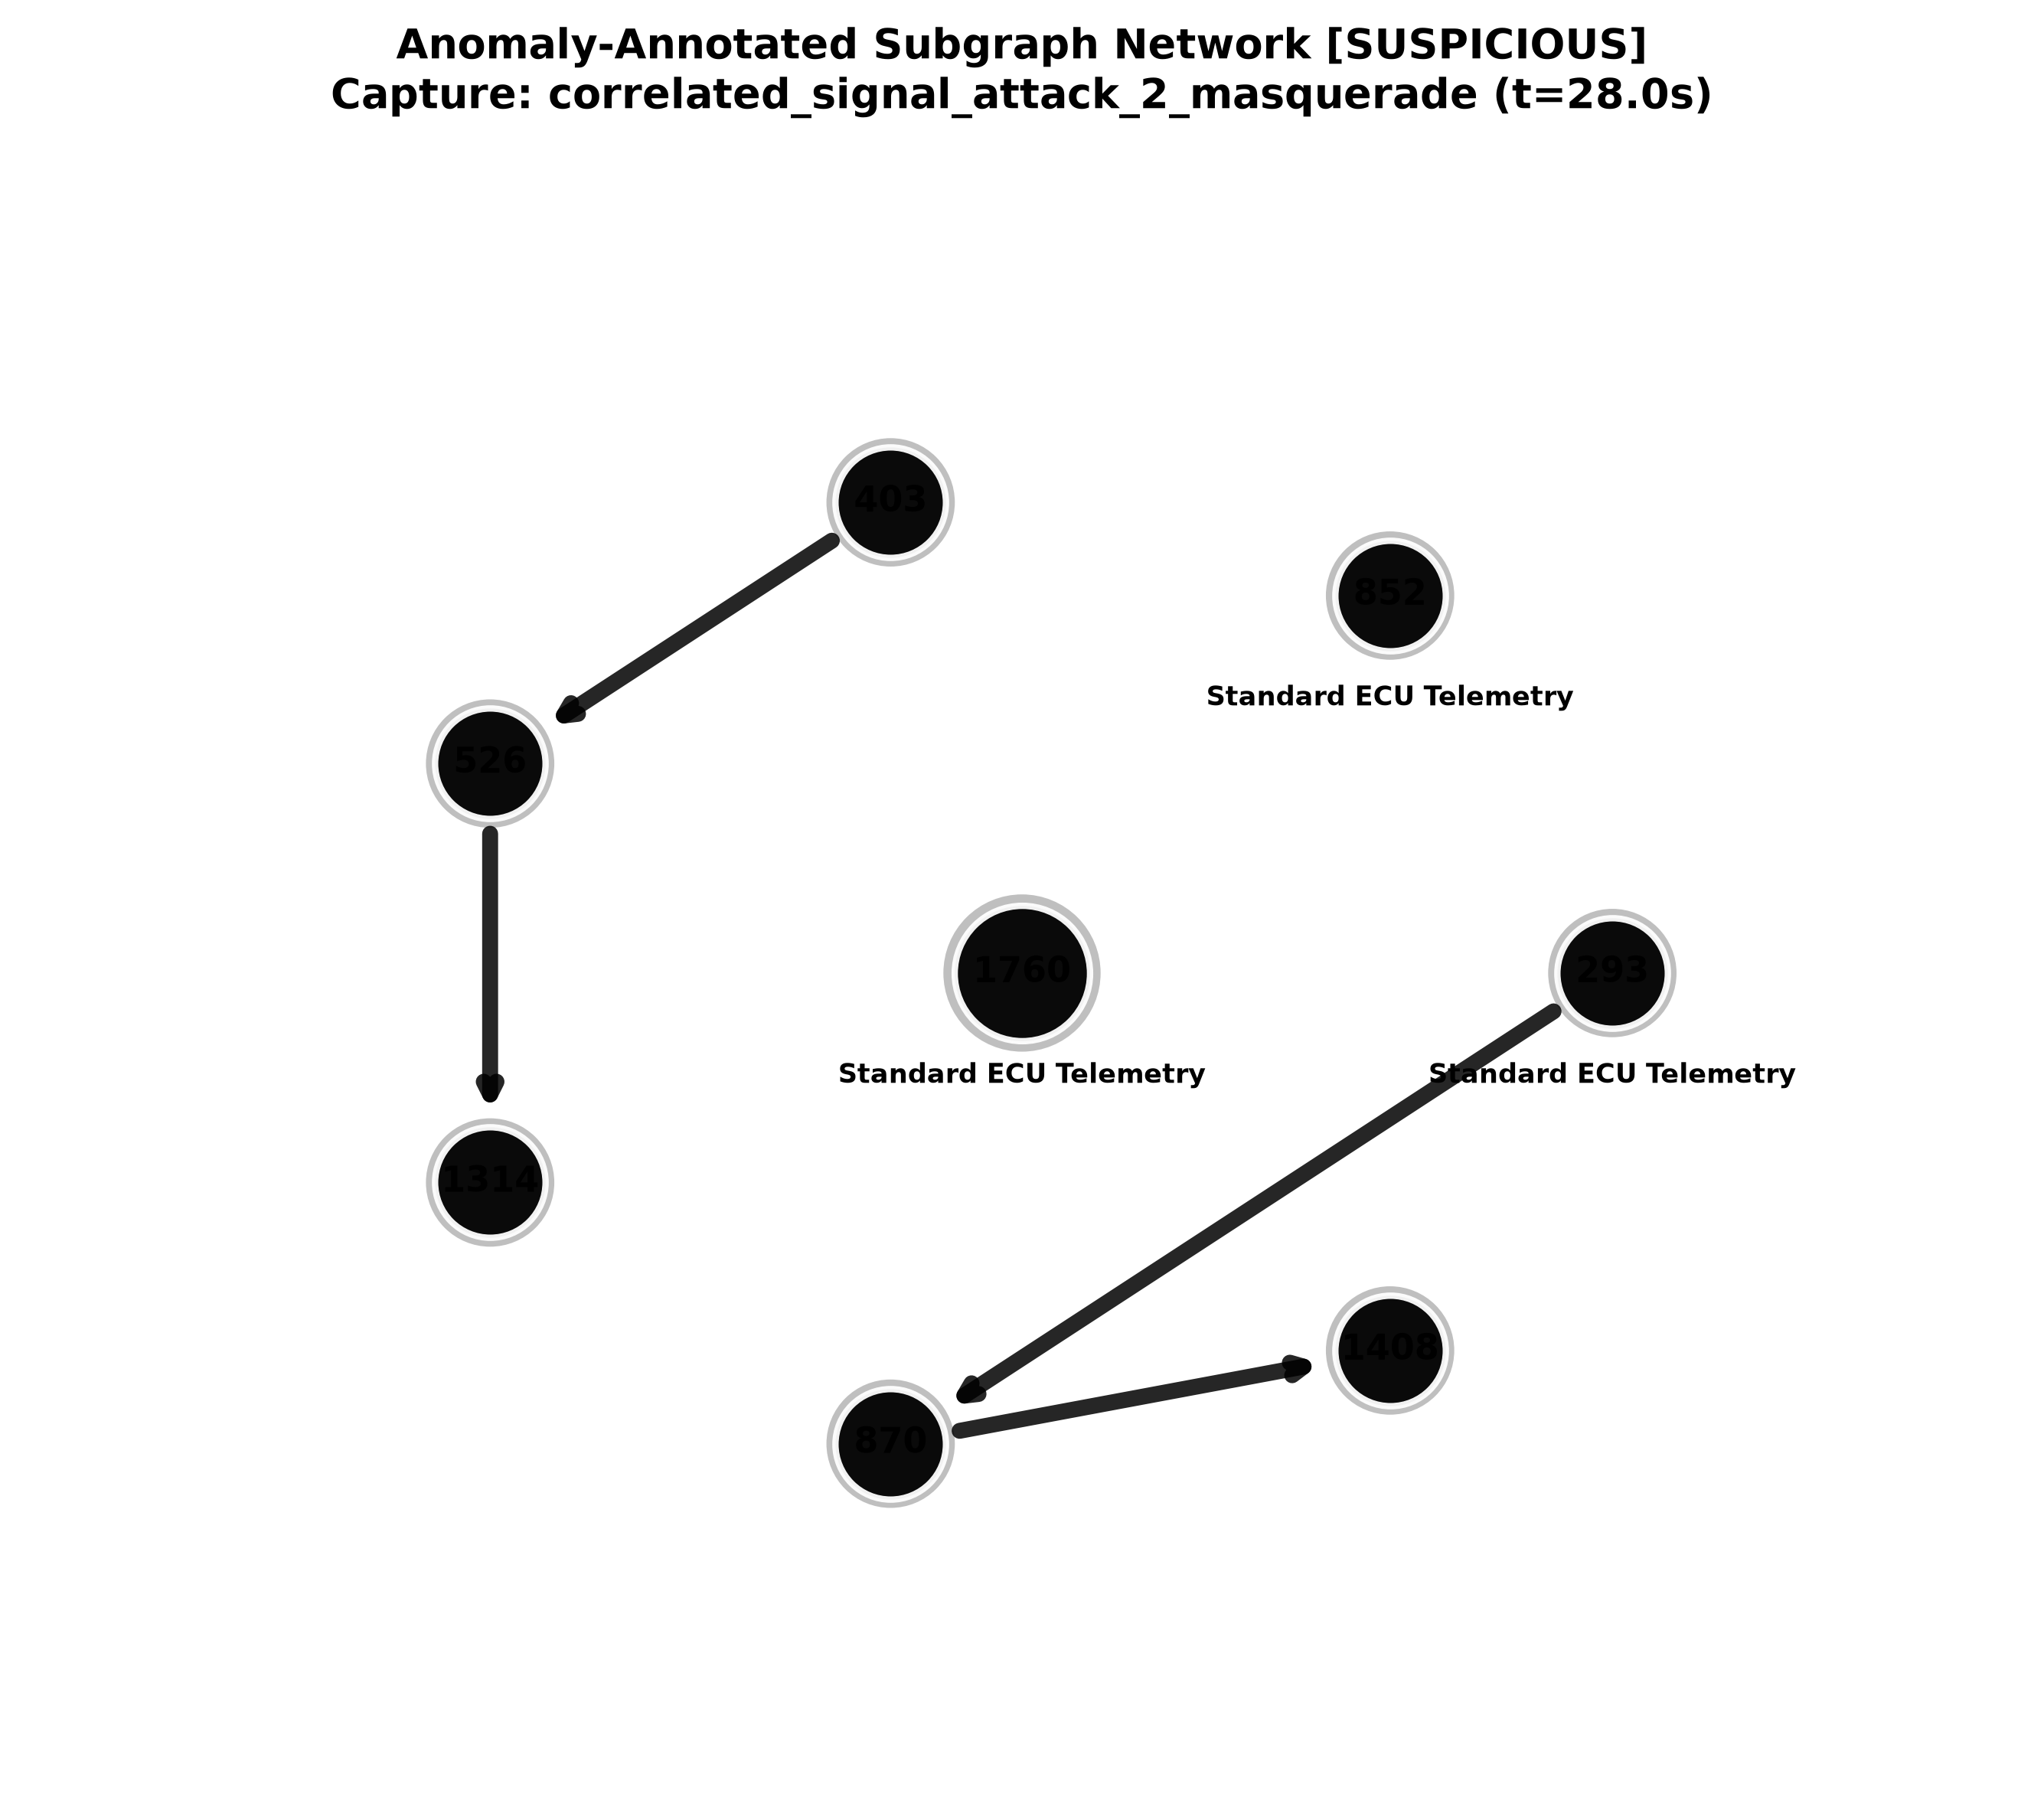

In [27]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_04_correlated_signal_attack_2_masquerade_subgraph.png"))


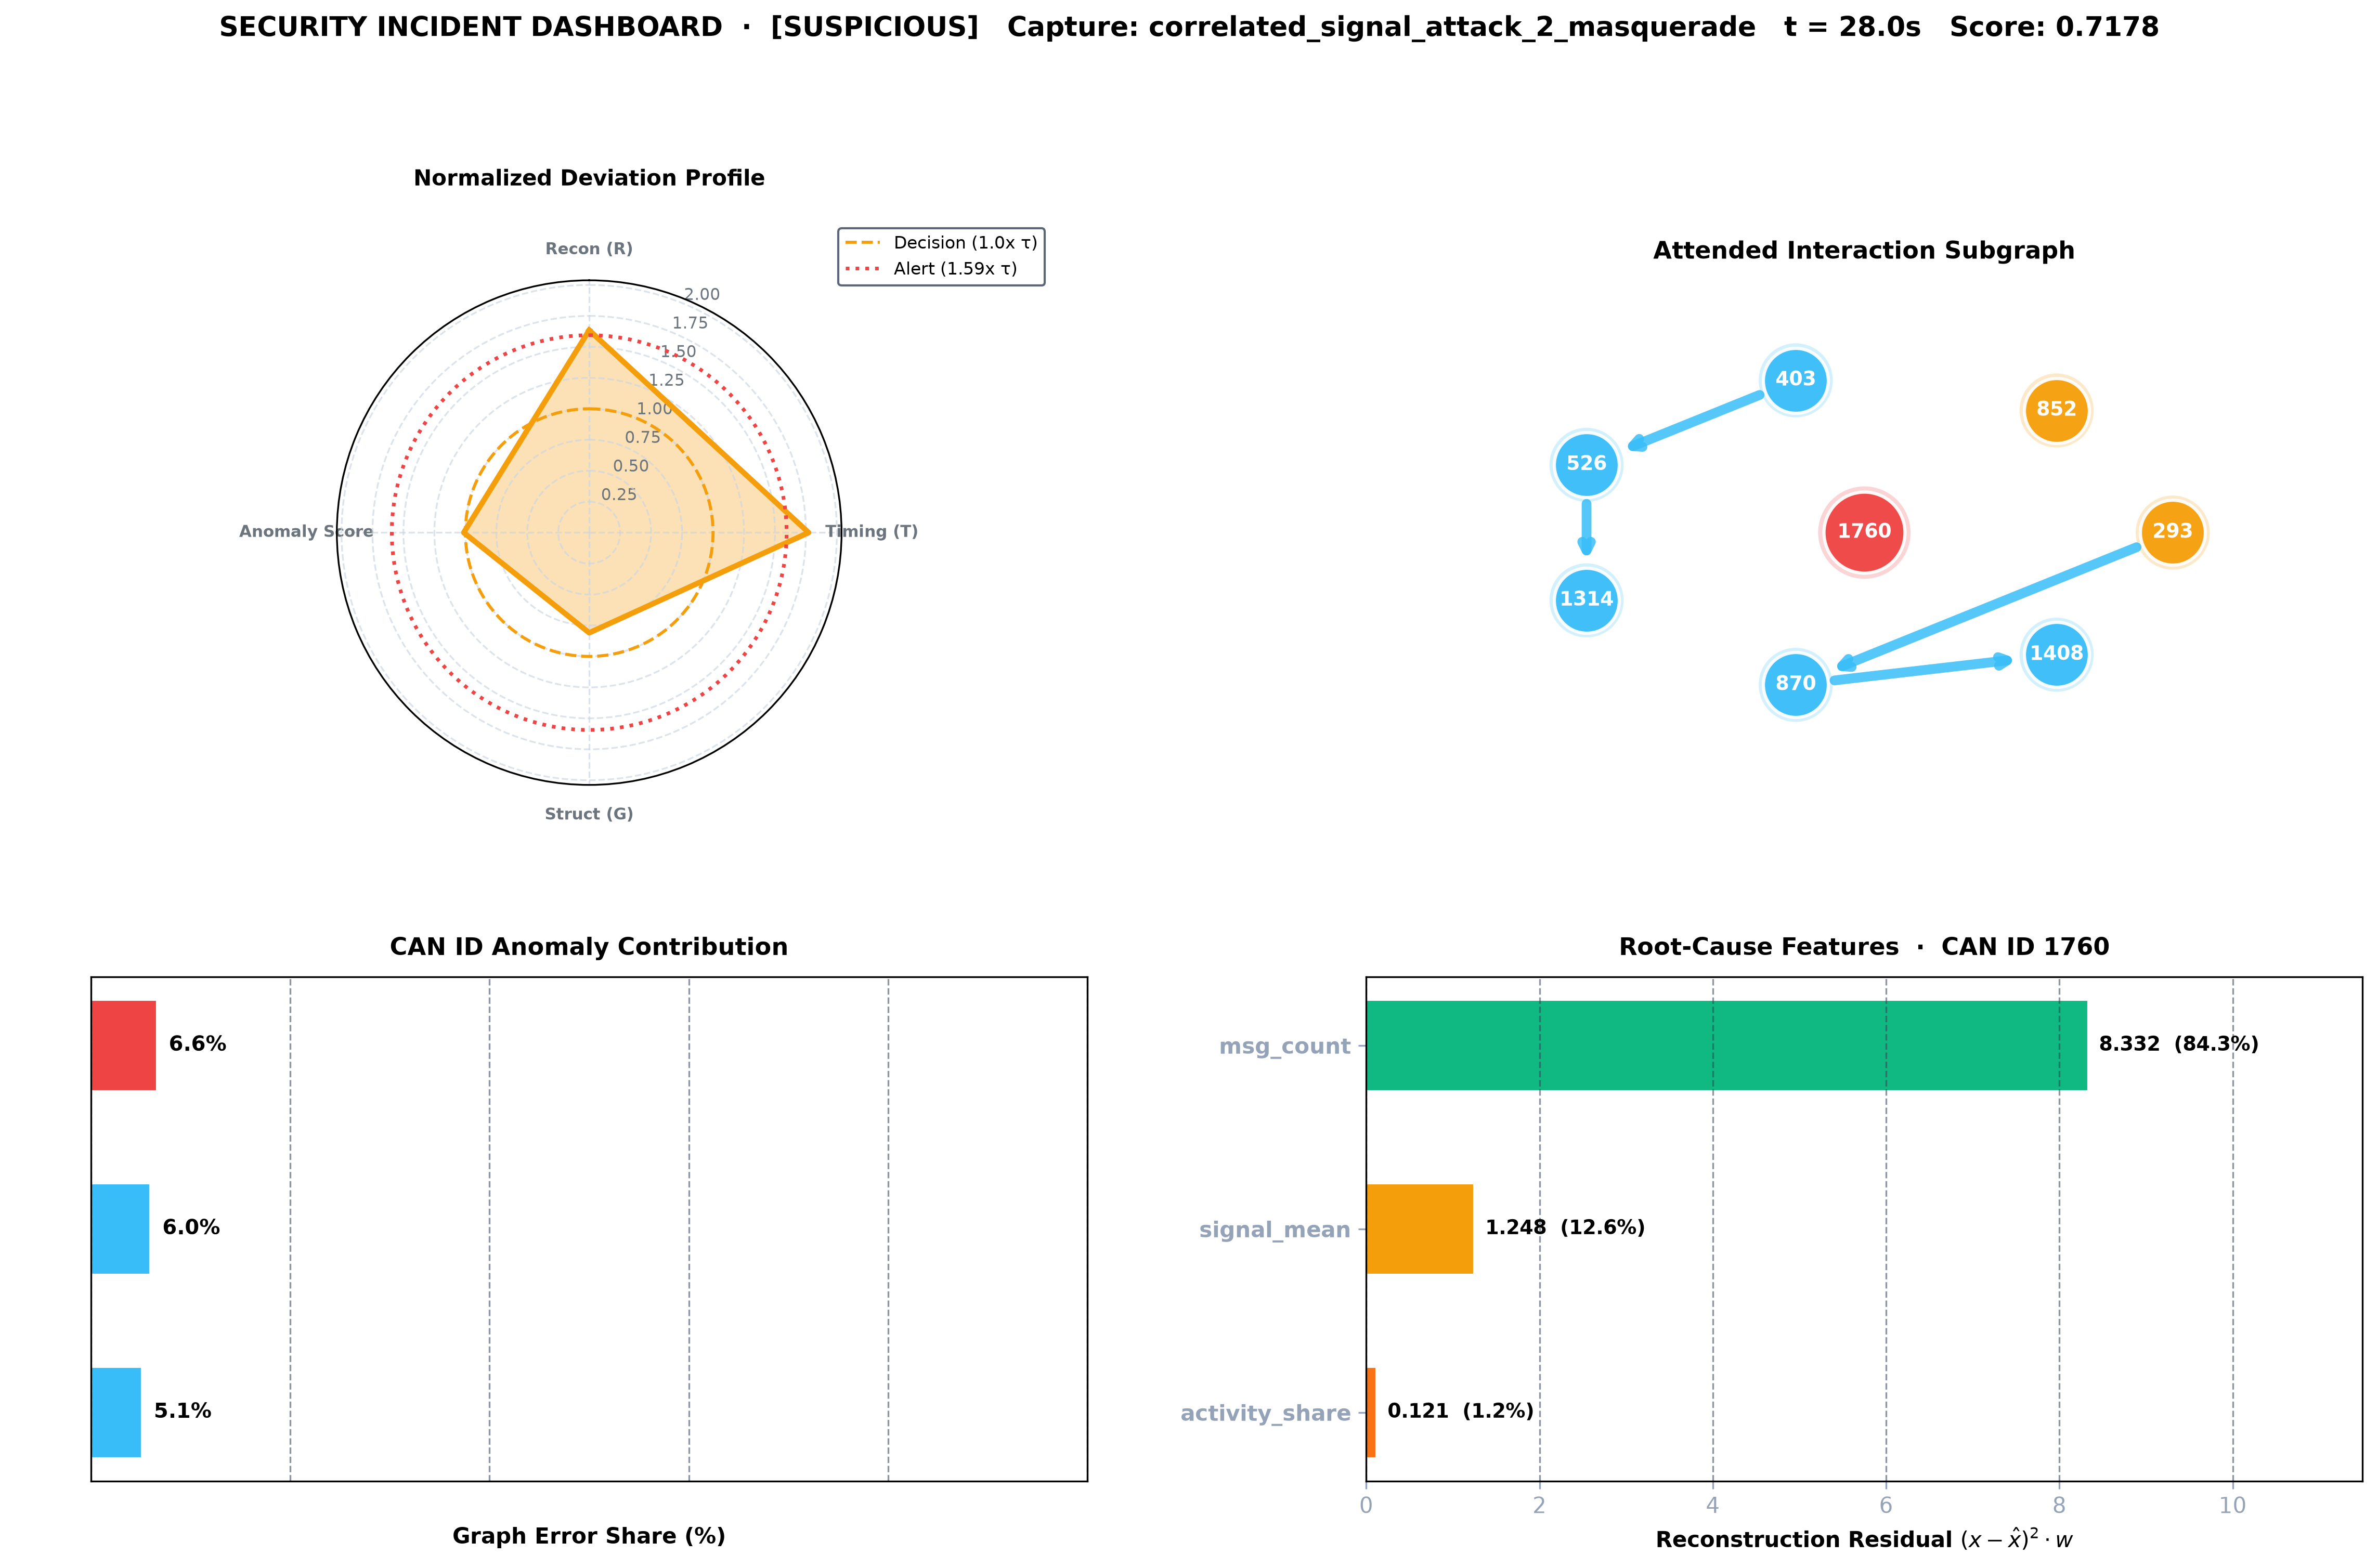

In [28]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_04_correlated_signal_attack_2_masquerade_dashboard.png"))


### Incident 05: Benign Baseline Ambient Traffic [NORMAL]
Forensic explanation visual artifacts for `benign_baseline_ambient_dyno_drive_radio_infotainment`.

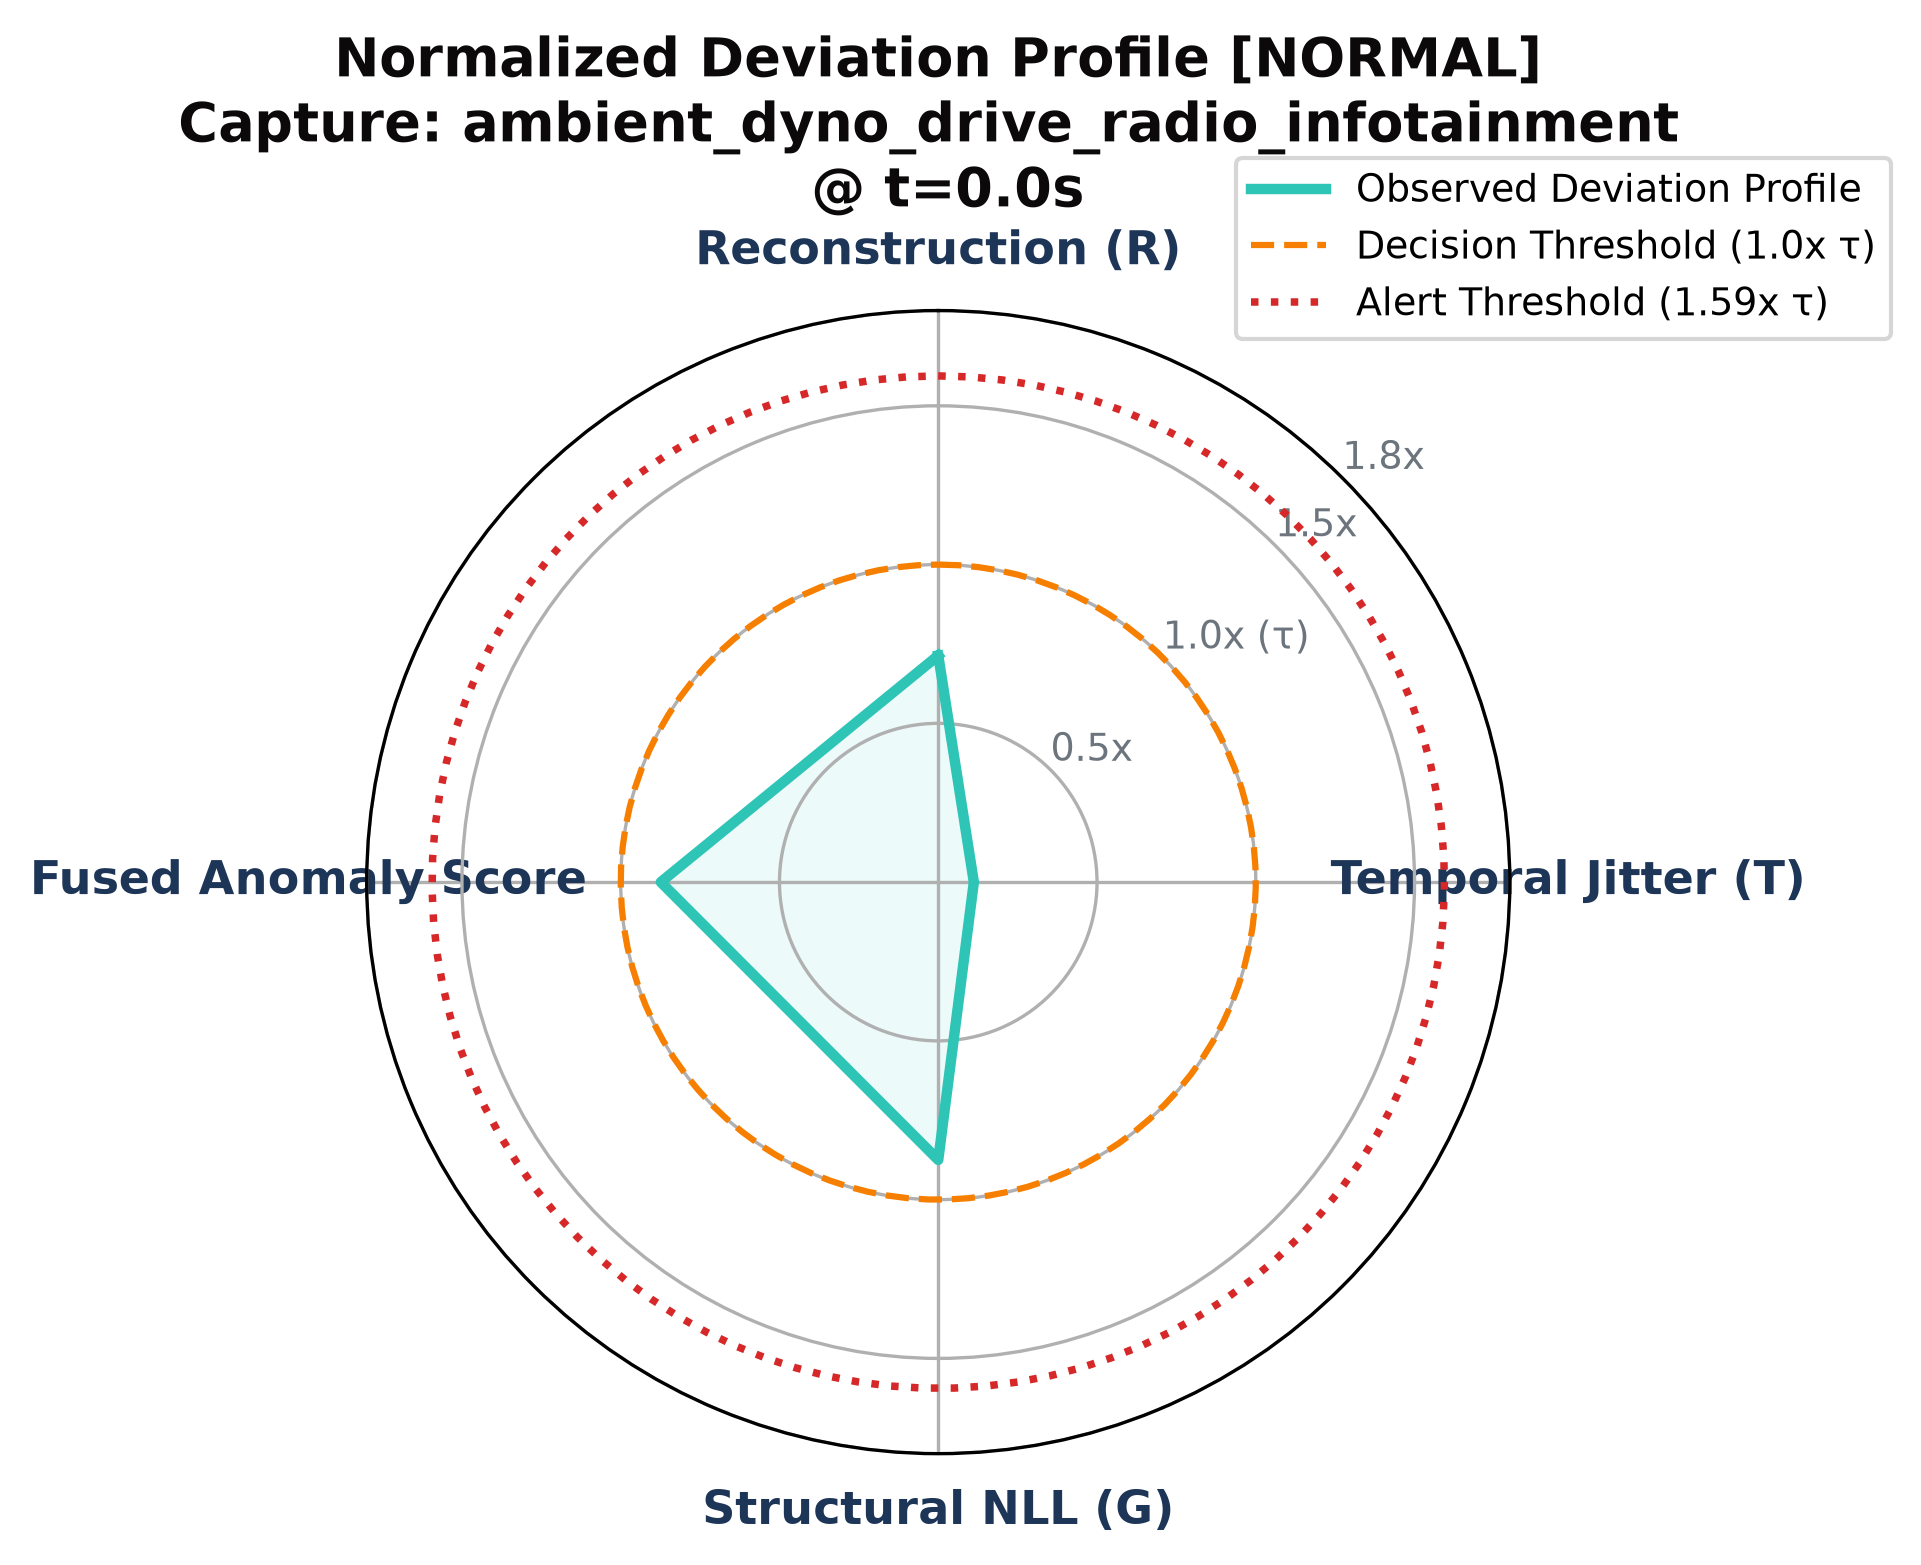

In [29]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_05_benign_baseline_ambient_dyno_drive_radio_infotainment_radar_chart.png"))


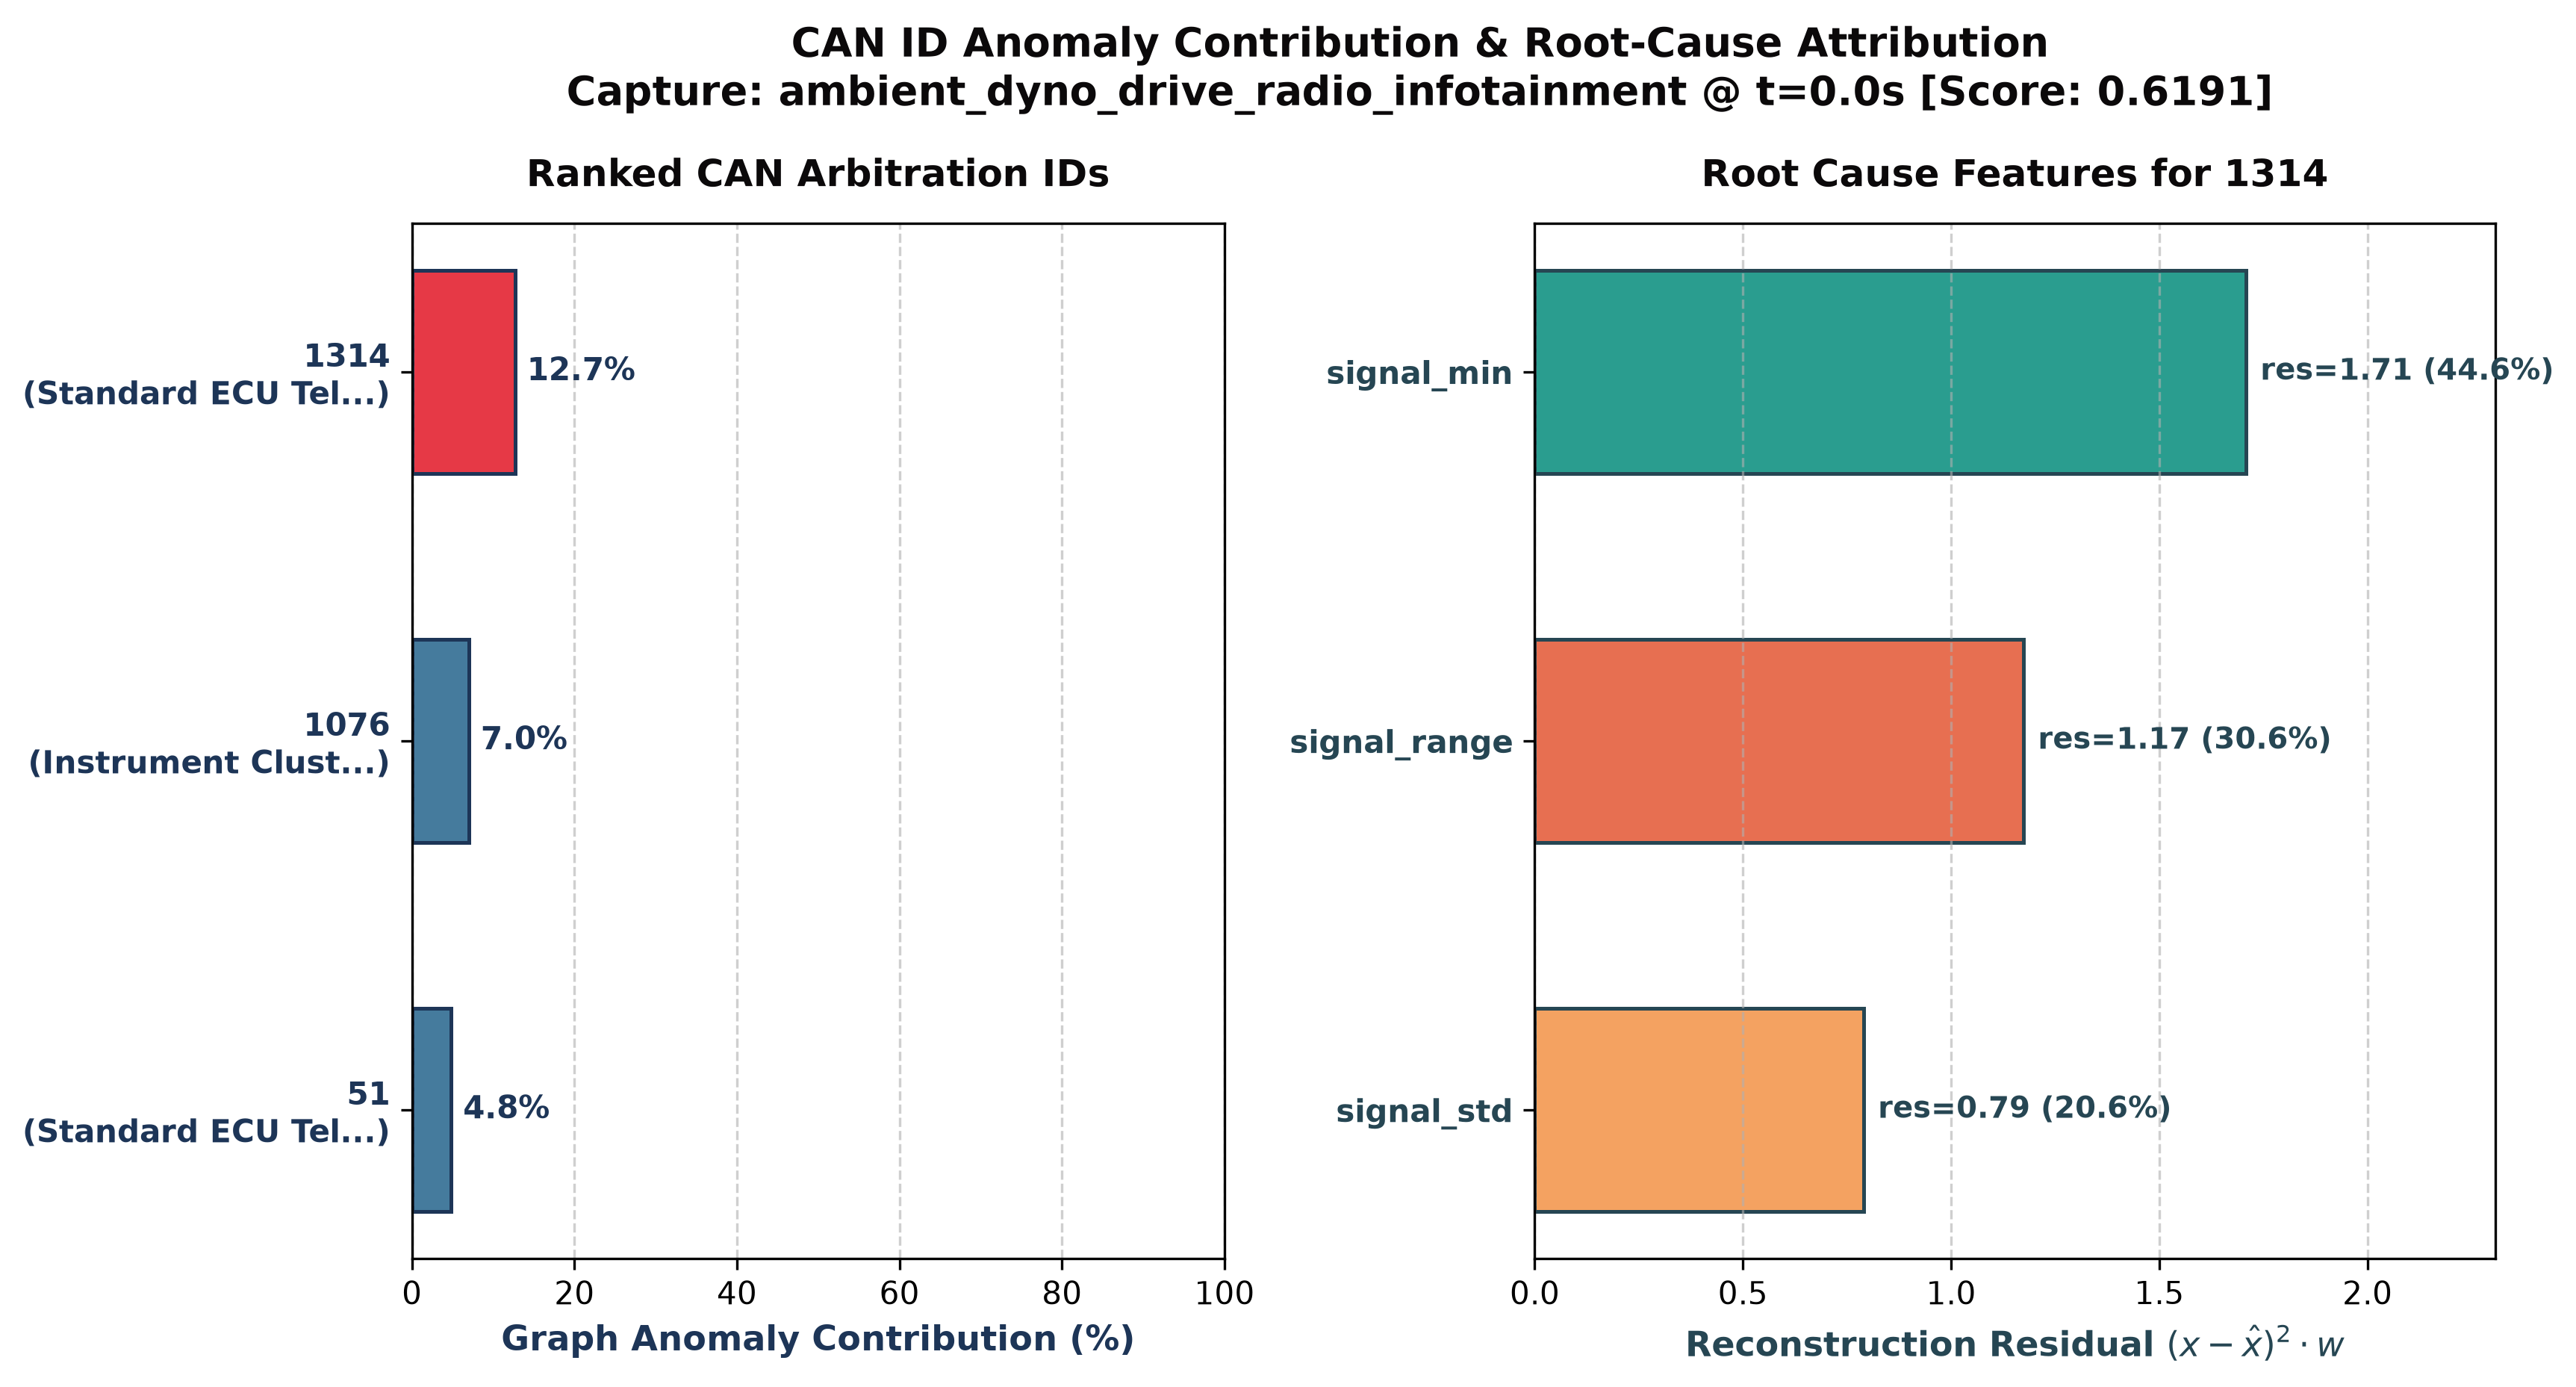

In [30]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_05_benign_baseline_ambient_dyno_drive_radio_infotainment_id_attribution.png"))


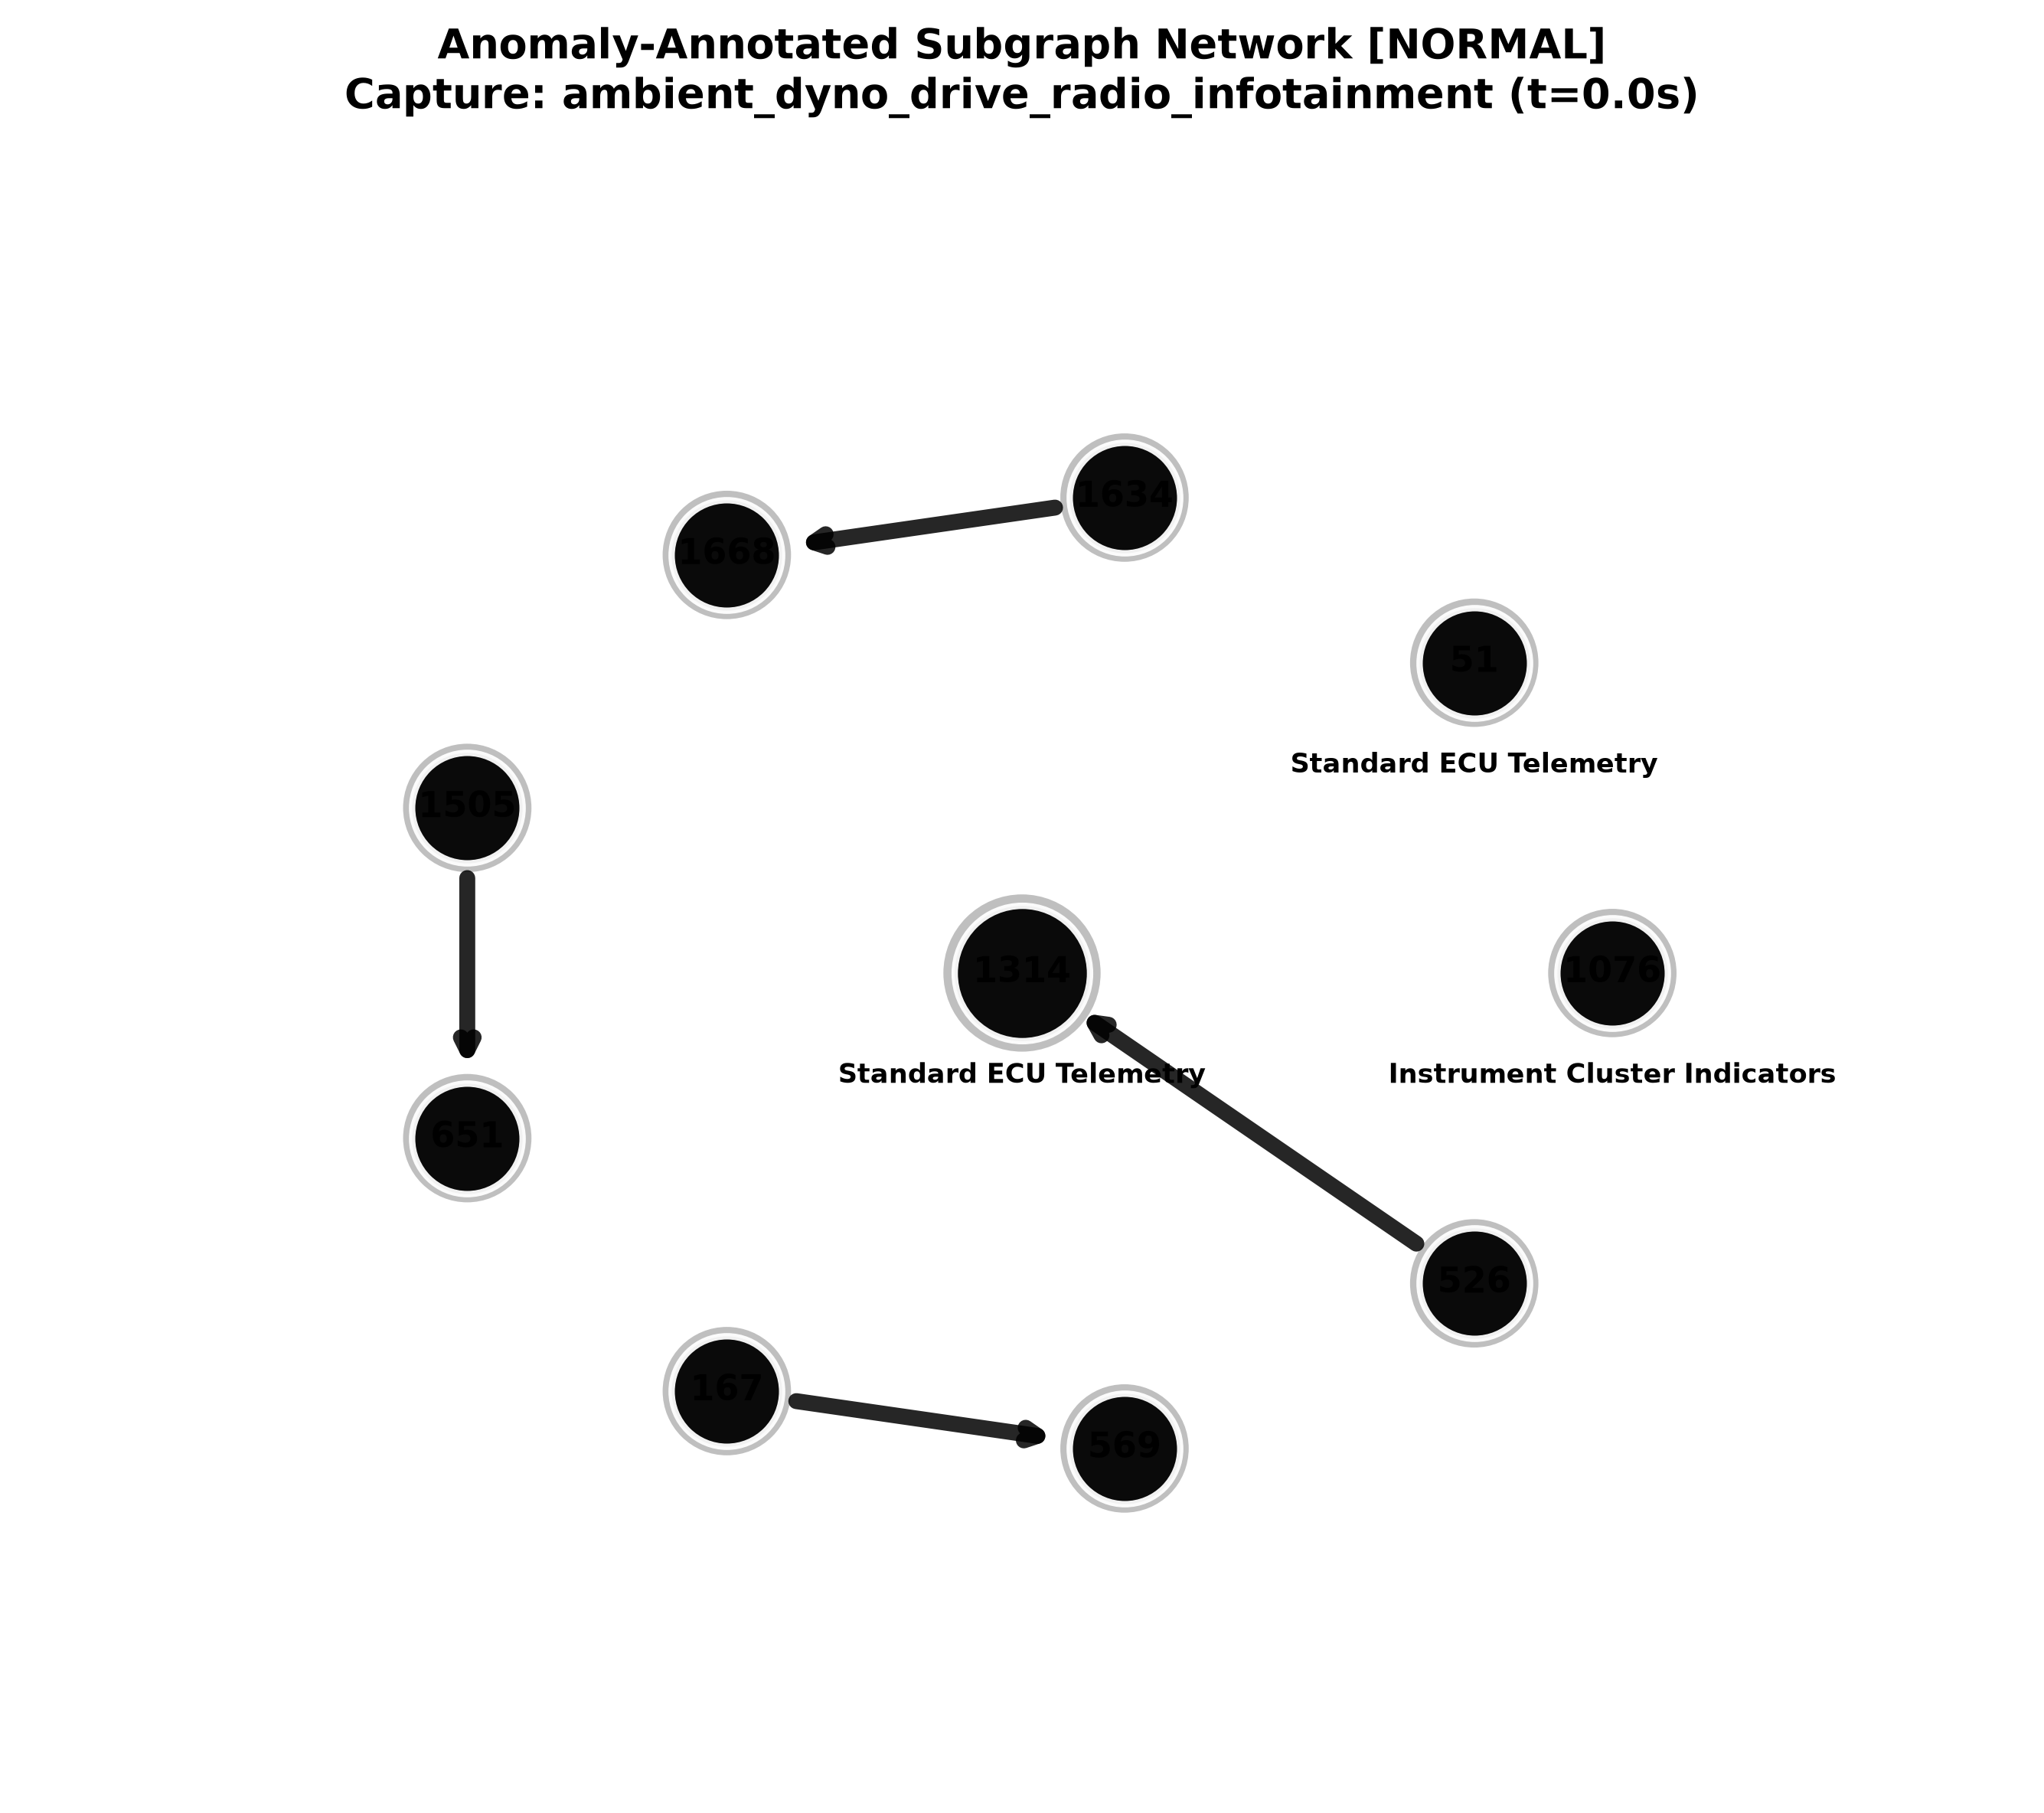

In [31]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_05_benign_baseline_ambient_dyno_drive_radio_infotainment_subgraph.png"))


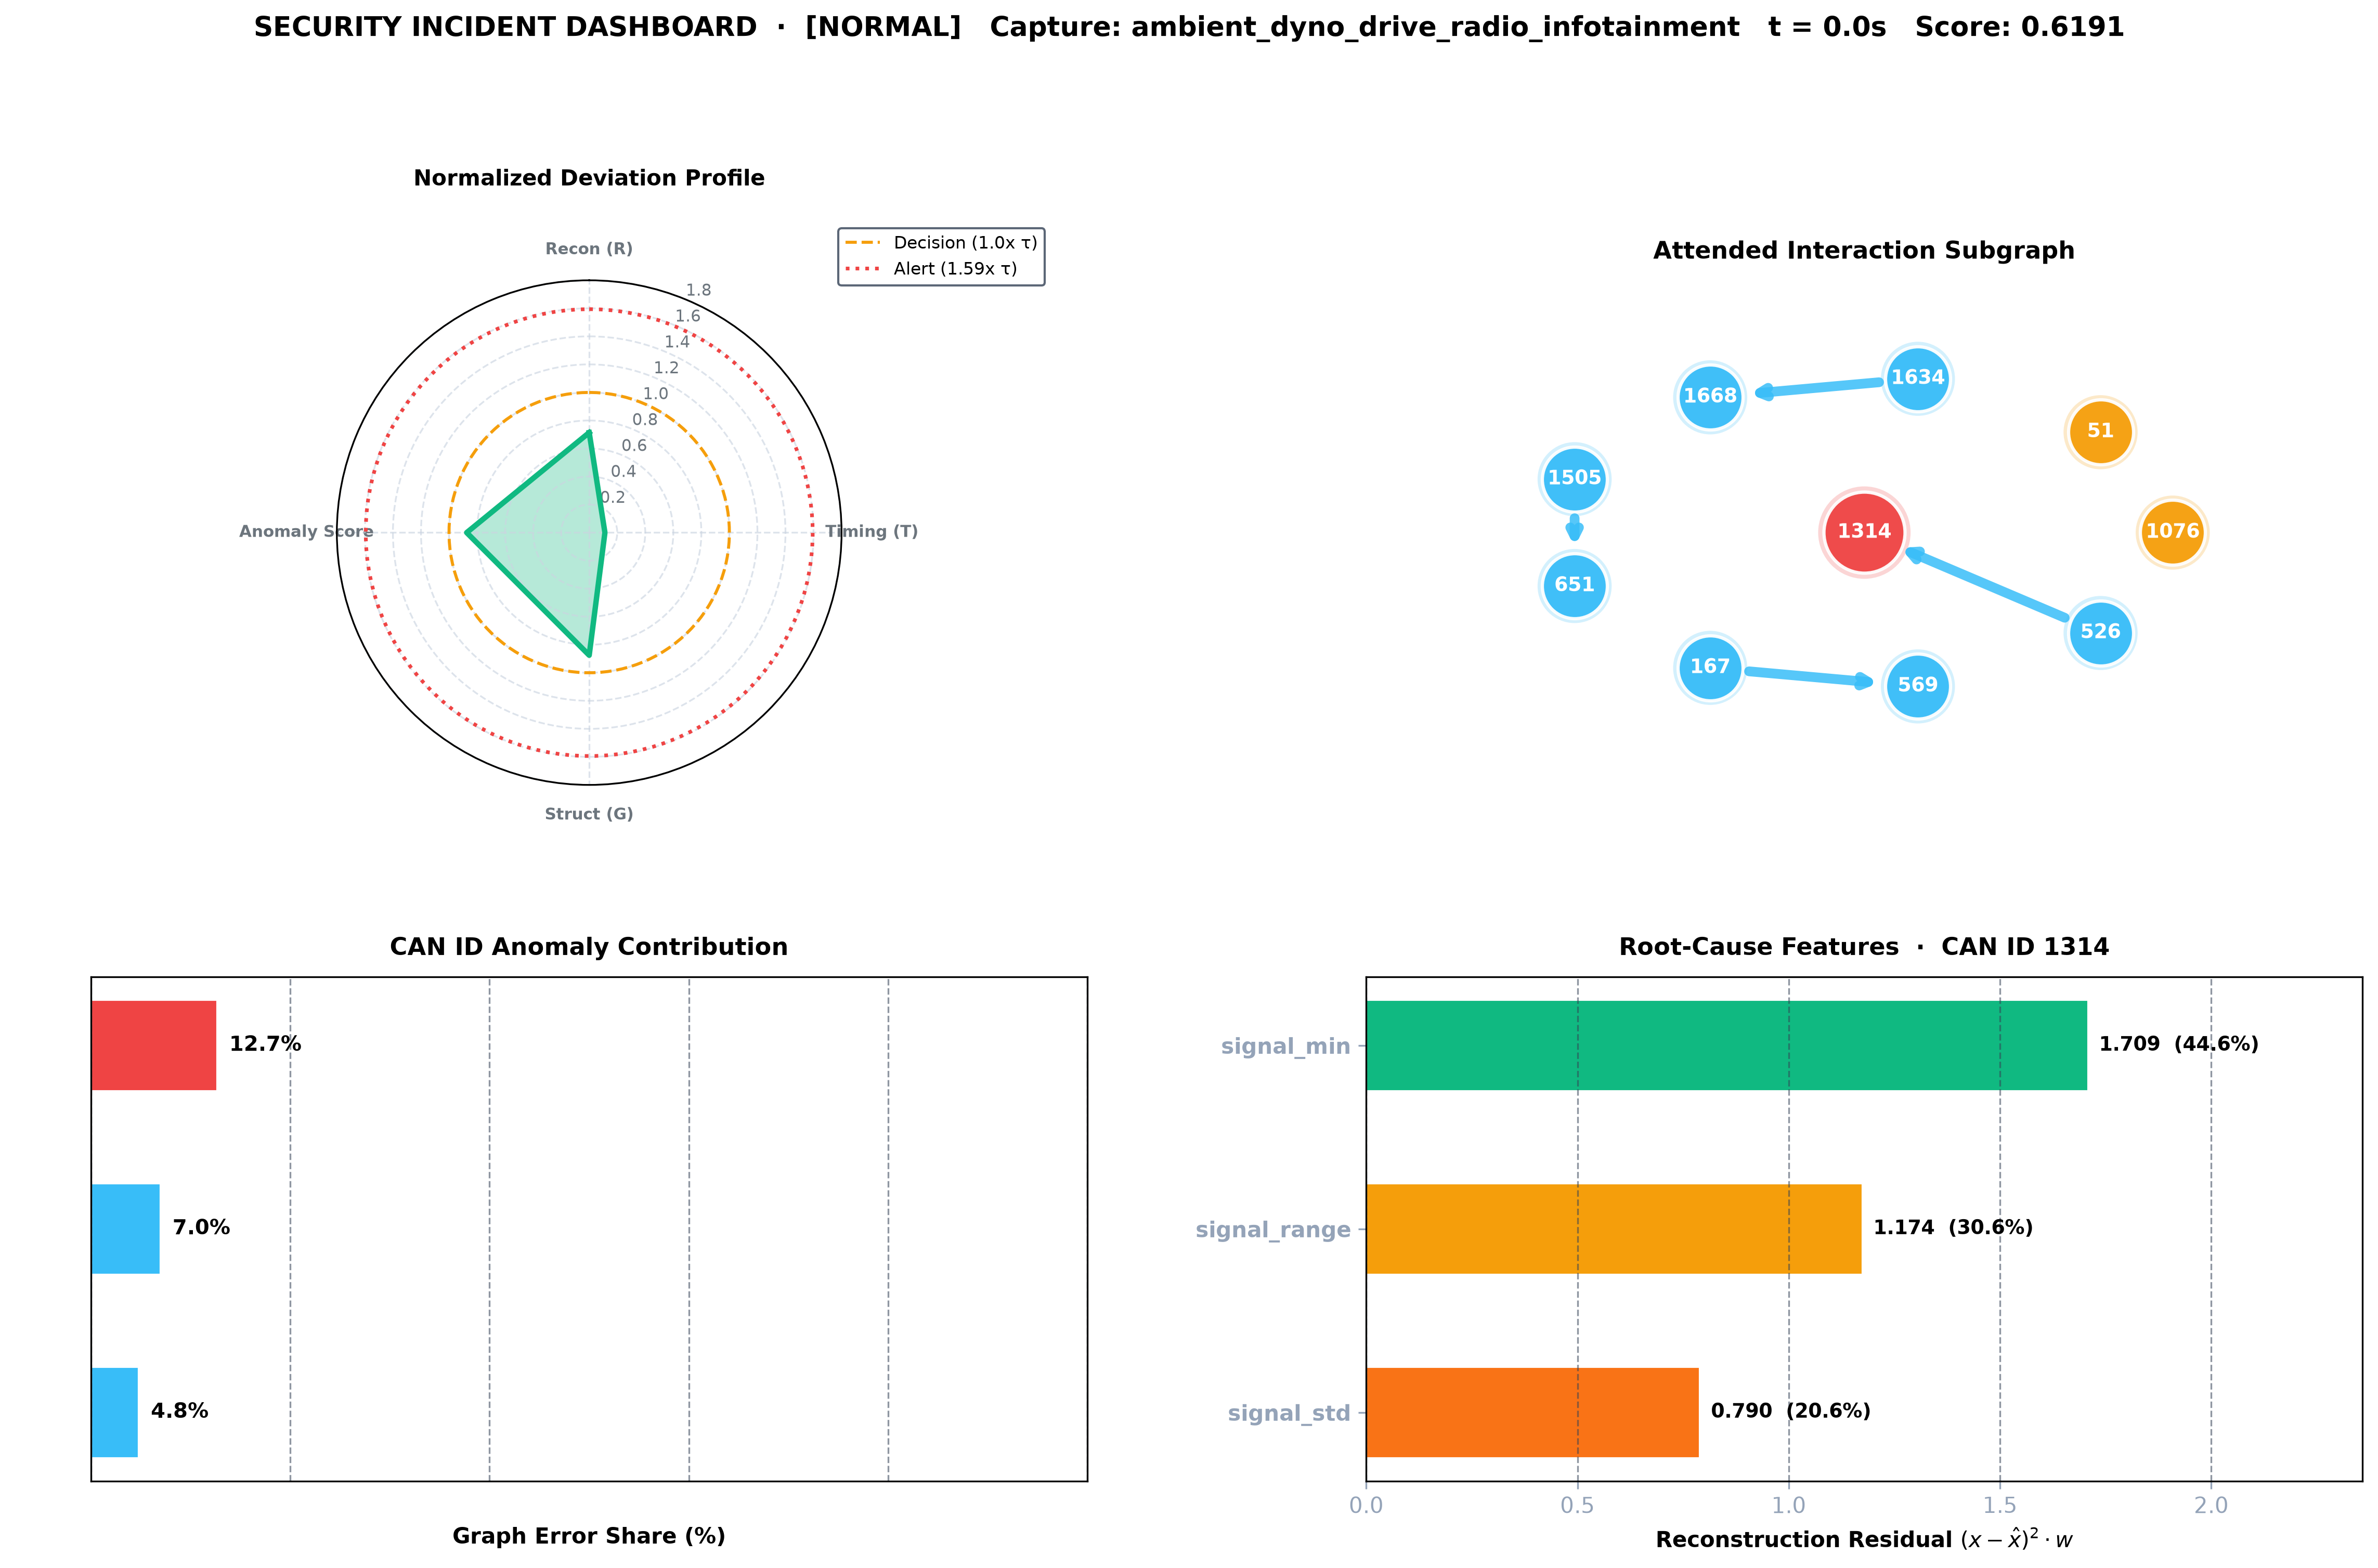

In [32]:
from IPython.display import Image, display
display(Image(filename=r"d:\git_repos\capstone\graph-transformer\outputs\xai_visuals\incident_05_benign_baseline_ambient_dyno_drive_radio_infotainment_dashboard.png"))
